# JFK Airport Flight Delay Analysis | Portfolio Project (2013)

**Python · Data Cleaning · Exploratory Analysis · Statistical Modeling · Model Validation**

This project analyzes historical JFK flight and weather data from 2013 to examine departure delays, airline and route patterns, and the limits of delay-risk prediction. The notebook covers data preparation, exploratory analysis, weather comparisons, statistical modeling, and model validation.

### Research questions
1. Which routes, airlines and times had more frequent departures at least 15 minutes late?
2. Were extreme delays concentrated on specific days? How did departure delays change by the time flights arrived?
3. How did observed weather conditions line up with delays, and how sensitive are those findings to matching choices?
4. Can information known ahead of departure rank flights by delay risk, and where does that approach fall short?

**Data:** 2013 flight records for JFK departures and historical JFK weather observations. Flights with no measured `dep_delay` are not automatically treated as cancellations. The old Kaggle download link and redistribution terms still need confirmation.

**Important limits:** The flight CSV does not contain independently recorded scheduled departure times. Estimated clock times are derived from the recorded delay and therefore used only for descriptive work. Section 7A checks which flights are excluded by the estimated clock, while Section 7B follows additional losses from missing weather reports or measurements. Weather associations do not establish causation. The Nov–Dec 2013 test window has been reviewed across several versions of this portfolio and is not a new external test.



## 1. Setup and paths

When the full project folder is available, the notebook looks for `requirements.txt` and `notebooks/`, then reads CSVs from `data/`. It can also read files from the saved Windows folder, `I:\Dataset\JFK Airport Webscraping`, or alongside a standalone notebook. Plots and tables are written to the repository when it is detected; when the notebook is run on its own, they are saved next to the local data. Check the paths printed by the first cell before running the analysis.

**Metric:** `late_15 = (dep_delay >= 15)` for flights with a measured departure delay. A missing delay is not proof of cancellation. Historical weather joins are exploratory because the flight file lacks an independently observed scheduled timestamp and the weather timezone has not been verified.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Format statistically small p-values for readers without changing numeric results.
def p_for_display(p):
    if pd.isna(p):
        return "NA"
    return "<0.001" if p < 0.001 else f"{p:.3f}"


# Explicit nanosecond keys avoid deprecated generic NumPy timedelta handling in
# certain pandas/NumPy combinations. Work with timezone-naive source timestamps;
# this does NOT verify the correct weather timezone or DST convention.
NS_PER_MINUTE = 60_000_000_000


def shift_naive_datetime_minutes(values, minutes):
    """Shift an existing datetime Series by integer minutes using explicit ns units."""
    ts = pd.to_datetime(values)
    return pd.Series(
        pd.to_datetime(ts.to_numpy(dtype="datetime64[ns]") + np.timedelta64(int(minutes), "m")),
        index=values.index,
        name=values.name,
    )


def merge_weather_asof(left, right, left_time, right_time, tolerance_minutes):
    """Backward as-of match with explicit integer-nanosecond tolerance."""
    l, r = left.copy(), right.copy()
    if l[left_time].isna().any() or r[right_time].isna().any():
        raise ValueError("As-of match needs valid timestamps; filter NaT first")
    if "_asof_ns" in l.columns or "_asof_ns" in r.columns:
        raise ValueError("Temporary join-key name already present")
    l["_asof_ns"] = pd.to_datetime(l[left_time]).to_numpy(dtype="datetime64[ns]").astype("int64")
    r["_asof_ns"] = pd.to_datetime(r[right_time]).to_numpy(dtype="datetime64[ns]").astype("int64")
    result = pd.merge_asof(
        l.sort_values("_asof_ns", kind="stable"),
        r.sort_values("_asof_ns", kind="stable"),
        on="_asof_ns",
        direction="backward",
        tolerance=int(tolerance_minutes) * NS_PER_MINUTE,
    )
    return result.drop(columns="_asof_ns")

plt.rcParams.update({
    "figure.figsize": (9, 5),
    "figure.dpi": 110,
    "savefig.dpi": 140,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})


# Preferred local data location
LOCAL_DATA_DIR = Path(r"I:\Dataset\JFK Airport Webscraping")

# Locate the repository when running from its root or notebooks/
root_candidates = [
    Path.cwd(),
    Path.cwd().parent,
    LOCAL_DATA_DIR,
]

PROJECT_ROOT = next(
    (
        p for p in root_candidates
        if (p / "requirements.txt").is_file()
        and (p / "notebooks").is_dir()
    ),
    None
)

# Support both repository data/ and standalone local CSV files
data_candidates = []

if PROJECT_ROOT is not None:
    data_candidates.extend([
        PROJECT_ROOT / "data",
        PROJECT_ROOT
    ])

data_candidates.extend([
    LOCAL_DATA_DIR / "data",
    LOCAL_DATA_DIR,
    Path.cwd() / "data",
    Path.cwd(),
    Path.cwd().parent / "data",
    Path.cwd().parent,
])

required_files = [
    "jfk_flights.csv",
    "jfk_weather2013_2.csv"
]

DATA_DIR = next(
    (
        p for p in data_candidates
        if all((p / name).is_file() for name in required_files)
    ),
    None
)

if DATA_DIR is None:
    raise FileNotFoundError(
        "Could not find the required JFK CSV files. "
        f"Checked: {[str(p) for p in data_candidates]}"
    )

# Keep analysis outputs inside the project
if PROJECT_ROOT is not None:
    PROJECT_DIR = PROJECT_ROOT
elif DATA_DIR.name.lower() == "data":
    PROJECT_DIR = DATA_DIR.parent
else:
    PROJECT_DIR = DATA_DIR

IMAGES_DIR = PROJECT_DIR / "images"
RESULTS_DIR = PROJECT_DIR / "results"

IMAGES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input files: {DATA_DIR}")
print(f"Project directory: {PROJECT_DIR}")
print(f"Charts: {IMAGES_DIR}")
print(f"Tables: {RESULTS_DIR}")



Input files: I:\Dataset\JFK Airport Webscraping
Project directory: I:\Dataset\JFK Airport Webscraping
Charts: I:\Dataset\JFK Airport Webscraping\images
Tables: I:\Dataset\JFK Airport Webscraping\results


## 2. Load data and check quality

Only the columns needed for the analysis are loaded. NOAA-style weather files contain many additional daily and monthly fields and may require a legacy text encoding.

In [2]:
flight_columns = [
    "year", "month", "day", "dep_time", "dep_delay", "arr_delay", "carrier",
    "flight", "tailnum", "origin", "dest", "distance",
]
weather_columns = [
    "DATE", "STATION", "HOURLYVISIBILITY", "HOURLYWindSpeed", "HOURLYDRYBULBTEMPF", "HOURLYPrecip", "HOURLYRelativeHumidity",
]

flights_raw = pd.read_csv(DATA_DIR / "jfk_flights.csv", usecols=flight_columns)
weather_raw = pd.read_csv(
    DATA_DIR / "jfk_weather2013_2.csv",
    usecols=weather_columns,
    encoding="cp1252",
    low_memory=False,
)

assert flights_raw["origin"].eq("JFK").all(), "Flight file includes non-JFK origins"
assert flights_raw["year"].eq(2013).all(), "Expected only 2013 flights"
assert len(flights_raw) == 111_279, "Source flight count differs from the reviewed project file"
assert len(weather_raw) == 13_424, "Weather observations differ from the reviewed project file"

quality = pd.DataFrame({
    "Metric": ["Flight records", "Flights without departure delay", "Flights without arrival delay",
               "Weather observations", "Weather rows without visibility", "Weather rows without wind speed"],
    "Count": [len(flights_raw), flights_raw.dep_delay.isna().sum(),
              flights_raw.arr_delay.isna().sum(), len(weather_raw),
              weather_raw.HOURLYVISIBILITY.isna().sum(),
              weather_raw.HOURLYWindSpeed.isna().sum()],
})
display(quality)
print("Flight columns:", ", ".join(flights_raw.columns))
print("Weather station codes:", weather_raw.STATION.dropna().unique()[:4])

,Metric,Count
0,Flight records,111279
1,Flights without departure delay,1863
2,Flights without arrival delay,2200
3,Weather observations,13424
4,Weather rows without visibility,2315
5,Weather rows without wind speed,367


Flight columns: year, month, day, dep_time, dep_delay, arr_delay, carrier, tailnum, flight, origin, dest, distance
Weather station codes: ['WBAN:94789']


## 3. Prepare flight-level analysis data

`dep_delay` and `arr_delay` are in **minutes**; negative values indicate early departures/arrivals. A missing `dep_delay` is excluded from on-time-rate denominators.

The supplied flight file omits the explicit scheduled-departure-time column. For rows with actual departure time and delay, the **scheduled clock-time proxy** is reconstructed as `actual clock time − departure delay (modulo 24 hours)`. This is a derived approximation used for hourly analysis and linking weather to the *intended* departure time, not a directly observed schedule. `24:00` is handled as midnight.

**Time-provenance caveat:** The saved `jfk_flights.csv` lacks an independently recorded scheduled departure clock. An outcome-derived reconstructed *clock-time proxy* is used for descriptive hourly grouping and weather matching only. It may misplace dates for overnight departures and must **never** be a prospective model feature. An optional schedule-source audit follows; results here do not claim verified real schedules.


In [3]:
flights = flights_raw.copy()
flights["flight_date"] = pd.to_datetime(flights[["year", "month", "day"]])
flights["late_15"] = flights["dep_delay"].ge(15)
flights["weekday"] = flights["flight_date"].dt.day_name()

clock = pd.to_numeric(flights["dep_time"], errors="coerce")
clock_hours = np.floor(clock / 100)
clock_minutes = clock % 100
valid_clock = (
    clock.notna() & clock_hours.between(0, 24) & clock_minutes.between(0, 59)
    & ((clock_hours < 24) | (clock_minutes == 0))
)
actual_minutes = (clock_hours * 60 + clock_minutes).where(valid_clock)
# Date-unaware local-clock proxy only: overnight date offset is not identified.
raw_scheduled_minutes = actual_minutes - flights['dep_delay']
flights['schedule_proxy_day_wrap'] = raw_scheduled_minutes.lt(0) | raw_scheduled_minutes.ge(1440)
# Calendar date for a wrap cannot be inferred from this source. Do not silently shift it.
scheduled_minutes = raw_scheduled_minutes.mod(1440)
flights["scheduled_hour"] = np.floor(scheduled_minutes / 60).astype("Int64")
flights["scheduled_departure_est"] = (
    flights["flight_date"] + pd.to_timedelta(scheduled_minutes, unit="m")
)

# Only recorded departures are eligible for delay metrics.
observed = flights.loc[flights["dep_delay"].notna()].copy()
observed["late_15"] = observed["dep_delay"] >= 15

print('Ambiguous cross-midnight outcome-derived schedule proxies:',
      int(flights['schedule_proxy_day_wrap'].sum()))
print(f"Total flights: {len(flights):,}")
print(f"Recorded departure delays: {len(observed):,}")
print(f"Missing departure delay: {flights.dep_delay.isna().sum():,}")
print(f"Overall 15+ minute late rate: {observed.late_15.mean():.1%}")
print(f"Median departure delay: {observed.dep_delay.median():.1f} minutes")

Ambiguous cross-midnight outcome-derived schedule proxies: 811
Total flights: 111,279
Recorded departure delays: 109,416
Missing departure delay: 1,863
Overall 15+ minute late rate: 21.3%
Median departure delay: -1.0 minutes


## 3A. Independently recorded scheduled departure time — optional source audit

The historical `jfk_flights.csv` does **not** contain independently observed `sched_dep_time`. Its `hour` and `minute` fields describe the **actual departure clock**, not verified planned times. Reconstructing a planned clock from `dep_time − dep_delay` is **outcome-derived** and not allowed for prospective prediction.

If an independently obtained official `nycflights13` `flights.csv` with `sched_dep_time` is placed at `data/nycflights13_flights.csv` (or in the user-provided local data folder), the cell below attempts a **unique-key-only** merge and reports coverage. It never performs an ambiguous many-to-many join. Schedule enrichment is used for descriptive charts and historical-weather time alignment **only if >=95%** of measured departures match unambiguously. Otherwise the prior estimated-clock analysis is preserved and clearly labeled. No official source has been silently downloaded or fabricated. For future production features, schedule data must be available independently before the prediction cutoff.

Official field documentation: https://github.com/tidyverse/nycflights13/blob/main/R/flights.R .

In [4]:
# Optional schedule enrichment; never claim that a derived estimate is an independently observed schedule.
optional_schedule_candidates = [DATA_DIR / 'nycflights13_flights.csv', PROJECT_DIR / 'data' / 'nycflights13_flights.csv']
official_schedule_path = next((p for p in optional_schedule_candidates if p.is_file()), None)
schedule_audit = {'independent_file_found': False, 'unique_match_fraction': 0., 'used_in_analysis': False}
if official_schedule_path is not None:
    import warnings
    keys = ['year', 'month', 'day', 'carrier', 'flight', 'tailnum', 'origin', 'dest', 'dep_time', 'dep_delay']
    source_cols = keys + ['sched_dep_time']
    official = pd.read_csv(official_schedule_path, usecols=lambda s: s in source_cols, low_memory=False)
    if set(source_cols).issubset(official.columns):
        # On-time departure duplicates are excluded on both sides rather than arbitrarily matched.
        local_src = pd.read_csv(DATA_DIR / 'jfk_flights.csv', usecols=keys)
        local_src['__row_id'] = np.arange(len(local_src))
        official = official.loc[official.origin.eq('JFK'), source_cols].copy()
        valid_local = ~local_src.duplicated(keys, keep=False)
        valid_official = ~official.duplicated(keys, keep=False)
        official = official.loc[valid_official].copy()
        match = (local_src.loc[valid_local].merge(official, on=keys, how='left', validate='one_to_one'))
        source_times = pd.Series(np.nan,index=np.arange(len(local_src)))
        source_times.loc[match['__row_id'].to_numpy()] = match['sched_dep_time'].to_numpy()
        has_time = source_times.notna()
        valid_times = ((source_times//100).between(0,23) & (source_times%100).between(0,59)) | source_times.eq(2400)
        schedule_audit = {'independent_file_found':True,'source_path':str(official_schedule_path),
                          'unique_match_fraction':float((has_time & valid_times).sum()/len(local_src)),
                          'used_in_analysis':False,'source_unique_rows':len(official)}
        if schedule_audit['unique_match_fraction'] >= 0.95:
            # Assign by physical source-row order without contaminating prediction matrices.
            minute_of_day = ((source_times//100)*60 + (source_times%100)).where(valid_times)
            real_timestamp = (flights.flight_date + pd.to_timedelta(minute_of_day,unit='m')).to_numpy()
            flights['scheduled_departure_est'] = pd.to_datetime(real_timestamp)
            flights['scheduled_hour'] = pd.Series(minute_of_day//60, index=flights.index).astype('Int64') % 24
            observed['scheduled_departure_est'] = flights.loc[observed.index,'scheduled_departure_est']
            observed['scheduled_hour'] = flights.loc[observed.index,'scheduled_hour']
            flights['schedule_proxy_day_wrap'] = False  # official schedule is independent of outcome-derived clock
            observed['schedule_proxy_day_wrap'] = False
            schedule_audit['used_in_analysis']=True
            print('Independent schedules successfully joined; re-run all cells to update dependent weather results.')
        else:
            print('Insufficient unique schedule coverage; retain original outcome-derived time proxy.')
    else:
        print('Optional source missing required identifying fields; not joined.')
else:
    print('Independent scheduled-departure source unavailable; no schedule backfill performed.')
print('Schedule source audit:', schedule_audit)

Independent scheduled-departure source unavailable; no schedule backfill performed.
Schedule source audit: {'independent_file_found': False, 'unique_match_fraction': 0.0, 'used_in_analysis': False}


## 4. Airline performance

Compare carriers using both **flight counts** and late-departure rates. Only carriers with at least **1,000 observed departures** appear in the ranking to avoid overinterpreting very small samples. Carrier codes, rather than potentially outdated airline names, are preserved from the source data.

,observed_flights,mean_delay_min,median_delay_min,late_15_rate
carrier,,,,
9E,13844,19.002,-1.0,0.283
EV,1326,18.520,-2.0,0.260
B6,41761,12.757,-1.0,0.237
MQ,6866,13.200,-2.0,0.232
VX,3575,13.279,0.0,0.186
AA,13642,10.302,-2.0,0.177
DL,20601,8.333,-2.0,0.166
UA,4490,7.900,-2.0,0.152
US,2969,5.867,-2.0,0.130


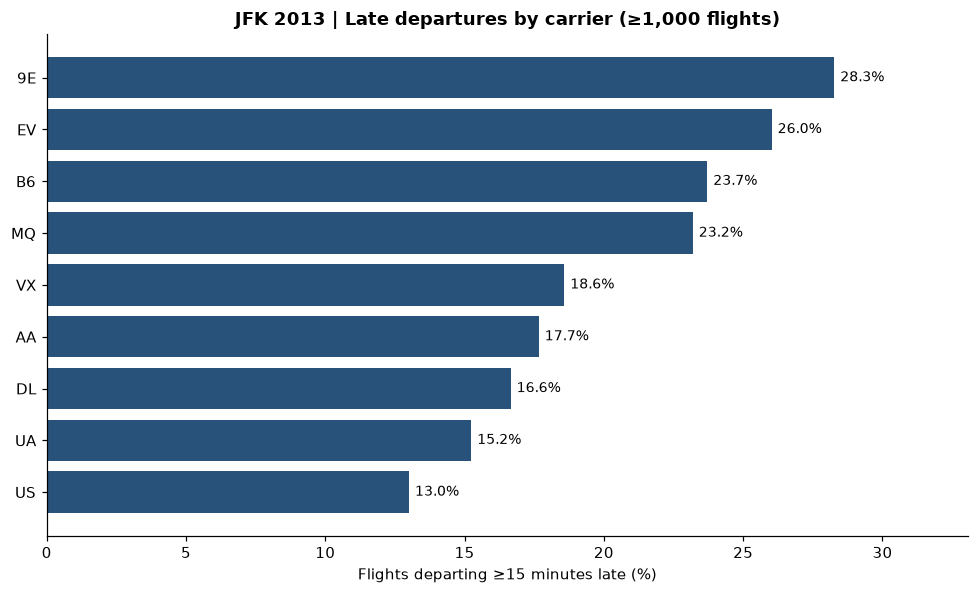

In [5]:
carrier_summary = (
    observed.groupby("carrier")
    .agg(
        observed_flights=("dep_delay", "size"),
        mean_delay_min=("dep_delay", "mean"),
        median_delay_min=("dep_delay", "median"),
        late_15_rate=("late_15", "mean"),
    )
    .sort_values("late_15_rate", ascending=False)
)
display(carrier_summary.round(3))

eligible_carriers = carrier_summary.loc[carrier_summary.observed_flights >= 1_000]
assert not eligible_carriers.empty
plot_carriers = eligible_carriers.sort_values("late_15_rate")
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.barh(plot_carriers.index, 100 * plot_carriers.late_15_rate, color="#28527a")
ax.bar_label(bars, fmt="%.1f%%", padding=4, fontsize=9)
ax.set_xlabel("Flights departing ≥15 minutes late (%)")
ax.set_title("JFK 2013 | Late departures by carrier (≥1,000 flights)", weight="bold")
ax.set_xlim(0, max(100 * plot_carriers.late_15_rate) * 1.17)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "01_carrier_late_rate.png", bbox_inches="tight")
plt.show()

## 5. Temporal patterns: month and outcome-derived scheduled-clock proxy

Monthly patterns are descriptive rather than seasonally adjusted. Hourly results use **outcome-derived scheduled-clock proxy** so delayed flights are not grouped by their *late actual departure time*. Hours with fewer than 500 observed departures are omitted from the hour plot.

,observed_flights,late_15_rate,median_delay_min
month,,,
1,9061,0.170,-2.0
2,8028,0.216,-1.0
3,9512,0.205,-2.0
4,9034,0.212,-2.0
5,9289,0.221,-1.0
6,9229,0.290,0.0
7,9812,0.326,1.0
8,9890,0.237,-1.0
9,8816,0.146,-3.0


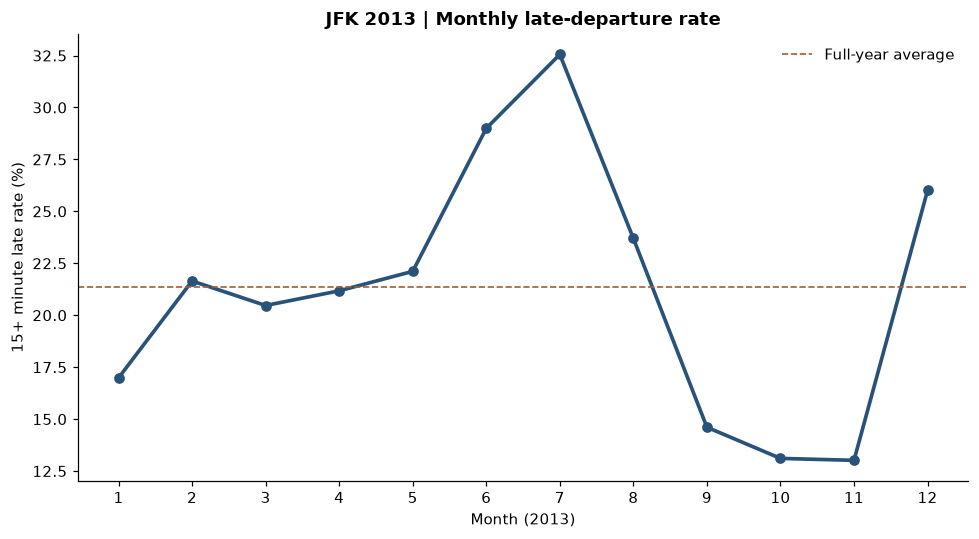

In [6]:
month_summary = observed.groupby("month").agg(
    observed_flights=("dep_delay", "size"),
    late_15_rate=("late_15", "mean"),
    median_delay_min=("dep_delay", "median"),
)
display(month_summary.round(3))

fig, ax = plt.subplots()
ax.plot(month_summary.index, month_summary.late_15_rate * 100,
        marker="o", linewidth=2.4, color="#28527a")
ax.axhline(observed.late_15.mean() * 100, linestyle="--", linewidth=1.1,
           color="#a55c36", label="Full-year average")
ax.set(xticks=range(1, 13), xlabel="Month (2013)", ylabel="15+ minute late rate (%)")
ax.set_title("JFK 2013 | Monthly late-departure rate", weight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "02_monthly_late_rate.png", bbox_inches="tight")
plt.show()

,observed_flights,late_15_rate
scheduled_hour,,
5,746,0.055
6,6199,0.073
7,6973,0.075
8,10644,0.107
9,6414,0.131
10,4634,0.131
11,2950,0.147
12,4987,0.156
13,4219,0.194


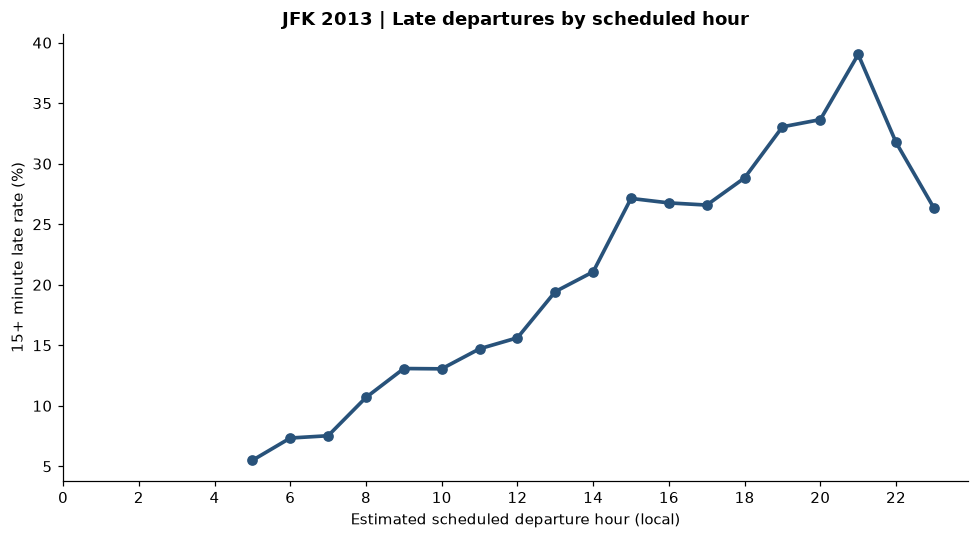

In [7]:
hour_summary = (
    observed.dropna(subset=["scheduled_hour"])
    .groupby("scheduled_hour")
    .agg(observed_flights=("dep_delay", "size"), late_15_rate=("late_15", "mean"))
)
hour_summary = hour_summary[hour_summary.observed_flights >= 500]
display(hour_summary.round(3))

fig, ax = plt.subplots()
ax.plot(hour_summary.index.astype(int), hour_summary.late_15_rate * 100,
        marker="o", linewidth=2.4, color="#28527a")
ax.set(xlabel="Estimated scheduled departure hour (local)",
       ylabel="15+ minute late rate (%)")
ax.set_xticks(range(0, 24, 2))
ax.set_title("JFK 2013 | Late departures by scheduled hour", weight="bold")
fig.tight_layout()
fig.savefig(IMAGES_DIR / "03_scheduled_hour_late_rate.png", bbox_inches="tight")
plt.show()

## 6. Departure vs. arrival delay

`dep_delay − arr_delay` is the **change in recorded lateness**, not an exact measure of time saved in the air. A positive value means the flight arrived less late than it departed. The chart uses a reproducible sample for readability; summary statistics use **all rows with both measurements**.

,Metric,Value
0,Flights with both measures,"109,079"
1,Correlation (dep vs. arr delay),0.902
2,Median change in lateness (minutes),8.0
3,Initially late flights,"23,209"
4,Initially late flights with ≥15 min recovery,32.8%


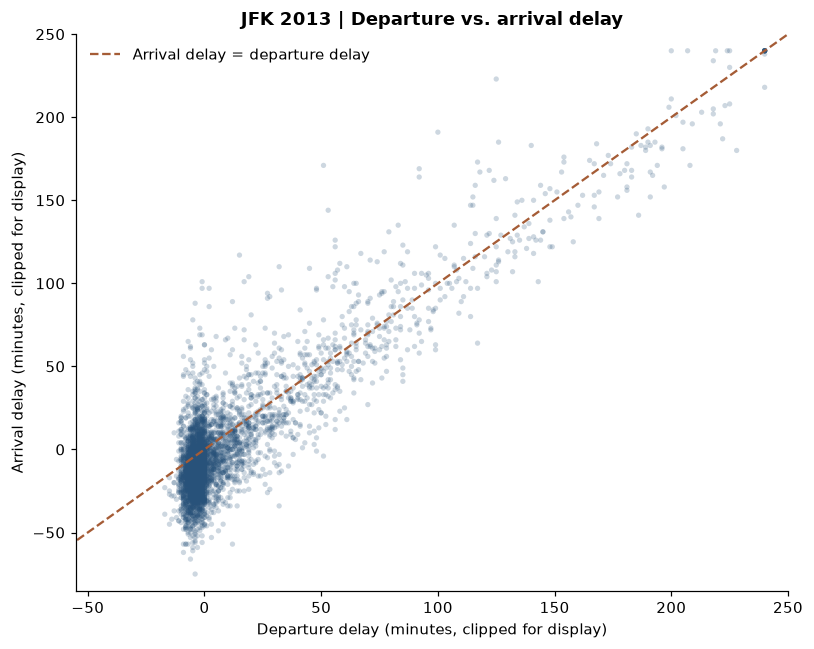

In [8]:
paired = observed.dropna(subset=["arr_delay"]).copy()
paired["delay_change_min"] = paired["dep_delay"] - paired["arr_delay"]
initially_late = paired.loc[paired.dep_delay >= 15].copy()
recovered_15_share = (initially_late.delay_change_min >= 15).mean()

pair_metrics = pd.DataFrame({
    "Metric": ["Flights with both measures", "Correlation (dep vs. arr delay)",
               "Median change in lateness (minutes)", "Initially late flights",
               "Initially late flights with ≥15 min recovery"],
    "Value": [f"{len(paired):,}", f"{paired.dep_delay.corr(paired.arr_delay):.3f}",
              f"{paired.delay_change_min.median():.1f}",
              f"{len(initially_late):,}", f"{recovered_15_share:.1%}"],
})
display(pair_metrics)

sample = paired.sample(min(4_000, len(paired)), random_state=42)
fig, ax = plt.subplots(figsize=(7.5, 6))
ax.scatter(sample.dep_delay.clip(-50, 240), sample.arr_delay.clip(-80, 240),
           s=12, alpha=0.23, color="#28527a", edgecolors="none")
ax.plot([-80, 250], [-80, 250], ls="--", color="#a55c36", lw=1.5,
        label="Arrival delay = departure delay")
ax.set_xlim(-55, 250); ax.set_ylim(-85, 250)
ax.set(xlabel="Departure delay (minutes, clipped for display)",
       ylabel="Arrival delay (minutes, clipped for display)")
ax.set_title("JFK 2013 | Departure vs. arrival delay", weight="bold")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(IMAGES_DIR / "04_departure_arrival_delay.png", bbox_inches="tight")
plt.show()

## 7. Historical weather: cleaning and time matching

Each flight is linked to the latest weather report recorded within 90 minutes **before** its estimated scheduled departure. This is an exploratory match, not a reconstruction of the actual weather available to a dispatcher.

The saved weather CSV has no duplicate timestamps. The code checks again in case a different copy is used. Visibility and precipitation need some string cleaning because observations include flags and trace values.

The bigger problem is the flight clock. The original file has no independent scheduled departure time. Subtracting `dep_delay` from the actual clock time can cross midnight without establishing the correct calendar date. Those ambiguous records are excluded from the weather join; Section 7A compares them with retained flights. The weather file's timezone and daylight-saving convention have also not been verified.

Later sections compare weather groups and vary the matching window; these are sensitivity checks, not proof that weather caused a delay.

Section 7A examines flights excluded by the clock rule; Section 7B follows the additional losses when a preceding weather report or required measurements are unavailable. The adjusted weather model uses only flights with both visibility and wind readings.


In [9]:
weather = weather_raw.copy()
weather["weather_time"] = pd.to_datetime(
    weather["DATE"], format="%m/%d/%y %H:%M", errors="coerce"
)

# Numeric prefix supports entries like '1.00V' but preserves NA if no number exists.
weather["visibility_mi"] = pd.to_numeric(
    weather["HOURLYVISIBILITY"].astype("string")
    .str.extract(r"^\s*([+-]?(?:\d+\.?\d*|\.\d+))", expand=False),
    errors="coerce",
)
weather["wind_mph"] = pd.to_numeric(weather["HOURLYWindSpeed"], errors="coerce")
weather["temperature_f"] = pd.to_numeric(weather["HOURLYDRYBULBTEMPF"], errors="coerce")
# NOAA hourly precipitation: T indicates trace, blank is unknown (not zero).
raw_precip = weather["HOURLYPrecip"].astype("string").str.strip()
weather["precip_in"] = pd.to_numeric(
    raw_precip.str.extract(r"^([0-9]+(?:\.[0-9]+)?)", expand=False), errors="coerce"
)
weather.loc[raw_precip.eq("T").fillna(False), "precip_in"] = 0.0
weather["precip_any"] = pd.Series(np.nan, index=weather.index)
weather.loc[weather["precip_in"].notna(), "precip_any"] = (
    (weather.loc[weather["precip_in"].notna(), "precip_in"] > 0)
    | raw_precip.loc[weather["precip_in"].notna()].eq("T")
).astype(int)
weather["humidity_pct"] = pd.to_numeric(weather["HOURLYRelativeHumidity"], errors="coerce")
weather.loc[~weather["humidity_pct"].between(0, 100), "humidity_pct"] = np.nan
for col in ["visibility_mi", "wind_mph"]:
    weather.loc[weather[col] < 0, col] = np.nan
# Date is an unzoned timestamp in the supplied file; its timezone/DST remains unverified.
# This historical input has NO duplicated timestamps, but future copies might.
weather = weather.dropna(subset=['weather_time']).copy()
duplicate_rows = int(weather.duplicated('weather_time',keep=False).sum())
duplicate_times = int(weather.loc[weather.duplicated('weather_time',keep=False),'weather_time'].nunique())
quality_fields=['visibility_mi','wind_mph','temperature_f','precip_in','humidity_pct']
if duplicate_times:
    # Select the most complete record deterministically, not the arbitrarily last row.
    # Remaining disagreement across duplicate observations needs source-level adjudication.
    weather['_quality_fields_present']=weather[quality_fields].notna().sum(axis=1)
    weather=weather.sort_values(['weather_time','_quality_fields_present'],ascending=[True,False],kind='stable')
    weather=weather.drop_duplicates('weather_time',keep='first').drop(columns='_quality_fields_present')
else:
    weather=weather.sort_values('weather_time').copy()
assert weather.weather_time.is_unique

# Exclude outcome-derived schedule timestamps that cross the recorded date boundary;
# their true calendar day cannot be established from this legacy CSV.
wrap_ambiguous = int(observed['schedule_proxy_day_wrap'].sum()) if not schedule_audit.get('used_in_analysis',False) else 0
flight_times = observed.dropna(subset=['scheduled_departure_est']).copy()
if not schedule_audit.get('used_in_analysis',False):
    flight_times=flight_times.loc[~flight_times.schedule_proxy_day_wrap.fillna(True)].copy()
weather_audit = pd.DataFrame([{
    'Original weather rows':len(weather_raw),
    'Unique weather timestamps':len(weather),
    'Duplicate weather rows (original)':duplicate_rows,
    'Duplicate timestamps (original)':duplicate_times,
    'Ambiguous date-wrap flight rows withheld':wrap_ambiguous,
    'Flights eligible for matching':len(flight_times),
    'Independent scheduled timestamp in use':bool(schedule_audit.get('used_in_analysis',False)),
    'Weather timezone/DST externally verified':False
}])
display(weather_audit)
weather_audit.to_csv(RESULTS_DIR/'weather_data_quality_audit.csv',index=False)
print('Weather timestamps remain timezone-naive. This is a descriptive sensitivity analysis, not causal attribution.')
flight_times = flight_times.sort_values("scheduled_departure_est")
wx = merge_weather_asof(
    flight_times,
    weather[["weather_time", "visibility_mi", "wind_mph", "temperature_f", "precip_in", "precip_any", "humidity_pct"]],
    left_time="scheduled_departure_est",
    right_time="weather_time",
    tolerance_minutes=90,
)
wx["observation_age_min"] = (
    wx.scheduled_departure_est - wx.weather_time
).dt.total_seconds() / 60
assert wx.observation_age_min.dropna().between(0, 90).all()

coverage = pd.DataFrame({
    "Measure": ["Flights with estimated schedule", "Flights matched to an observation",
                "Matched flights with visibility", "Matched flights with wind speed",
                "Maximum matched-observation age (minutes)"],
    "Value": [len(wx), wx.weather_time.notna().sum(),
              wx.visibility_mi.notna().sum(), wx.wind_mph.notna().sum(),
              round(wx.observation_age_min.max(), 1)],
})
display(coverage)
# Diagnostic only: do assumed +-1 hour clock differences change coverage?
# These offsets are alternative interpretations, NOT verified timezone corrections.
clock_sensitivity=[]
for clock_shift in [-60,0,60]:
    shifted=weather[['weather_time','visibility_mi','wind_mph']].copy()
    shifted['weather_time'] = shift_naive_datetime_minutes(shifted['weather_time'], clock_shift)
    shifted=shifted.sort_values('weather_time')
    trial=merge_weather_asof(flight_times[['scheduled_departure_est','late_15']],
        shifted,left_time='scheduled_departure_est',right_time='weather_time',
        tolerance_minutes=90)
    visible=trial.loc[trial.visibility_mi.notna()].copy()
    low=visible.visibility_mi.lt(3)
    contrast=(visible.loc[low,'late_15'].mean()-visible.loc[~low,'late_15'].mean()) if low.any() and (~low).any() else np.nan
    clock_sensitivity.append({'Assumed weather clock offset (min)':clock_shift,
        'Weather match coverage':trial.weather_time.notna().mean(),
        'Valid visibility flights':len(visible),
        'Low-vs-higher visibility gap (pp)':100*contrast})
clock_sensitivity=pd.DataFrame(clock_sensitivity)
display(clock_sensitivity.round(3))
clock_sensitivity.to_csv(RESULTS_DIR/'weather_clock_offset_sensitivity.csv',index=False)


,Original weather rows,Unique weather timestamps,Duplicate weather rows (original),Duplicate timestamps (original),Ambiguous date-wrap flight rows withheld,Flights eligible for matching,Independent scheduled timestamp in use,Weather timezone/DST externally verified
0,13424,13424,0,0,811,108605,False,False


Weather timestamps remain timezone-naive. This is a descriptive sensitivity analysis, not causal attribution.


,Measure,Value
0,Flights with estimated schedule,108605.0
1,Flights matched to an observation,108605.0
2,Matched flights with visibility,88356.0
3,Matched flights with wind speed,108104.0
4,Maximum matched-observation age (minutes),60.0


,Assumed weather clock offset (min),Weather match coverage,Valid visibility flights,Low-vs-higher visibility gap (pp)
0,-60,1.0,88481,10.982
1,0,1.0,88356,12.795
2,60,1.0,88987,14.896


## 7A. Weather-matching selection bias

This section identifies flights excluded by the weather time-matching rule. The departure date becomes uncertain when subtracting the recorded delay crosses midnight, so these flights are not included in the main weather sample.

That exclusion matters because a flight with a very long delay is more likely to cross a date boundary. In other words, the matching rule itself can filter out unusually late flights. Retained and excluded flights are compared by late-departure rate, delay magnitude, month, and carrier. This is a **diagnostic for selection bias**, not an estimate of how weather affects all JFK flights.

The comparison uses only rows with measured `dep_delay`. Records without a usable departure clock, if present, are reported separately. `Eligible for time matching` also does **not** mean a flight found a usable weather observation within 90 minutes.


,clock_group,flights,late_15_count,late_15_rate,median_delay_min,p90_delay_min,late_60_rate,late_15_ci_lo,late_15_ci_hi
0,Eligible for clock match,108605,22680,0.209,-1.0,44.0,0.074,0.206,0.211
1,Excluded: date boundary,811,667,0.822,92.0,246.0,0.628,0.795,0.847


,month,flights,excluded,excluded_share,late_rate
0,1,9061,40,0.004,0.170
1,2,8028,44,0.005,0.216
2,3,9512,78,0.008,0.205
3,4,9034,77,0.009,0.212
4,5,9289,60,0.006,0.221
5,6,9229,121,0.013,0.290
6,7,9812,165,0.017,0.326
7,8,9890,93,0.009,0.237
8,9,8816,22,0.002,0.146
9,10,9108,8,0.001,0.131


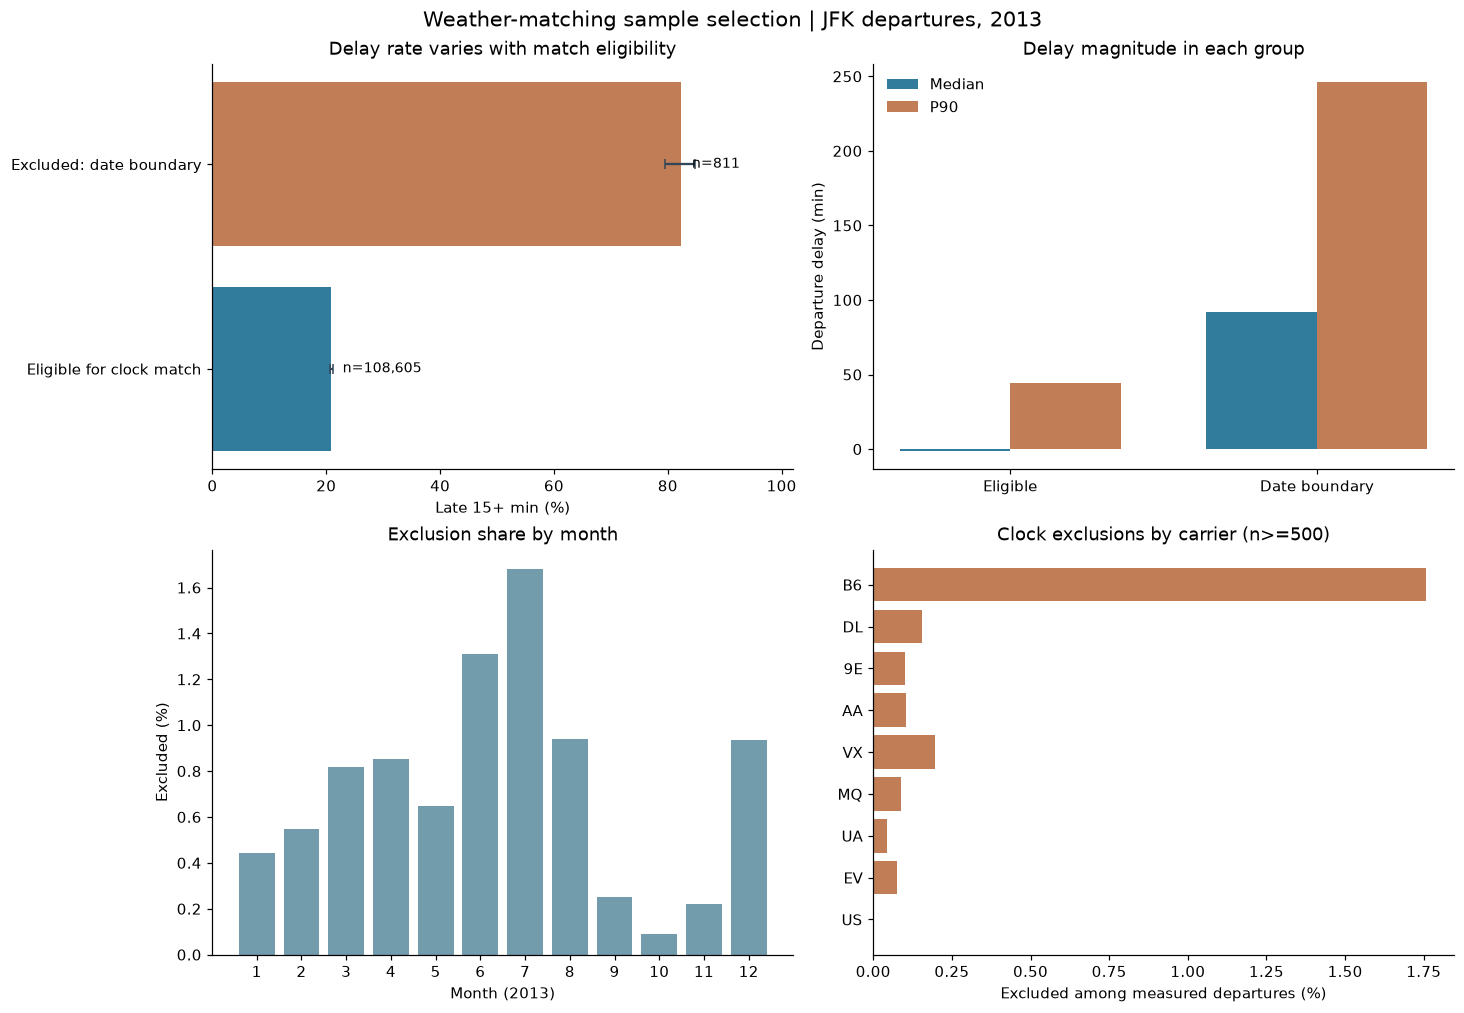

Eligible: 20.9% late; date-boundary excluded: 82.2% late.
These groups differ systematically. Subsequent weather results describe the retained sample only.


In [10]:
# Which measured departures were actually eligible for the Section 7 weather join?
from statsmodels.stats.proportion import proportion_confint

selection = observed[['flight_date', 'month', 'carrier', 'dep_delay', 'late_15',
                      'schedule_proxy_day_wrap']].copy()
selection['eligible_weather_clock'] = selection.index.isin(flight_times.index)
selection['clock_group'] = np.where(
    selection['eligible_weather_clock'], 'Eligible for clock match',
    np.where(selection['schedule_proxy_day_wrap'].fillna(False),
             'Excluded: date boundary', 'Excluded: other clock issue')
)

weather_selection_summary = (
    selection.groupby('clock_group', observed=True)
    .agg(flights=('late_15','size'),
         late_15_count=('late_15','sum'),
         late_15_rate=('late_15','mean'),
         median_delay_min=('dep_delay','median'),
         p90_delay_min=('dep_delay',lambda s: s.quantile(.90)),
         late_60_rate=('dep_delay',lambda s: s.ge(60).mean()))
    .reset_index()
)
lo, hi = proportion_confint(weather_selection_summary['late_15_count'],
                            weather_selection_summary['flights'],
                            alpha=.05,method='wilson')
weather_selection_summary['late_15_ci_lo'] = lo
weather_selection_summary['late_15_ci_hi'] = hi
assert int(weather_selection_summary.flights.sum()) == len(observed)
assert int(selection.eligible_weather_clock.sum()) == len(flight_times)
weather_selection_summary.to_csv(RESULTS_DIR/'weather_selection_bias_summary.csv',index=False)
display(weather_selection_summary.round(3))

# Fraction excluded in each month / airline. These are shares of measured flights,
# not shares of the previously matched weather observations.
selection['excluded_clock'] = ~selection['eligible_weather_clock']
weather_exclusion_month = (selection.groupby('month')
    .agg(flights=('excluded_clock','size'),excluded=('excluded_clock','sum'),
         excluded_share=('excluded_clock','mean'),late_rate=('late_15','mean'))
    .reset_index())
weather_exclusion_carrier = (selection.groupby('carrier')
    .agg(flights=('excluded_clock','size'),excluded=('excluded_clock','sum'),
         excluded_share=('excluded_clock','mean'))
    .query('flights >= 500').sort_values('excluded',ascending=False).reset_index())
weather_exclusion_month.to_csv(RESULTS_DIR/'weather_selection_by_month.csv',index=False)
weather_exclusion_carrier.to_csv(RESULTS_DIR/'weather_selection_by_carrier.csv',index=False)
display(weather_exclusion_month.round(3))

fig,axes=plt.subplots(2,2,figsize=(13.2,9.1),constrained_layout=True)
frame=weather_selection_summary.copy()
colors=['#c17e56' if 'Excluded' in x else '#317b9d' for x in frame.clock_group]
# Selected vs omitted groups with Wilson uncertainty and actual sample size
ax=axes[0,0]
values=frame.late_15_rate.to_numpy()*100
err_lo=(frame.late_15_rate-frame.late_15_ci_lo).to_numpy()*100
err_hi=(frame.late_15_ci_hi-frame.late_15_rate).to_numpy()*100
bars=ax.barh(np.arange(len(frame)),values,color=colors)
ax.errorbar(values,np.arange(len(frame)),xerr=[err_lo,err_hi],fmt='none',color='#334657',capsize=3)
ax.set_yticks(np.arange(len(frame)),frame.clock_group)
ax.set(xlabel='Late 15+ min (%)',title='Delay rate varies with match eligibility',xlim=(0,102))
for bar,r in zip(bars,frame.itertuples()):
    ax.text(min(bar.get_width()+2,96),bar.get_y()+bar.get_height()/2,
            f'n={r.flights:,}',va='center',fontsize=9)
# Affected groups' delay sizes, not just the binary indicator
ax=axes[0,1]
x=np.arange(len(frame));w=.36
ax.bar(x-w/2,frame.median_delay_min,width=w,label='Median',color='#317b9d')
ax.bar(x+w/2,frame.p90_delay_min,width=w,label='P90',color='#c17e56')
ax.set_xticks(x,['Eligible' if 'Eligible' in q else 'Date boundary' if 'boundary' in q else 'Other'
                 for q in frame.clock_group]);ax.set(ylabel='Departure delay (min)',title='Delay magnitude in each group')
ax.legend(frameon=False)
# Excluded clock share over the year
ax=axes[1,0]
ax.bar(weather_exclusion_month.month,weather_exclusion_month.excluded_share*100,color='#729bab')
ax.set(xticks=list(range(1,13)),xlabel='Month (2013)',ylabel='Excluded (%)',title='Exclusion share by month')
# Where the excluded clock records are concentrated
ax=axes[1,1]
view=weather_exclusion_carrier.head(9).iloc[::-1]
ax.barh(view.carrier,view.excluded_share*100,color='#c17e56')
ax.set(xlabel='Excluded among measured departures (%)',title='Clock exclusions by carrier (n>=500)')
fig.suptitle('Weather-matching sample selection | JFK departures, 2013',fontsize=14)
fig.savefig(IMAGES_DIR/'38_weather_selection_bias.png',bbox_inches='tight')
plt.show()

if len(frame)>1:
    rate_eligible = frame.loc[frame.clock_group.eq('Eligible for clock match'),'late_15_rate']
    rate_excluded = frame.loc[frame.clock_group.eq('Excluded: date boundary'),'late_15_rate']
    if len(rate_eligible) and len(rate_excluded):
        print(f'Eligible: {rate_eligible.iloc[0]:.1%} late; date-boundary excluded: {rate_excluded.iloc[0]:.1%} late.')
        print('These groups differ systematically. Subsequent weather results describe the retained sample only.')


## 7B. Weather data completeness and sample attrition

Excluding flights with an uncertain date boundary is only the first step. A flight can pass that screen and still have no weather report within the 90-minute lookback window, or a report that lacks visibility or wind speed. The adjusted weather regression needs **both** measurements.

This check follows the same flights as Section 7, tracks where records are lost, and compares departure-delay rates for flights with and without the necessary weather readings. The groups are observational: a difference does not establish why a weather record is missing or how the full-sample weather effect would change.


,Stage,Flights,% of measured departures,Lost since previous stage
0,Departure delay recorded,109416,100.00,0
1,Clock-eligible for weather join,108605,99.26,811
2,Preceding weather report found (<=90 min),108605,99.26,0
3,Visibility available,88356,80.75,20249
4,Visibility and wind available,88340,80.74,16


,Group,flights,late_rate,median_delay_min
0,At least one unavailable,20265,0.219,-1.0
1,Visibility + wind available,88340,0.207,-2.0


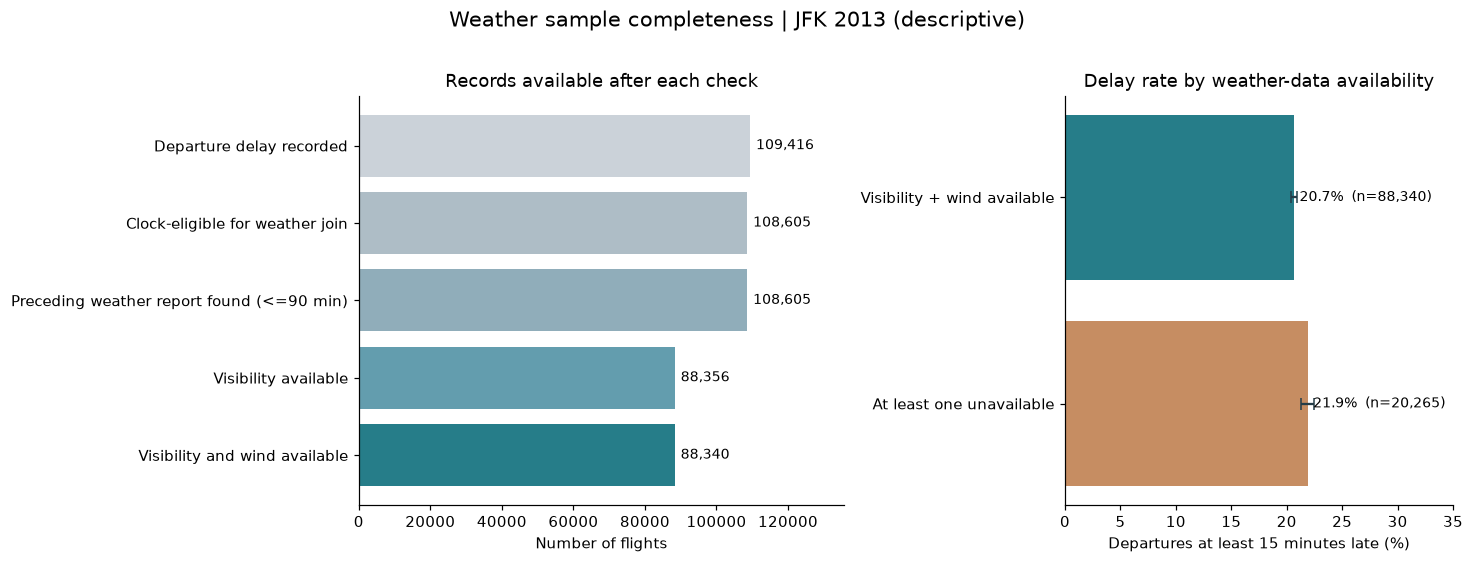

**Sample check.** Out of 108,605 clock-eligible departures, 88,340 (81.3%) have both weather measures. The other 20,265 do not. The observed late rates are 20.7% and 21.9%, respectively (a +1.2 percentage-point difference). These are two differently selected groups, not an estimate of the effect of missing weather data.

In [11]:
# Use the same clock-eligible and already matched flight set as Sections 7 and 12.
from statsmodels.stats.proportion import proportion_confint

assert len(wx) == len(flight_times), 'Unexpected change in the weather-match population'
matched_report = wx['weather_time'].notna()
with_visibility = matched_report & wx['visibility_mi'].notna()
with_both = with_visibility & wx['wind_mph'].notna()

weather_attrition = pd.DataFrame({
    'Stage': [
        'Departure delay recorded',
        'Clock-eligible for weather join',
        'Preceding weather report found (<=90 min)',
        'Visibility available',
        'Visibility and wind available',
    ],
    'Flights': [len(observed), len(wx), int(matched_report.sum()),
                int(with_visibility.sum()), int(with_both.sum())],
})
assert weather_attrition['Flights'].is_monotonic_decreasing
weather_attrition['% of measured departures'] = (100 * weather_attrition['Flights'] / len(observed)).round(2)
weather_attrition['Lost since previous stage'] = (
    weather_attrition['Flights'].shift(1) - weather_attrition['Flights']
).fillna(0).astype(int)
weather_attrition.to_csv(RESULTS_DIR / 'weather_sample_attrition.csv', index=False)
display(weather_attrition)

# Mutually exclusive reasons for non-inclusion among the same clock-eligible cohort.
wx_completeness = wx.copy()
wx_completeness['weather_sample_status'] = np.select(
    [~matched_report, ~wx_completeness['visibility_mi'].notna(),
     ~wx_completeness['wind_mph'].notna()],
    ['No weather report within lookback', 'Matched report: visibility missing',
     'Matched report: wind missing'],
    default='Included: visibility and wind',
)
wx_completeness['weather_complete'] = with_both.to_numpy(dtype=bool)
assert int(wx_completeness['weather_complete'].sum()) == int(with_both.sum())
assert int(wx_completeness['weather_sample_status'].value_counts().sum()) == len(wx)

weather_reasons = (
    wx_completeness.groupby('weather_sample_status', observed=True)
    .agg(flights=('late_15','size'), late_rate=('late_15','mean'))
    .reset_index()
)
weather_reasons.to_csv(RESULTS_DIR / 'weather_completeness_reasons.csv', index=False)

group_summary = (
    wx_completeness.groupby('weather_complete', observed=True)
    .agg(flights=('late_15','size'), late=('late_15','sum'),
         late_rate=('late_15','mean'), median_delay_min=('dep_delay','median'))
    .reset_index()
)
lo, hi = proportion_confint(group_summary['late'], group_summary['flights'],
                            alpha=0.05, method='wilson')
group_summary['late_rate_lower_95'] = lo
group_summary['late_rate_upper_95'] = hi
group_summary['Group'] = group_summary['weather_complete'].map({
    True:'Visibility + wind available', False:'At least one unavailable'
})
assert int(group_summary['flights'].sum()) == len(wx)
group_summary.to_csv(RESULTS_DIR / 'weather_completeness_groups.csv',index=False)
display(group_summary[['Group','flights','late_rate','median_delay_min']].round(3))

by_month = (
    wx_completeness.groupby(['month','weather_complete'], observed=True)
    .agg(flights=('late_15','size'), late_rate=('late_15','mean'))
    .reset_index()
)
by_month.to_csv(RESULTS_DIR / 'weather_completeness_by_month.csv',index=False)

fig,axes=plt.subplots(1,2,figsize=(13.5,5.0), gridspec_kw={'width_ratios':[1.25,1]})
stage=weather_attrition.iloc[::-1]
axes[0].barh(stage['Stage'],stage['Flights'],color=['#267d89','#639dae','#90adba','#aebdc6','#cbd2d9'])
axes[0].set(xlabel='Number of flights',title='Records available after each check')
axes[0].set_xlim(0,len(observed)*1.24)
for j,n_flights in enumerate(stage['Flights']):
    axes[0].text(n_flights + len(observed)*.015,j,f'{n_flights:,}',va='center',fontsize=9)

plot_groups=group_summary.sort_values('weather_complete',ascending=False)
y=np.arange(len(plot_groups))
rate=plot_groups['late_rate'].to_numpy()*100
left=(plot_groups['late_rate']-plot_groups['late_rate_lower_95']).to_numpy()*100
right=(plot_groups['late_rate_upper_95']-plot_groups['late_rate']).to_numpy()*100
axes[1].barh(y,rate,color=['#267d89','#c68d62'])
axes[1].errorbar(rate,y,xerr=[left,right],fmt='none',color='#253d48',capsize=4)
axes[1].set_yticks(y,plot_groups['Group'])
axes[1].set(xlabel='Departures at least 15 minutes late (%)',title='Delay rate by weather-data availability')
axes[1].set_xlim(0,max(rate)*1.60)
for j,(v,n_flights) in enumerate(zip(rate,plot_groups['flights'])):
    axes[1].text(v+0.5,j,f'{v:.1f}%  (n={n_flights:,})',va='center',fontsize=9)
axes[1].invert_yaxis()
fig.suptitle('Weather sample completeness | JFK 2013 (descriptive)',fontsize=14,y=1.015)
fig.tight_layout()
fig.savefig(IMAGES_DIR/'39_weather_sample_attrition.png',bbox_inches='tight')
plt.show()

n_complete=int(with_both.sum())
n_unavailable=len(wx)-n_complete
p_complete=float(group_summary.loc[group_summary.weather_complete,'late_rate'].iloc[0])
p_missing=float(group_summary.loc[~group_summary.weather_complete,'late_rate'].iloc[0])
display(Markdown(
    f'**Sample check.** Out of {len(wx):,} clock-eligible departures, '
    f'{n_complete:,} ({n_complete/len(wx):.1%}) have both weather measures. '
    f'The other {n_unavailable:,} do not. '
    f'The observed late rates are {p_complete:.1%} and {p_missing:.1%}, respectively '
    f'(a {100*(p_missing-p_complete):+.1f} percentage-point difference). '
    'These are two differently selected groups, not an estimate of the effect of missing weather data.'
))


## 8. Visibility and wind associations

The cutoffs below are **illustrative grouping rules** chosen for this exploratory project, not operational aviation thresholds:

- Low visibility: `< 3 miles`; otherwise `≥ 3 miles`.
- Stronger winds: `≥ 15 mph`; otherwise `< 15 mph`.

Each comparison uses **only flights with that variable recorded**, and prints group sizes. Differences may reflect season, schedules, airline mix, or unmeasured factors.

Visibility groups:


,flights,late_15_rate,median_delay_min
visibility_group,,,
Low visibility (<3 mi),4358,0.328,0.0
Visibility ≥3 mi,83998,0.200,-2.0


Wind speed groups:


,flights,late_15_rate,median_delay_min
wind_group,,,
Wind <15 mph,73955,0.197,-2.0
Wind ≥15 mph,34149,0.237,-1.0


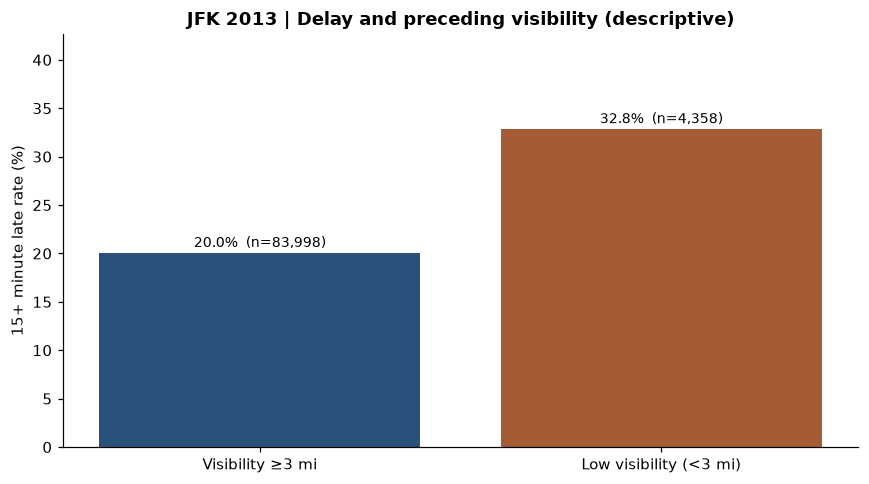

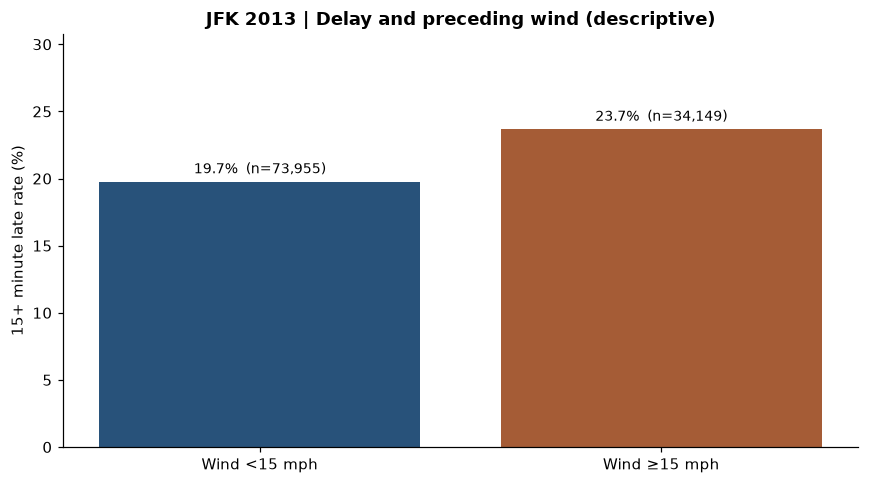

In [12]:
wx_visible = wx.dropna(subset=["visibility_mi"]).copy()
wx_visible["visibility_group"] = np.where(
    wx_visible.visibility_mi < 3, "Low visibility (<3 mi)", "Visibility ≥3 mi"
)
visibility_summary = (
    wx_visible.groupby("visibility_group")
    .agg(flights=("late_15", "size"), late_15_rate=("late_15", "mean"),
         median_delay_min=("dep_delay", "median"))
)

wx_wind = wx.dropna(subset=["wind_mph"]).copy()
wx_wind["wind_group"] = np.where(
    wx_wind.wind_mph >= 15, "Wind ≥15 mph", "Wind <15 mph"
)
wind_summary = (
    wx_wind.groupby("wind_group")
    .agg(flights=("late_15", "size"), late_15_rate=("late_15", "mean"),
         median_delay_min=("dep_delay", "median"))
)
print("Visibility groups:")
display(visibility_summary.round(3))
print("Wind speed groups:")
display(wind_summary.round(3))

# Save two separate plots so README readers can inspect them at a glance.
def rate_bars(summary, order, title, image_name):
    x = summary.reindex(order)
    fig, ax = plt.subplots(figsize=(8, 4.5))
    bars = ax.bar(range(len(x)), x.late_15_rate * 100,
                  color=["#28527a", "#a55c36"])
    ax.set_xticks(range(len(x)), x.index)
    ax.set_ylabel("15+ minute late rate (%)")
    ax.set_title(title, weight="bold")
    ax.set_ylim(0, max(x.late_15_rate * 100) * 1.3)
    for i, (bar, n) in enumerate(zip(bars, x.flights)):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.65,
                f"{x.late_15_rate.iloc[i]:.1%}  (n={n:,})", ha="center", fontsize=9)
    fig.tight_layout()
    fig.savefig(IMAGES_DIR / image_name, bbox_inches="tight")
    plt.show()

rate_bars(
    visibility_summary, ["Visibility ≥3 mi", "Low visibility (<3 mi)"],
    "JFK 2013 | Delay and preceding visibility (descriptive)",
    "05_weather_visibility.png",
)
rate_bars(
    wind_summary, ["Wind <15 mph", "Wind ≥15 mph"],
    "JFK 2013 | Delay and preceding wind (descriptive)",
    "06_weather_wind.png",
)

## 9. Route performance and statistical uncertainty

Route-level patterns are more actionable than carrier-wide averages but are not airline quality rankings. Restrict route rankings to destinations with at least **1,000 observed departures** and compare a subset of high-volume routes. Approximate **95% Wilson binomial confidence intervals** communicate sampling uncertainty; they do **not** adjust for shared day-level disruptions or route-mix confounding. Heatmap cells require at least **80 flights**.

Eligible destinations (>=1,000 observed departures): 33


,observed_flights,late_flights,late_15_rate,median_delay_min,ci_low,ci_high
dest,,,,,,
ORD,2243,693,0.309,0.0,0.290,0.328
MSP,1059,326,0.308,1.0,0.281,0.336
DTW,1118,296,0.265,0.0,0.240,0.291
PBI,1725,449,0.260,0.0,0.240,0.282
SYR,1294,334,0.258,-2.0,0.235,0.283
IAD,2524,635,0.252,-2.0,0.235,0.269
PWM,1286,316,0.246,-3.0,0.223,0.270
MSY,1596,390,0.244,-2.0,0.224,0.266
RDU,2991,723,0.242,-2.0,0.227,0.257


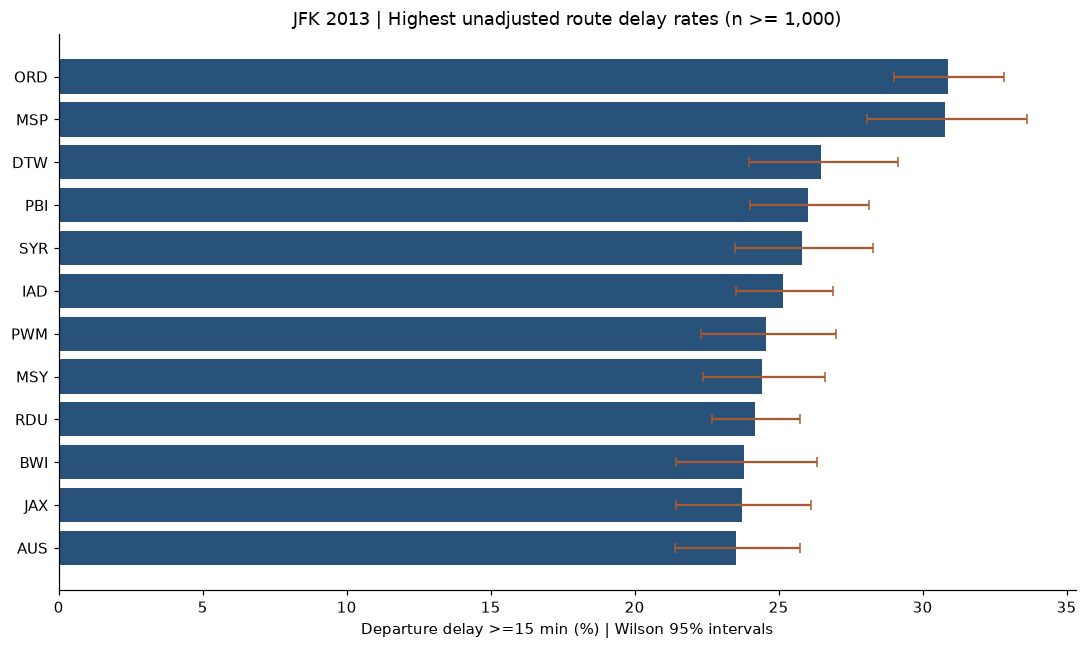

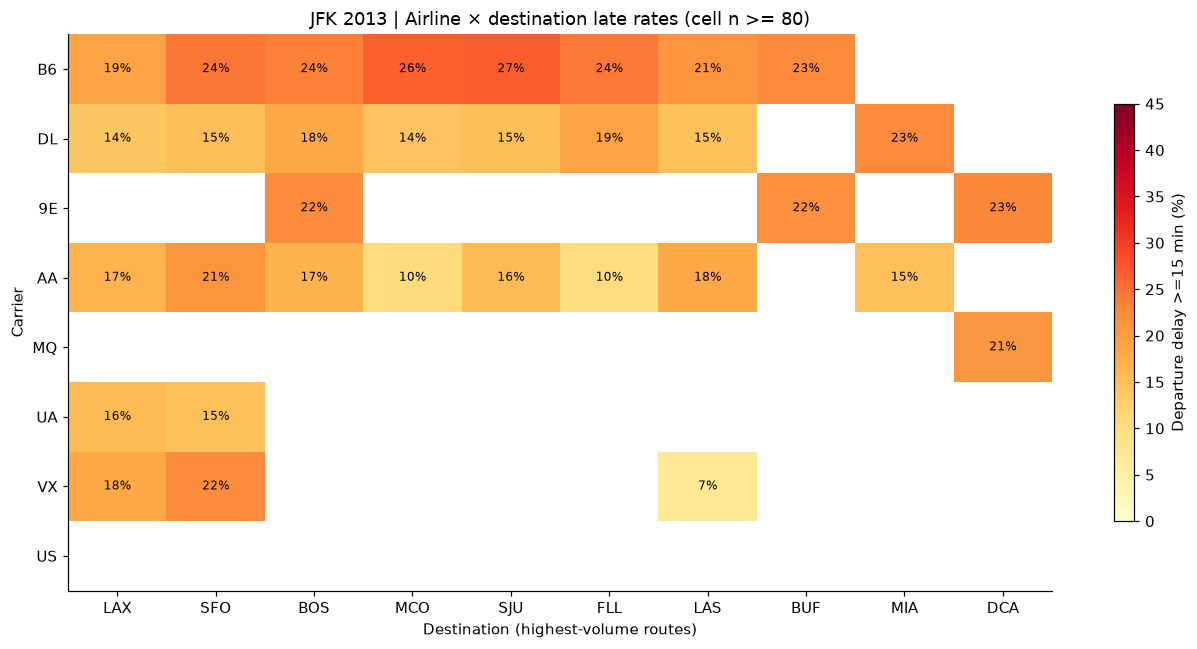

In [13]:
from scipy.stats import norm

def wilson_ci(successes, n, z=1.96):
    p = np.asarray(successes, dtype=float) / np.asarray(n, dtype=float)
    den = 1 + z*z/np.asarray(n, dtype=float)
    mid = (p + z*z/(2*np.asarray(n, dtype=float))) / den
    half = (z / den) * np.sqrt(p*(1-p)/np.asarray(n, dtype=float) + z*z/(4*np.asarray(n, dtype=float)**2))
    return mid-half, mid+half

route_summary = (observed.groupby('dest').agg(
    observed_flights=('late_15','size'), late_flights=('late_15','sum'),
    late_15_rate=('late_15','mean'), median_delay_min=('dep_delay','median')
).sort_values('observed_flights',ascending=False))
route_summary[['ci_low','ci_high']] = np.column_stack(wilson_ci(route_summary.late_flights, route_summary.observed_flights))
large_routes=route_summary.query('observed_flights >= 1000').copy()
print('Eligible destinations (>=1,000 observed departures):',len(large_routes))
display(large_routes.sort_values('late_15_rate',ascending=False).head(12).round(3))

plot_routes=large_routes.sort_values('late_15_rate',ascending=False).head(12).sort_values('late_15_rate')
fig,ax=plt.subplots(figsize=(10,6))
y=np.arange(len(plot_routes))
ax.barh(y,100*plot_routes.late_15_rate,color='#28527a')
ax.errorbar(100*plot_routes.late_15_rate,y,
            xerr=np.vstack([(plot_routes.late_15_rate-plot_routes.ci_low)*100,
                            (plot_routes.ci_high-plot_routes.late_15_rate)*100]),
            fmt='none',ecolor='#a55c36',capsize=3)
ax.set_yticks(y,plot_routes.index)
ax.set(xlabel='Departure delay >=15 min (%) | Wilson 95% intervals',
       title='JFK 2013 | Highest unadjusted route delay rates (n >= 1,000)')
fig.tight_layout();fig.savefig(IMAGES_DIR/'07_route_late_rate_ci.png',bbox_inches='tight');plt.show()

heat_carriers=observed.carrier.value_counts().head(8).index
heat_routes=route_summary.head(10).index
pairs=(observed[observed.carrier.isin(heat_carriers)&observed.dest.isin(heat_routes)]
       .groupby(['carrier','dest']).late_15.agg(['mean','size']))
heat=pairs['mean'].unstack('dest').reindex(index=heat_carriers,columns=heat_routes)
counts=pairs['size'].unstack('dest').reindex(index=heat_carriers,columns=heat_routes)
heat=heat.where(counts>=80)
fig,ax=plt.subplots(figsize=(12,6))
im=ax.imshow(np.ma.masked_invalid(heat.to_numpy(dtype=float)*100),vmin=0,vmax=45,
             cmap='YlOrRd',aspect='auto')
ax.set_xticks(range(len(heat.columns)),heat.columns)
ax.set_yticks(range(len(heat.index)),heat.index)
for i in range(len(heat.index)):
    for j in range(len(heat.columns)):
        if pd.notna(heat.iat[i,j]):
            ax.text(j,i,f'{heat.iat[i,j]*100:.0f}%',ha='center',va='center',fontsize=8)
ax.set(xlabel='Destination (highest-volume routes)',ylabel='Carrier',
       title='JFK 2013 | Airline × destination late rates (cell n >= 80)')
fig.colorbar(im,ax=ax,label='Departure delay >=15 min (%)',shrink=.75)
fig.tight_layout();fig.savefig(IMAGES_DIR/'08_route_carrier_heatmap.png',bbox_inches='tight');plt.show()

## 10. Extreme delays and disruption dates

Report proportions among measured departures: **15+**, **60+** and **120+ minutes**. Daily rates exclude days with fewer than **150 observed departures** so very small daily denominators do not dominate a ranking. A bad day is a signal to investigate; weather and operational causes cannot be established from these two datasets alone.

Top ten days by observed late-departure rate (minimum 150 flights)


,flights,late_count,late_rate,median_delay
flight_date,,,,
2013-03-08,304,188,0.618,34.5
2013-07-01,284,166,0.585,24.0
2013-06-25,317,171,0.539,22.0
2013-06-28,293,157,0.536,23.0
2013-02-27,294,156,0.531,19.5
2013-06-13,309,163,0.528,18.0
2013-07-23,312,161,0.516,18.0
2013-07-08,324,165,0.509,16.0
2013-08-09,316,159,0.503,15.5


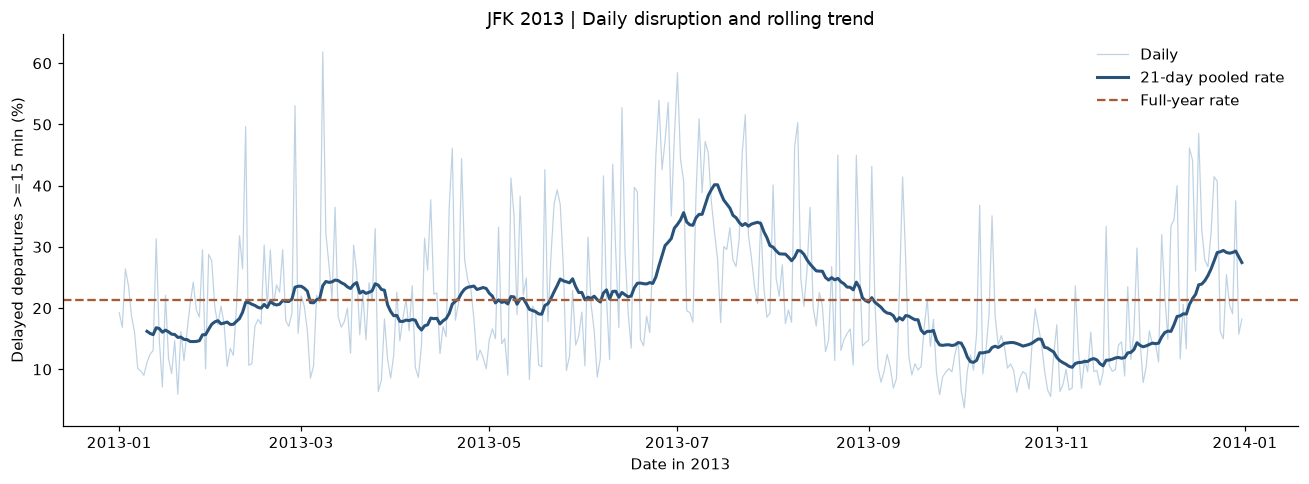

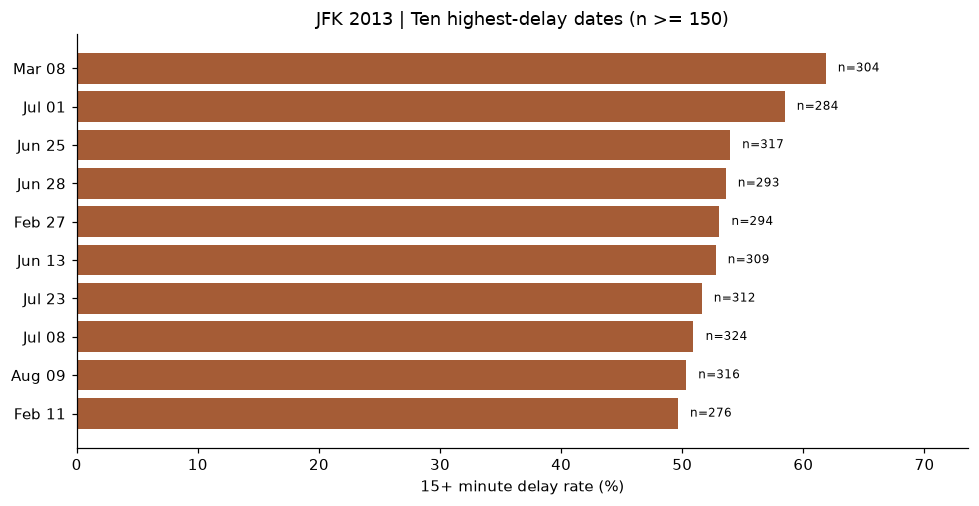

,Threshold,flights,rate
0,>=15 minutes,23347,0.2134
1,>=60 minutes,8541,0.0781
2,>=120 minutes,3103,0.0284


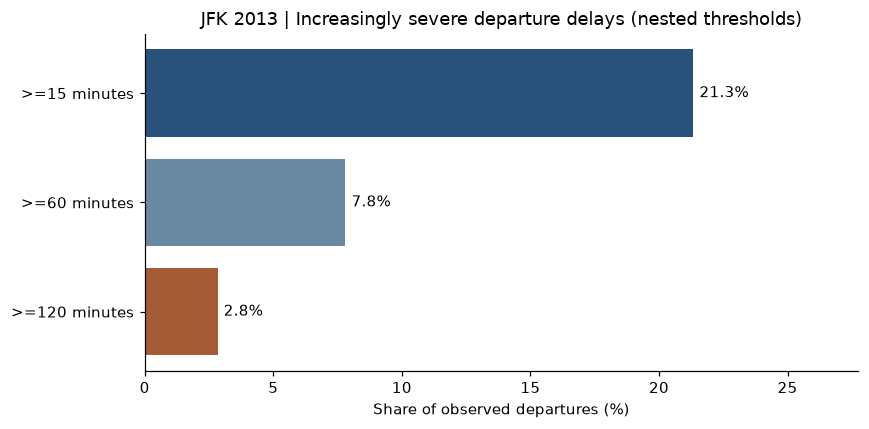

In [14]:
daily = observed.groupby('flight_date').agg(
    flights=('late_15','size'),late_count=('late_15','sum'),
    median_delay=('dep_delay','median'),p90_delay=('dep_delay',lambda s: s.quantile(.9))
)
daily['late_rate']=daily.late_count/daily.flights
daily['rolling_21d_rate']=(daily.late_count.rolling(21,min_periods=10).sum() /
                             daily.flights.rolling(21,min_periods=10).sum())
days_eligible=daily.loc[daily.flights>=150]
worst_days=days_eligible.nlargest(10,'late_rate')
print('Top ten days by observed late-departure rate (minimum 150 flights)')
display(worst_days[['flights','late_count','late_rate','median_delay']].round(3))
fig,ax=plt.subplots(figsize=(12,4.5))
ax.plot(daily.index,100*daily.late_rate,lw=.8,color='#7fa7c9',alpha=.5,label='Daily')
ax.plot(daily.index,100*daily.rolling_21d_rate,lw=2,color='#28527a',label='21-day pooled rate')
ax.axhline(100*observed.late_15.mean(),color='#a55c36',ls='--',label='Full-year rate')
ax.set(xlabel='Date in 2013',ylabel='Delayed departures >=15 min (%)',
       title='JFK 2013 | Daily disruption and rolling trend')
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(IMAGES_DIR/'09_daily_disruption.png',bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(9,4.7))
worst_display=worst_days.sort_values('late_rate')
ax.barh(worst_display.index.strftime('%b %d'),100*worst_display.late_rate,color='#a55c36')
for j,(_idx,row) in enumerate(worst_display.iterrows()):
    ax.text(100*row.late_rate+1,j,f"n={int(row.flights):,}",va='center',fontsize=8)
ax.set(xlim=(0,max(100*worst_display.late_rate)*1.19),xlabel='15+ minute delay rate (%)',
       title='JFK 2013 | Ten highest-delay dates (n >= 150)')
fig.tight_layout();fig.savefig(IMAGES_DIR/'10_worst_days.png',bbox_inches='tight');plt.show()

severity = pd.DataFrame({'Threshold':['>=15 minutes','>=60 minutes','>=120 minutes'],
  'flights':[(observed.dep_delay>=x).sum() for x in [15,60,120]],
  'rate':[(observed.dep_delay>=x).mean() for x in [15,60,120]]})
display(severity.round(4))
fig,ax=plt.subplots(figsize=(8,4))
b= ax.barh(severity.Threshold[::-1],100*severity.rate[::-1],color=['#a55c36','#6989a3','#28527a'])
ax.bar_label(b,fmt='%.1f%%',padding=4)
ax.set(xlim=(0,100*severity.rate.max()*1.3),xlabel='Share of observed departures (%)',
       title='JFK 2013 | Increasingly severe departure delays (nested thresholds)')
fig.tight_layout();fig.savefig(IMAGES_DIR/'11_delay_severity.png',bbox_inches='tight');plt.show()

## 11. Delay recovery by flight distance

`delay_change_min = dep_delay − arr_delay` describes how recorded lateness changes between departure and arrival; it is **not** a measure of in-air speed or a causal effect of route length. Compare only flights departing ≥15 minutes late with an observed arrival delay. The rate of ≥15-minute improvement and the median minutes of improvement are both reported, along with denominators.

,flights,median_lateness_change,pct_recovered_15,median_departure_delay
distance_band,,,,
<750 mi,9020,6.0,0.261,48.0
"750–1,499 mi",6131,6.0,0.330,41.0
"1,500–2,499 mi",6299,10.0,0.400,38.0
">=2,500 mi",1759,8.0,0.400,46.0


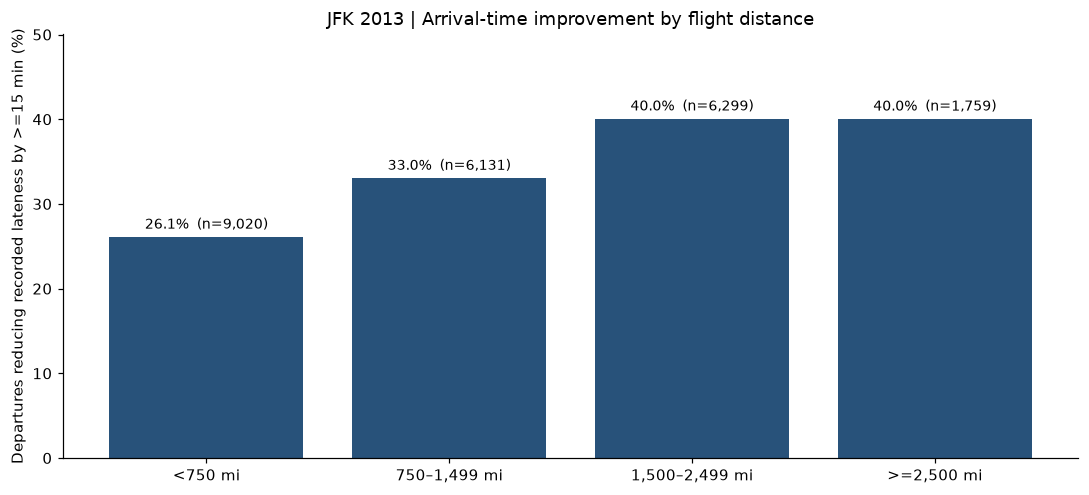

In [15]:
distance_edges=[0,750,1500,2500,np.inf]
distance_labels=['<750 mi','750–1,499 mi','1,500–2,499 mi','>=2,500 mi']
recovery=initially_late.loc[initially_late.distance.gt(0)].copy()
recovery['distance_band']=pd.cut(recovery.distance,bins=distance_edges,
                                  labels=distance_labels,right=False)
recovery_summary=recovery.groupby('distance_band',observed=True).agg(
    flights=('delay_change_min','size'),median_lateness_change=('delay_change_min','median'),
    pct_recovered_15=('delay_change_min',lambda s:(s>=15).mean()),
    median_departure_delay=('dep_delay','median'))
display(recovery_summary.round(3))
fig,ax=plt.subplots(figsize=(10,4.6))
r=recovery_summary.reindex(distance_labels)
bars=ax.bar(range(len(r)),100*r.pct_recovered_15,color='#28527a')
ax.set_xticks(range(len(r)),r.index)
for i,(p,n) in enumerate(zip(r.pct_recovered_15,r.flights)):
    if pd.notna(p):ax.text(i,p*100+1,f'{p:.1%}  (n={n:,.0f})',ha='center',fontsize=9)
ax.set(ylim=(0,max(100*r.pct_recovered_15)*1.25),
       ylabel='Departures reducing recorded lateness by >=15 min (%)',
       title='JFK 2013 | Arrival-time improvement by flight distance')
fig.tight_layout();fig.savefig(IMAGES_DIR/'12_delay_recovery_distance.png',bbox_inches='tight');plt.show()

## 12. Adjusted weather associations (observational logistic regression)

Unadjusted weather-group differences are compared with a **multivariable logistic regression** with month, weekday, carrier, route-group and flight distance controls. The uncertainty bands use **cluster-robust standard errors grouped by flight date**, reflecting that weather/disruptions are shared by many flights on a day. Coefficients are reported as **adjusted odds ratios (OR)**, not as causal risk ratios. OR ≠ percentage-point change and cannot establish a weather effect. The accompanying forest chart uses a **logarithmic odds-ratio axis** with the null reference at 1; points are estimates and whiskers are 95% day-clustered confidence intervals. Numeric estimates remain available in the output table.

**Sample limitation:** Section 7A shows that date-boundary exclusions are concentrated among unusually late flights. The regression only describes the eligible flights with usable weather fields; clustered uncertainty does not remove that selection problem.

**Critical limitation:** The original flights CSV does not contain the *independently recorded* scheduled departure time. The weather alignment uses an **estimated scheduled timestamp reconstructed from actual departure time and the recorded delay**, which is outcome-dependent. Weather matching and derived-hour results are exploratory and must not be interpreted as leakage-free prediction or a causal test. Match coverage and 30/60/90-minute age sensitivity are shown. No weather column or reconstructed schedule is used in the predictive model below.

Adjusted association sample: 88340 flights on 365 distinct dates
Both recorded weather variables are required for inclusion.


,Term,Adjusted_OR,Lower_95,Upper_95,p_value_clustered,Exposure_n
0,Visibility <3 miles,1.9689,1.5341,2.5270,<0.001,4358
1,Wind >=15 mph,1.3079,1.1892,1.4384,<0.001,28761


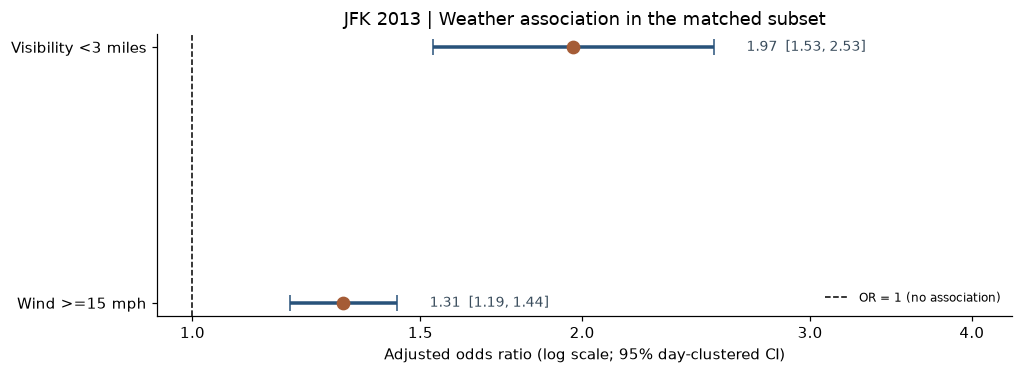

Matching-window sensitivity (unadjusted; same outcome-dependent proxy-time caveat):


,Max observation age (min),Flights,Low-vis flights,Low-vis rate,Higher-vis rate,Rate difference (pp)
0,30,54594,3471,0.328,0.2,12.749
1,60,88340,4358,0.328,0.2,12.791
2,90,88340,4358,0.328,0.2,12.791


In [16]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

adj=wx.dropna(subset=['visibility_mi','wind_mph','distance']).copy()
adj['late_int']=adj.late_15.astype(int)
adj['low_vis']=(adj.visibility_mi<3).astype(int)
adj['strong_wind']=(adj.wind_mph>=15).astype(int)
adj['weekday_num']=adj.flight_date.dt.dayofweek.astype(int)
# Keep route complexity bounded to top 12 destinations; OTHER remains an explicit level.
top12_dest=set(observed.dest.value_counts().head(12).index)
adj['route_group']=adj.dest.where(adj.dest.isin(top12_dest),'OTHER')
adj['distance_kmi']=adj.distance/1000.0
assert adj.flight_date.notna().all()
print('Adjusted association sample:',len(adj),'flights on',adj.flight_date.nunique(),'distinct dates')
print('Both recorded weather variables are required for inclusion.')

weather_formula=('late_int ~ low_vis + strong_wind + distance_kmi + '
                 'C(month) + C(weekday_num) + C(carrier) + C(route_group)')
weather_glm=smf.glm(weather_formula,data=adj,family=sm.families.Binomial()).fit(
    cov_type='cluster',cov_kwds={'groups':adj.flight_date},maxiter=90)
terms=['low_vis','strong_wind']
adjusted_weather=pd.DataFrame({
    'Term':['Visibility <3 miles','Wind >=15 mph'],
    'Adjusted_OR':np.exp(weather_glm.params[terms].values),
    'Lower_95':np.exp(weather_glm.conf_int().loc[terms,0].values),
    'Upper_95':np.exp(weather_glm.conf_int().loc[terms,1].values),
    'p_value_clustered':weather_glm.pvalues[terms].values,
    'Exposure_n':[int(adj.low_vis.sum()),int(adj.strong_wind.sum())]})
display(adjusted_weather.assign(p_value_clustered=adjusted_weather.p_value_clustered.map(p_for_display)).round(4))
fig,ax=plt.subplots(figsize=(9.4,3.5))
for i,rr in adjusted_weather.iterrows():
    ax.errorbar(rr.Adjusted_OR,i, xerr=[[rr.Adjusted_OR-rr.Lower_95],
                                      [rr.Upper_95-rr.Adjusted_OR]],
                fmt='o',ms=8,color='#a55c36',ecolor='#28527a',elinewidth=2.3,capsize=5)
    ax.text(rr.Upper_95*1.06,i,
            f'{rr.Adjusted_OR:.2f}  [{rr.Lower_95:.2f}, {rr.Upper_95:.2f}]',
            va='center',fontsize=9,color='#394c5c')
ax.axvline(1,color='black',ls='--',lw=1,label='OR = 1 (no association)')
ax.set_yticks(range(len(adjusted_weather)),adjusted_weather.Term)
ax.set_xscale('log')
ax.set_xticks([1,1.5,2,3,4],labels=['1.0','1.5','2.0','3.0','4.0'])
ax.set_xlim(left=max(0.55,min(adjusted_weather.Lower_95)*.79),
            right=max(1.9,max(adjusted_weather.Upper_95)*1.7))
ax.set(xlabel='Adjusted odds ratio (log scale; 95% day-clustered CI)',
       title='JFK 2013 | Weather association in the matched subset')
ax.invert_yaxis();ax.legend(frameon=False,fontsize=8,loc='lower right');fig.tight_layout()
fig.savefig(IMAGES_DIR/'13_adjusted_weather_odds_ratios.png',bbox_inches='tight');plt.show()

age_sensitivity=[]
for max_age in [30,60,90]:
    sub=adj.loc[adj.observation_age_min.le(max_age)]
    nlow=int(sub.low_vis.sum()); nhigh=len(sub)-nlow
    age_sensitivity.append({'Max observation age (min)':max_age,'Flights':len(sub),
        'Low-vis flights':nlow, 'Low-vis rate':sub.loc[sub.low_vis==1,'late_int'].mean(),
        'Higher-vis rate':sub.loc[sub.low_vis==0,'late_int'].mean(),
        'Rate difference (pp)':100*(sub.loc[sub.low_vis==1,'late_int'].mean()-
                                    sub.loc[sub.low_vis==0,'late_int'].mean())})
age_sensitivity=pd.DataFrame(age_sensitivity)
print('Matching-window sensitivity (unadjusted; same outcome-dependent proxy-time caveat):')
display(age_sensitivity.round(3))

## 13. Predicting late departures using only pre-departure information

**Decision point:** Before takeoff. **Target:** `dep_delay >= 15` minutes (only records with known delay). **Predictors known in advance:** month, day of week, airline code, destination, and route distance. Neither `dep_time`, `arr_time`, `arr_delay`, `dep_delay`, reconstructed `scheduled_hour`, nor weather reports time-matched using that reconstructed timestamp are included. The available data do not include independent scheduled-departure time, gate, tail rotation, air-traffic flow, or live forecast data; predictive performance is therefore expected to be limited.

**Strict chronological split**: train **Jan–Aug 2013**, validate **Sep–Oct**, test **Nov–Dec**. Test months are never used to fit or choose thresholds. Compare a **constant-prior baseline**, **Logistic Regression**, and **Histogram Gradient Boosting**. Validation precision/recall chooses a classification threshold **only for the best validation PR-AUC model**. Test evaluation reports ROC-AUC, average precision (PR-AUC summary), Brier score, log loss, precision, recall and F1. This is a time holdout within one historical year, **not proof of out-of-year generalization**.

**Deployment caution:** Selecting a probability threshold to optimize development-set F1 can create extreme carrier-specific false-positive rates. The reported threshold must not be treated as an operational dispatch or staffing policy. Ranking (AP/Lift) and alerting (precision, FPR, threshold costs) are different tasks.


In [17]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, brier_score_loss,
    log_loss, precision_score, recall_score, f1_score, roc_curve, precision_recall_curve)

predictors=['month','weekday_num','carrier','dest','distance']
pred=observed.dropna(subset=['carrier','dest','distance']).copy()
pred['weekday_num']=pred.flight_date.dt.dayofweek.astype(int)
pred['month']=pred['month'].astype(int)
pred['distance']=pred.distance.astype(float)
pred['target']=pred.late_15.astype(int)
train=pred.loc[pred.flight_date.lt('2013-09-01')]
valid=pred.loc[pred.flight_date.between('2013-09-01','2013-10-31')]
test=pred.loc[pred.flight_date.ge('2013-11-01')]
assert len(train)>0 and len(valid)>0 and len(test)>0
assert train.flight_date.max()<valid.flight_date.min() and valid.flight_date.max()<test.flight_date.min()
for name,part in [('Train (Jan–Aug)',train),('Validation (Sep–Oct)',valid),('Test (Nov–Dec)',test)]:
    print(f'{name}: n={len(part):,}, late_15={part.target.mean():.1%}')

cat=['carrier','dest']; nums=['month','weekday_num','distance']
X_train=train[predictors]; X_valid=valid[predictors]; X_test=test[predictors]
y_train=train.target; y_valid=valid.target; y_test=test.target
# Pipeline preprocessing is fitted on train only; unseen categories are handled explicitly.
logistic=Pipeline([
    ('preprocess',ColumnTransformer([
        ('cat',OneHotEncoder(handle_unknown='ignore'),cat),
        ('num',StandardScaler(),nums)
    ])),
    ('classifier',LogisticRegression(max_iter=600,solver='lbfgs'))
])
# HistGradientBoosting natively treats ordinal-encoded carrier/destination columns as categorical.
gradient_boosting=Pipeline([
    ('preprocess',ColumnTransformer([
        ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat),
        ('num','passthrough',nums)
    ])),
    ('classifier',HistGradientBoostingClassifier(
        categorical_features=[True,True,False,False,False],max_iter=85,
        max_leaf_nodes=15,min_samples_leaf=130,learning_rate=0.075,
        early_stopping=False,random_state=42))
])
models={
    'Constant baseline':DummyClassifier(strategy='prior'),
    'Logistic Regression':logistic,
    'Gradient Boosting':gradient_boosting,
}
validation_predictions={}; test_predictions={}
for name,model in models.items():
    model.fit(X_train,y_train)
    validation_predictions[name]=model.predict_proba(X_valid)[:,1]
    test_predictions[name]=model.predict_proba(X_test)[:,1]

val_ap={name:average_precision_score(y_valid,p) for name,p in validation_predictions.items()}
winner=max(['Logistic Regression','Gradient Boosting'],key=lambda n:val_ap[n])
print('Validation average precision:',{k:round(v,4) for k,v in val_ap.items()})
print('Selected model (based on validation only):',winner)
# Choose a threshold from validation (F1 is only a demonstration; actual deployment
# should optimize a defined cost/benefit objective instead).
vp=validation_predictions[winner]
pr,rc,thr=precision_recall_curve(y_valid,vp)
f1_grid=2*pr[:-1]*rc[:-1]/np.maximum(pr[:-1]+rc[:-1],1e-12)
chosen_threshold=float(thr[np.argmax(f1_grid)])
print(f'Validation-selected F1 threshold: {chosen_threshold:.3f}')

records=[]
for name,p in test_predictions.items():
    cutoff=0.5 # shared hard-label threshold for fair across-model comparison
    labels=(p>=cutoff).astype(int)
    records.append({'Model':name,'Test n':len(test),'ROC-AUC':roc_auc_score(y_test,p),
      'Avg precision':average_precision_score(y_test,p),'Brier':brier_score_loss(y_test,p),
      'Log loss':log_loss(y_test,p,labels=[0,1]),'Threshold':cutoff,
      'Precision':precision_score(y_test,labels,zero_division=0),
      'Recall':recall_score(y_test,labels,zero_division=0),
      'F1':f1_score(y_test,labels,zero_division=0)})
model_scores=pd.DataFrame(records).set_index('Model')
display(model_scores.round(4))
print('All hard-label test metrics above use a shared 0.50 cutoff; model selection uses validation AP.')
print('Validation-only F1-optimal cutoff for chosen model (diagnostic, not used in table):',round(chosen_threshold,3))

Train (Jan–Aug): n=73,855, late_15=23.6%
Validation (Sep–Oct): n=17,924, late_15=13.8%
Test (Nov–Dec): n=17,637, late_15=19.6%
Validation average precision: {'Constant baseline': 0.1385, 'Logistic Regression': 0.1718, 'Gradient Boosting': 0.1703}
Selected model (based on validation only): Logistic Regression
Validation-selected F1 threshold: 0.276


,Test n,ROC-AUC,Avg precision,Brier,Log loss,Threshold,Precision,Recall,F1
Model,,,,,,,,,
Constant baseline,17637,0.5000,0.1962,0.1593,0.4996,0.5,0.0000,0.0000,0.0000
Logistic Regression,17637,0.5963,0.2523,0.1820,0.5510,0.5,0.2797,0.0598,0.0986
Gradient Boosting,17637,0.5622,0.2307,0.1616,0.5033,0.5,0.2612,0.0101,0.0195


All hard-label test metrics above use a shared 0.50 cutoff; model selection uses validation AP.
Validation-only F1-optimal cutoff for chosen model (diagnostic, not used in table): 0.276


## 14. Model evaluation, calibration, and feature importance

ROC curves show discrimination, while precision–recall curves are especially relevant when delayed flights form a minority. Probability **calibration** checks whether a predicted 20% risk occurs around 20% of the time. Grouped **permutation importance** on a fixed-size test subset measures the change in average precision after shuffling one input feature; it is **not** causal importance. A constant-rate predictor has no useful ranking: on the precision–recall chart, the appropriate no-skill reference is a **horizontal line at the test-period late rate**, not the diagonal produced when connecting endpoints from constant predictions. ROC-AUC for this reference remains 0.5. Baseline and model performance can shift between historical seasons.

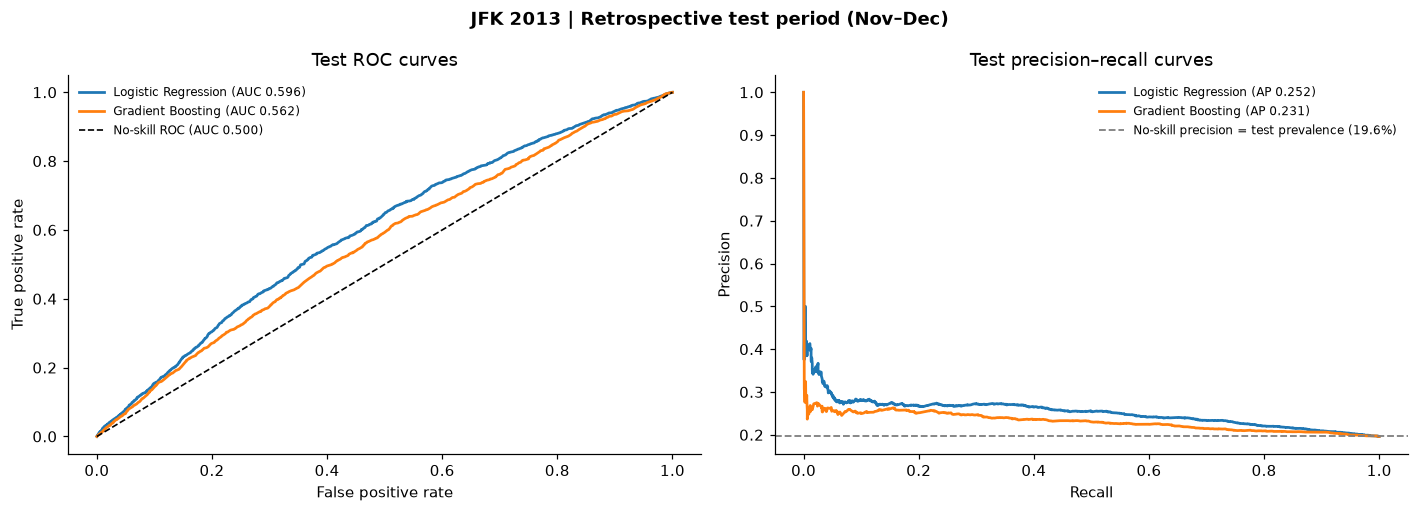

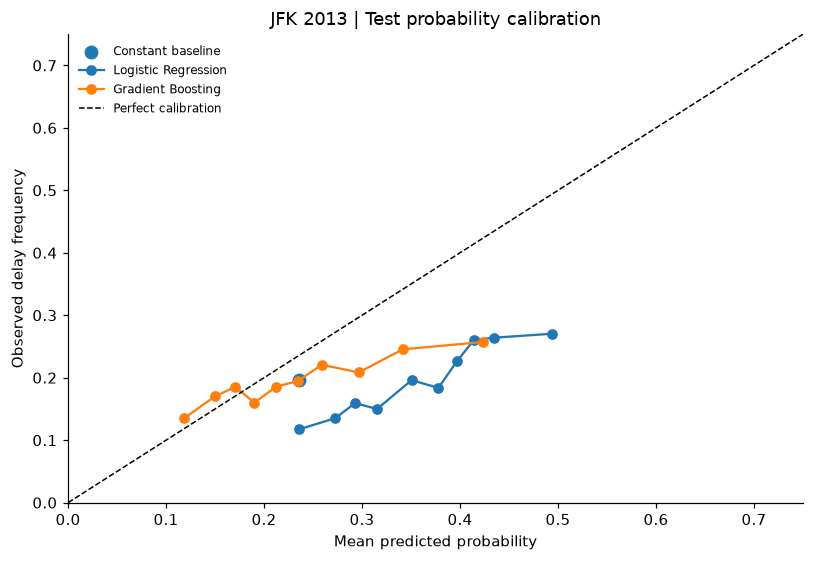

,Feature,Mean AP decrease,SD
2,carrier,0.0280,0.0017
0,month,0.0115,0.0023
4,distance,0.0002,0.0001
3,dest,-0.0006,0.0072
1,weekday_num,-0.0025,0.0024


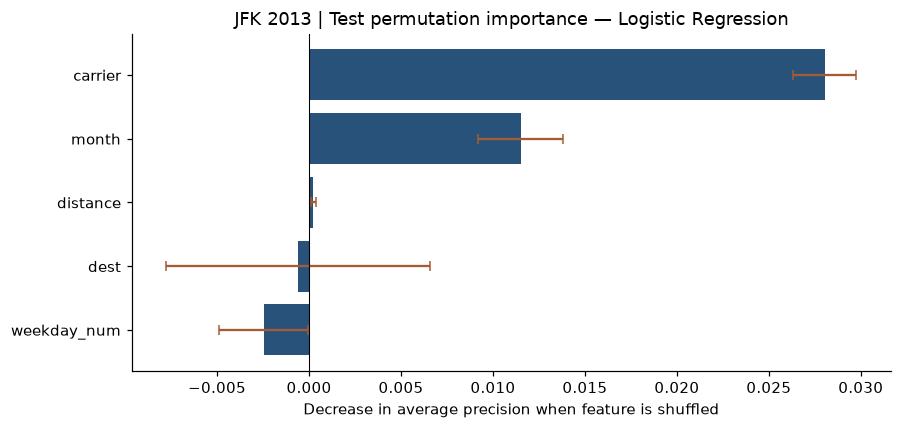

In [18]:
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
for name,p in test_predictions.items():
    fpr,tpr,_=roc_curve(y_test,p)
    precision,recall,_=precision_recall_curve(y_test,p)
    if name != 'Constant baseline':
        axes[0].plot(fpr,tpr,lw=1.8,label=f'{name} (AUC {roc_auc_score(y_test,p):.3f})')
    if name != 'Constant baseline':
        axes[1].plot(recall,precision,lw=1.8,label=f'{name} (AP {average_precision_score(y_test,p):.3f})')
axes[0].plot([0,1],[0,1],'k--',lw=1.1,label='No-skill ROC (AUC 0.500)')
axes[1].axhline(y_test.mean(),color='gray',ls='--',lw=1.2,
                label=f'No-skill precision = test prevalence ({y_test.mean():.1%})')
axes[0].set(xlabel='False positive rate',ylabel='True positive rate',title='Test ROC curves')
axes[1].set(xlabel='Recall',ylabel='Precision',title='Test precision–recall curves')
for ax in axes:ax.legend(fontsize=8,frameon=False)
fig.suptitle('JFK 2013 | Retrospective test period (Nov–Dec)',fontweight='bold')
fig.tight_layout();fig.savefig(IMAGES_DIR/'14_prediction_roc_pr.png',bbox_inches='tight');plt.show()

fig,ax=plt.subplots(figsize=(7.5,5.2))
for name,p in test_predictions.items():
    cut=np.unique(np.quantile(p,np.linspace(0,1,11)))
    if len(cut)<3: # constant baseline
        ax.scatter([p.mean()],[y_test.mean()],s=65,label=name)
        continue
    bucket=pd.cut(p,bins=cut,include_lowest=True,duplicates='drop')
    cc=pd.DataFrame({'p':p,'y':y_test.to_numpy(),'bin':bucket}).groupby('bin',observed=True).agg(
      predicted=('p','mean'),observed=('y','mean'),n=('y','size'))
    ax.plot(cc.predicted,cc.observed,marker='o',lw=1.5,label=name)
ax.plot([0,1],[0,1],'k--',lw=1,label='Perfect calibration')
ax.set(xlim=(0,.75),ylim=(0,.75),xlabel='Mean predicted probability',
       ylabel='Observed delay frequency',title='JFK 2013 | Test probability calibration')
ax.legend(frameon=False,fontsize=8);fig.tight_layout()
fig.savefig(IMAGES_DIR/'15_prediction_calibration.png',bbox_inches='tight');plt.show()

# Small, deterministic sample avoids expensive repeated evaluation on the full test.
from sklearn.inspection import permutation_importance
interpret_model=models[winner]
X_eval=X_test.sample(min(3500,len(X_test)),random_state=43)
y_eval=y_test.loc[X_eval.index]
pi=permutation_importance(interpret_model,X_eval,y_eval,scoring='average_precision',
    n_repeats=3,random_state=42,n_jobs=1)
importance=pd.DataFrame({'Feature':predictors,'Mean AP decrease':pi.importances_mean,
                         'SD':pi.importances_std}).sort_values('Mean AP decrease',ascending=False)
display(importance.round(4))
fig,ax=plt.subplots(figsize=(8.3,4))
p=importance.sort_values('Mean AP decrease')
ax.barh(p.Feature,p['Mean AP decrease'],xerr=p['SD'],color='#28527a',ecolor='#a55c36',capsize=3)
ax.axvline(0,color='black',lw=.7)
ax.set(xlabel='Decrease in average precision when feature is shuffled',
       title=f'JFK 2013 | Test permutation importance — {winner}')
fig.tight_layout();fig.savefig(IMAGES_DIR/'16_prediction_feature_importance.png',bbox_inches='tight');plt.show()

## 15. Schedule provenance and prediction-time audit

The provided project CSV contains **actual** `dep_time`, `hour` and `minute`, not an independently stored `sched_dep_time`. The earlier notebook **reconstructs** nominal scheduled clock time as `(actual clock − dep_delay) modulo 24 hours`; this uses the outcome and must **never** be an input to a predictive model. It is used *only* for retrospective exploratory weather alignment and descriptive hour-of-day patterns. This is not an independently verified flight schedule. The published `nycflights13` project provides `sched_dep_time`; joining that field after validating unique flight identifiers would strengthen future work.

The prediction features remain limited to `month`, weekday, carrier, destination and distance. No actual departure clock, `dep_delay`, arrival outcomes, realized weather or aircraft's later activity enters the forecast models.

In [19]:
# Explicit audit of recorded clock and derived schedule: never use either in predictive X.
source_hour = pd.to_numeric(flights_raw["dep_time"], errors="coerce") // 100
valid_hour = source_hour.between(0, 24)
audit = pd.DataFrame({
    "Diagnostic": ["Rows with recorded actual clock", "Rows with reconstructed scheduled hour",
                   "Valid actual clock hour values", "Independent scheduled departure clock in CSV",
                   "Forecast columns using reconstructed schedule"],
    "Result": [f"{flights_raw.dep_time.notna().sum():,}",
               f"{flights.scheduled_hour.notna().sum():,}",
               f"{valid_hour.sum():,}", "No", "None"]
})
display(audit)
assert "scheduled_hour" not in predictors and "dep_delay" not in predictors

,Diagnostic,Result
0,Rows with recorded actual clock,"109,416"
1,Rows with reconstructed scheduled hour,"109,416"
2,Valid actual clock hour values,"109,416"
3,Independent scheduled departure clock in CSV,No
4,Forecast columns using reconstructed schedule,None


## 16. Same-aircraft repeat departures: delay persistence (not proven causation)

Link **consecutive observed JFK departures on the same date and with the same nonmissing `tailnum`**, ordered by the **actual** departure clock. Restrict to gaps of 3–20 hours to avoid implausibly short intervals. Compare subsequent 15+ minute lateness conditional on an earlier same-aircraft JFK departure being late. A flight may have operated **unobserved inbound/other-airport legs** between the two JFK departures; this is *not* a complete aircraft rotation chain. Airline, calendar, operational intensity and disruptions can confound the relationship. Lagged actual delays are suitable for retrospective association, **not** included in the pre-departure model.

**Clock boundary audit:** `dep_time` values are checked for valid HHMM encodings (including only `2400` as a permissible hour-24 boundary). Eligible pair analysis still requires the same `flight_date`, the same tail number, and a strictly positive 3–20-hour recorded JFK-to-JFK gap. These restrictions cannot recover unseen intermediate flights or prove propagation.


Rejected invalid clock encodings: 0
Same-date and 3–20 hour windows are descriptive filters, not verified aircraft rotations.
Valid 3–20 hour same-date repeat pairs: 24211
Eligible consecutive same-tail JFK pairs: 24,211; dates: 365


,n,rate,median_gap_hours,median_departure_delay
previous_late,,,,
0,20535,0.227,6.650,-1.0
1,3676,0.572,5.642,23.0


Unadjusted subsequent-delay difference: 34.4 percentage points
Cluster bootstrap (date) 95% CI for difference: 32.6 to 36.6 pp


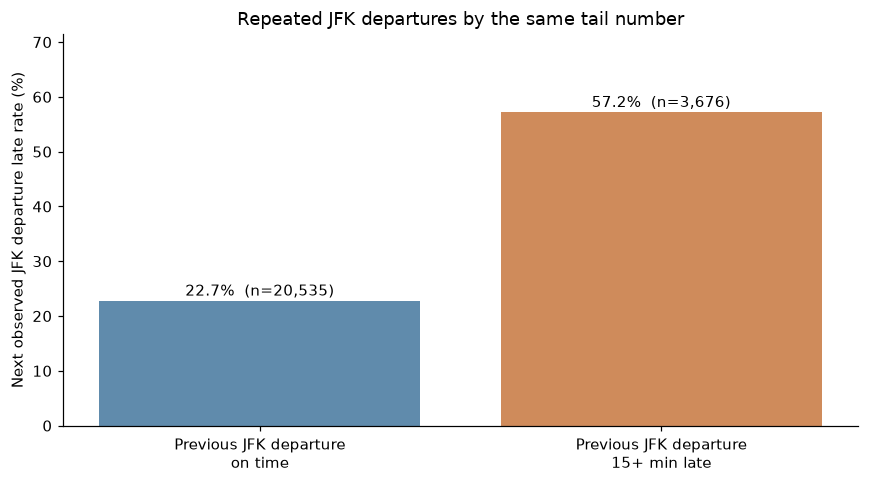

In [20]:
rotation = flights.dropna(subset=["tailnum", "dep_time", "dep_delay"]).copy()
clock_numeric = pd.to_numeric(rotation.dep_time,errors='coerce')
clock_hr=np.floor(clock_numeric/100)
clock_mm=clock_numeric%100
valid_rotation_clock = (clock_hr.between(0,24) & clock_mm.between(0,59)
                        & ((clock_hr<24) | clock_mm.eq(0)))
invalid_rotation_clocks=int((~valid_rotation_clock).sum())
rotation=rotation.loc[valid_rotation_clock].copy()
rotation['clock_min']=clock_hr.loc[rotation.index]*60+clock_mm.loc[rotation.index]
assert rotation.clock_min.between(0,1440).all()
print('Rejected invalid clock encodings:',invalid_rotation_clocks)
print('Same-date and 3–20 hour windows are descriptive filters, not verified aircraft rotations.')
rotation = rotation.sort_values(["flight_date", "tailnum", "clock_min", "flight"])
rotation["previous_clock_min"] = rotation.groupby(["flight_date", "tailnum"]).clock_min.shift(1)
rotation["previous_dep_delay"] = rotation.groupby(["flight_date", "tailnum"]).dep_delay.shift(1)
rotation["gap_hours"] = (rotation.clock_min - rotation.previous_clock_min) / 60.0
rotation_pairs = rotation.loc[rotation.gap_hours.between(3, 20)].copy()
assert rotation_pairs.gap_hours.between(3,20).all()
assert (rotation_pairs.clock_min>rotation_pairs.previous_clock_min).all()
# Flights at an airport on adjacent dates cannot be treated as complete aircraft rotations.
print('Valid 3–20 hour same-date repeat pairs:',len(rotation_pairs))
rotation_pairs["previous_late"] = rotation_pairs.previous_dep_delay.ge(15).astype(int)
rotation_pairs["current_late"] = rotation_pairs.dep_delay.ge(15).astype(int)
rotation_summary = rotation_pairs.groupby("previous_late").agg(
    n=("current_late", "size"), rate=("current_late", "mean"),
    median_gap_hours=("gap_hours", "median"), median_departure_delay=("dep_delay", "median")
)
assert set(rotation_summary.index)=={0,1} and rotation_summary.n.min()>100
p_prev_late = rotation_summary.loc[1,"rate"]
p_prev_on_time = rotation_summary.loc[0,"rate"]
print(f"Eligible consecutive same-tail JFK pairs: {len(rotation_pairs):,}; dates: {rotation_pairs.flight_date.nunique():,}")
display(rotation_summary.round(3))
print(f"Unadjusted subsequent-delay difference: {(p_prev_late-p_prev_on_time)*100:.1f} percentage points")
# Daily cluster bootstrap for the raw rate difference; shared disruption dates are resampled together.
perday = (rotation_pairs.groupby(["flight_date", "previous_late"])['current_late']
          .agg(['sum','count']).unstack('previous_late',fill_value=0))
num0=perday[('sum',0)].to_numpy(); den0=perday[('count',0)].to_numpy()
num1=perday[('sum',1)].to_numpy(); den1=perday[('count',1)].to_numpy()
rng=np.random.default_rng(42); draws=[]
for _ in range(300):
    ix=rng.integers(0,len(perday),size=len(perday))
    if den1[ix].sum()>0 and den0[ix].sum()>0:
        draws.append(num1[ix].sum()/den1[ix].sum()-num0[ix].sum()/den0[ix].sum())
rotation_diff_ci=np.quantile(draws,[.025,.975])
print(f"Cluster bootstrap (date) 95% CI for difference: {rotation_diff_ci[0]*100:.1f} to {rotation_diff_ci[1]*100:.1f} pp")
fig,ax=plt.subplots(figsize=(8,4.5))
vals=rotation_summary.rate.reindex([0,1])*100
ax.bar(['Previous JFK departure\non time','Previous JFK departure\n15+ min late'],vals,color=['#608bac','#cf8b5b'])
ax.set(ylabel='Next observed JFK departure late rate (%)',title='Repeated JFK departures by the same tail number')
for i,(rate,n) in enumerate(zip(vals,rotation_summary.n.reindex([0,1]))):
    ax.text(i,rate+1.0,f'{rate:.1f}%  (n={n:,})',ha='center')
ax.set_ylim(0,max(vals)*1.25)
fig.tight_layout();fig.savefig(IMAGES_DIR/'17_aircraft_repeat_departure.png',bbox_inches='tight');plt.show()

## 17. Severity prediction: 60- and 120-minute delays, plus a two-stage model

Use the **same chronologically separated development and final test samples** as the existing 15-minute model. Compare simple prevalence priors against logistic classifiers for delays of at least **60 minutes** and **120 minutes**. In addition, test a transparent **two-stage factorization** for 60-minute risk:

`P(delay >=60 | X) = P(delay >=15 | X) × P(delay >=60 | delay >=15, X)`.

The first stage is fit only on January–August, and the conditional second stage is trained only on delayed flights in that training window. Candidate specifications are selected using September–October average precision. **November–December serves as a retrospective test period that was inspected repeatedly during portfolio development**, not a fresh external evaluation. Features use information knowable before departure. A high overall accuracy on an imbalanced target is not evidence of a good rare-event model. In each precision–recall panel the constant prior is represented by the **horizontal test prevalence reference**, avoiding the misleading diagonal that a constant score can produce.

,Target,Model,Validation AP,Selected on validation,ROC-AUC,AP,Brier
0,60+ min,Constant prior,0.0427,False,0.5000,0.0618,0.0588
1,60+ min,Direct logistic,0.0625,True,0.6119,0.0881,0.0692
2,60+ min,Two-stage logistic,0.0622,False,0.6132,0.0886,0.0689
3,120+ min,Constant prior,0.0150,False,0.5000,0.0198,0.0196
4,120+ min,Direct logistic,0.0231,True,0.6020,0.0299,0.0225


All model selections used validation AP only; the test set was not used to choose a model.


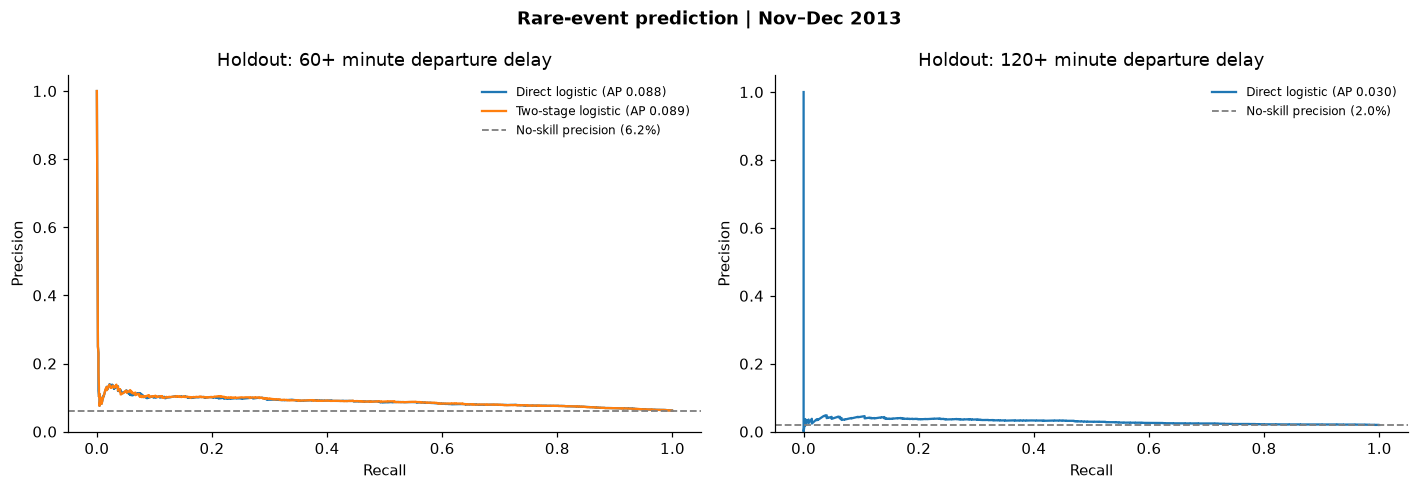

In [21]:
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error

def severity_classifier():
    return Pipeline([('preprocess',ColumnTransformer([
        ('cat',OneHotEncoder(handle_unknown='ignore'),cat),
        ('num',StandardScaler(),nums)])),
        ('classifier',LogisticRegression(max_iter=600,solver='lbfgs'))])

def score_risk(y,p):
    return {'ROC-AUC':roc_auc_score(y,p),'AP':average_precision_score(y,p),
            'Brier':brier_score_loss(y,p)}

severity_predictions={}; severity_rows=[]
for minutes in [60,120]:
    yt=(test.dep_delay>=minutes).astype(int)
    yv=(valid.dep_delay>=minutes).astype(int)
    ytr=(train.dep_delay>=minutes).astype(int)
    direct=severity_classifier();direct.fit(X_train,ytr)
    pdirect_v=direct.predict_proba(X_valid)[:,1]
    pdirect_t=direct.predict_proba(X_test)[:,1]
    baseline_v=np.repeat(ytr.mean(),len(valid));baseline_t=np.repeat(ytr.mean(),len(test))
    candidate={'Constant prior':(baseline_v,baseline_t),'Direct logistic':(pdirect_v,pdirect_t)}
    if minutes==60:
        conditional=severity_classifier()
        subset=(train.dep_delay>=15)
        conditional.fit(X_train.loc[subset],(train.loc[subset,'dep_delay']>=60).astype(int))
        # The stage-1 model is the original train-only Logistic Regression.
        assert 'Logistic Regression' in models
        staged_v=(models['Logistic Regression'].predict_proba(X_valid)[:,1]
                  * conditional.predict_proba(X_valid)[:,1])
        staged_t=(models['Logistic Regression'].predict_proba(X_test)[:,1]
                  * conditional.predict_proba(X_test)[:,1])
        candidate['Two-stage logistic']=(staged_v,staged_t)
    selected=max((k for k in candidate if k!='Constant prior'),
                 key=lambda k: average_precision_score(yv,candidate[k][0]))
    for name,(pv,pt) in candidate.items():
        stats=score_risk(yt,pt)
        severity_rows.append({'Target':f'{minutes}+ min','Model':name,
                              'Validation AP':average_precision_score(yv,pv),
                              'Selected on validation': name==selected, **stats})
    severity_predictions[minutes]=(yt.to_numpy(),candidate,selected)
severity_scores=pd.DataFrame(severity_rows)
display(severity_scores.round(4))
print('All model selections used validation AP only; the test set was not used to choose a model.')
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for ax,(minutes,(yt,candidates,selected)) in zip(axes,severity_predictions.items()):
    for model_name,(pv,pt) in candidates.items():
        prec,rec,_=precision_recall_curve(yt,pt)
        if model_name != 'Constant prior':
            ax.plot(rec,prec,label=f'{model_name} (AP {average_precision_score(yt,pt):.3f})')
    ax.axhline(yt.mean(),color='gray',ls='--',lw=1.2,
               label=f'No-skill precision ({yt.mean():.1%})')
    ax.set_ylim(bottom=0)
    ax.set(xlabel='Recall',ylabel='Precision',title=f'Holdout: {minutes}+ minute departure delay')
    ax.legend(frameon=False,fontsize=8)
fig.suptitle('Rare-event prediction | Nov–Dec 2013',fontweight='bold')
fig.tight_layout();fig.savefig(IMAGES_DIR/'18_severe_delay_pr.png',bbox_inches='tight');plt.show()

## 18. Quantile regression for delay magnitude (P50 and P90)

Among observed flights, define `positive_delay = max(dep_delay, 0)` in minutes, so early departures are zero rather than negative risk. Fit two separate **quantile gradient boosting regressors** for conditional P50 and P90 using training-only data and pre-departure features. Compare against constant training-set quantiles with **pinball loss**, not R². P90 answers a tail-risk question distinct from predicting late/early. Predictions may not be coherent across independently fitted quantiles; crossing is explicitly checked.

**Validation improvement:** Destination-level diagnostics compare *like with like*: realized coverage `mean(actual_delay <= predicted_P90)` and individual-flight **pinball loss** against the constant training-set P90. Averaging flight-level conditional P90 estimates is not equivalent to a destination's observed P90; the earlier bar chart that treated them as comparable has been replaced. Each plotted route has at least 300 test observations.


,Quantile,Baseline constant (min),Model pinball loss,Baseline pinball loss,Observed holdout coverage,Nominal coverage
0,0.5,0.0,6.169,6.169,0.621,0.5
1,0.9,54.0,7.851,7.988,0.916,0.9


P50 > P90 crossing violations: 0 / 17,637


,Destination,n,P90 coverage,P90 model pinball,P90 baseline pinball
0,LAX,1841,0.922,6.027,6.924
1,SFO,1365,0.921,7.113,7.672
2,BOS,958,0.898,9.583,9.004
3,MCO,892,0.926,7.669,7.709
4,SJU,811,0.920,7.892,7.890
5,FLL,700,0.899,7.840,7.647
6,LAS,622,0.950,5.707,6.177
7,MIA,557,0.874,8.276,8.645
8,BUF,554,0.903,11.012,10.630
9,TPA,546,0.945,7.656,7.629


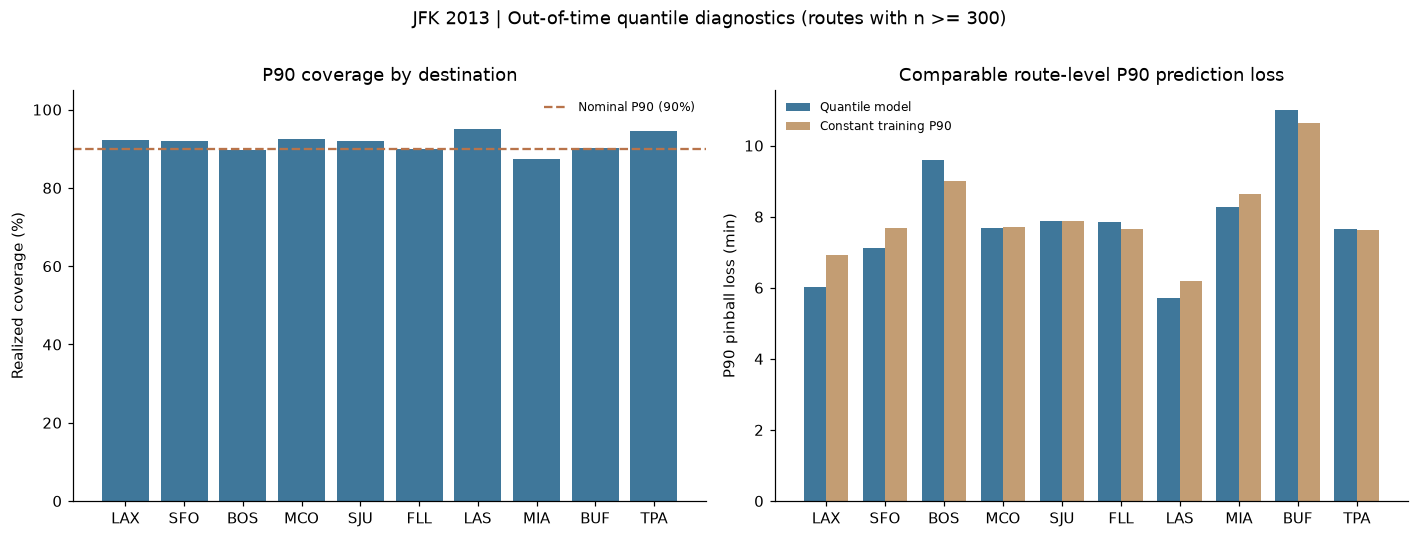

Note: conditional P90 estimates are per-flight quantiles; route-wise means of those estimates are not empirical route P90 values.


In [22]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_pinball_loss

def make_q_model(quantile):
    return Pipeline([
        ('preprocess', ColumnTransformer([
            ('cat',OrdinalEncoder(handle_unknown='use_encoded_value',unknown_value=-1),cat),
            ('num','passthrough',nums)])),
        ('regressor',HistGradientBoostingRegressor(
            loss='quantile',quantile=quantile,max_iter=80,max_leaf_nodes=12,
            min_samples_leaf=150,learning_rate=.075,early_stopping=False,
            categorical_features=[True,True,False,False,False],random_state=42))])

y_train_amount=train.dep_delay.clip(lower=0).to_numpy()
y_test_amount=test.dep_delay.clip(lower=0).to_numpy()
q_predictions={}; q_records=[]
for q in [.5,.9]:
    model=make_q_model(q); model.fit(X_train,y_train_amount)
    estimated=np.clip(model.predict(X_test),0,None)
    constant=float(np.quantile(y_train_amount,q))
    q_predictions[q]=estimated
    q_records.append({'Quantile':q,'Baseline constant (min)':constant,
                     'Model pinball loss':mean_pinball_loss(y_test_amount,estimated,alpha=q),
                     'Baseline pinball loss':mean_pinball_loss(y_test_amount,np.full(len(test),constant),alpha=q),
                     'Observed holdout coverage':np.mean(y_test_amount<=estimated),
                     'Nominal coverage':q})
q_scores=pd.DataFrame(q_records)
display(q_scores.round(3))
q_crossings=int(np.sum(q_predictions[.5]>q_predictions[.9]))
print(f'P50 > P90 crossing violations: {q_crossings:,} / {len(test):,}')
# Route-level evaluation of individual flight P90 predictions, not a comparison
# between empirical route P90 and the mean of individual predicted quantiles.
# Per-route coverage and pinball loss are well-defined and directly comparable.
q_by_route = pd.DataFrame({
    'dest': test.dest.to_numpy(),
    'observed': y_test_amount,
    'predicted_p90': q_predictions[.9],
})
route_sizes = q_by_route.groupby('dest').size().sort_values(ascending=False)
valid_routes = route_sizes[route_sizes.ge(300)].head(10).index
train_p90_constant = float(np.quantile(y_train_amount, .9))
route_diagnostics = []
for destination in valid_routes:
    subset = q_by_route.loc[q_by_route.dest.eq(destination)]
    actual = subset.observed.to_numpy()
    predicted = subset.predicted_p90.to_numpy()
    route_diagnostics.append({
        'Destination': destination,
        'n': len(subset),
        'P90 coverage': float(np.mean(actual <= predicted)),
        'P90 model pinball': float(mean_pinball_loss(actual, predicted, alpha=.9)),
        'P90 baseline pinball': float(mean_pinball_loss(
            actual, np.full(len(actual), train_p90_constant), alpha=.9)),
    })
q_route = pd.DataFrame(route_diagnostics)
display(q_route.round(3))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
x = np.arange(len(q_route))
axes[0].bar(x, q_route['P90 coverage'] * 100, color='#3f779a')
axes[0].axhline(90, ls='--', color='#b8734a', label='Nominal P90 (90%)')
axes[0].set(xticks=x, xticklabels=q_route.Destination, ylim=(0, 105),
            ylabel='Realized coverage (%)', title='P90 coverage by destination')
axes[0].legend(frameon=False, fontsize=8)
bar_width = .38
axes[1].bar(x - bar_width/2, q_route['P90 model pinball'], bar_width,
            label='Quantile model', color='#3f779a')
axes[1].bar(x + bar_width/2, q_route['P90 baseline pinball'], bar_width,
            label='Constant training P90', color='#c39d73')
axes[1].set(xticks=x, xticklabels=q_route.Destination, ylabel='P90 pinball loss (min)',
            title='Comparable route-level P90 prediction loss')
axes[1].legend(frameon=False, fontsize=8)
fig.suptitle('JFK 2013 | Out-of-time quantile diagnostics (routes with n >= 300)',
             fontsize=12, y=1.01)
fig.tight_layout()
fig.savefig(IMAGES_DIR / '19_quantile_route_p90.png', bbox_inches='tight')
plt.show()
q_route.to_csv(RESULTS_DIR / 'quantile_route_validation.csv', index=False)
print('Note: conditional P90 estimates are per-flight quantiles; route-wise means of'
      ' those estimates are not empirical route P90 values.')


## 19. Rolling-origin validation and test uncertainty

The primary model comparison uses one chronological train/validation/test split. Here, refit a *fixed* logistic specification over multiple expanding historical windows inside **January–October only**, then evaluate on the next month. Compare fold AP to that month's prevalence. A single subsequent Nov–Dec holdout remains not used in these rolling training windows (but reviewed across portfolio iterations). Test AP uncertainty is summarized with **date-clustered bootstrap**, acknowledging that only one year of history is available.

,Training,Next month,Train n,Validation n,Prevalence,AP,ROC-AUC,Brier
0,Jan–May,June,44924,9229,0.2900,0.3317,0.5481,0.2085
1,Jan–Jun,July,54153,9812,0.3255,0.3880,0.5770,0.2174
2,Jan–Jul,August,63965,9890,0.2370,0.3089,0.5987,0.1865
3,Jan–Aug,September,73855,8816,0.1461,0.1824,0.5519,0.1523
4,Jan–Sep,October,82671,9108,0.1311,0.1699,0.5570,0.1294


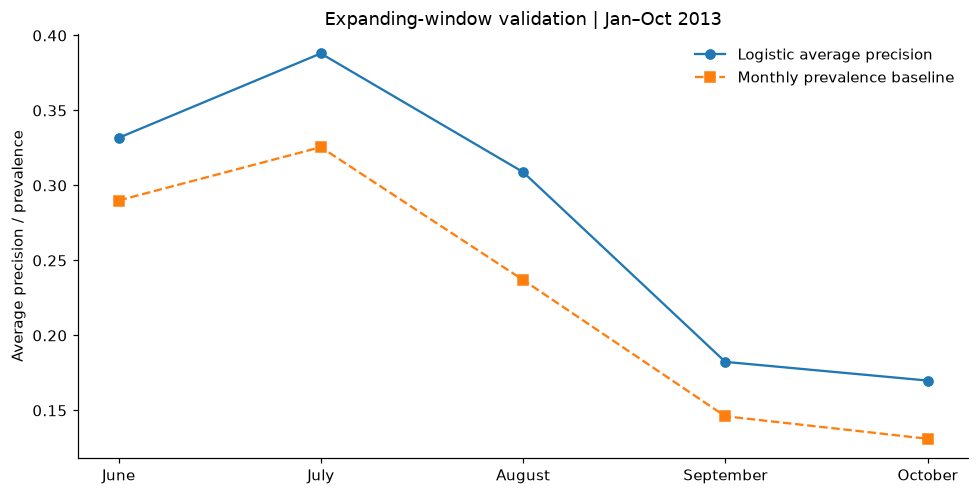

Logistic Nov–Dec test AP 0.252; approximate day-bootstrap 95% interval 0.219–0.290


In [23]:
from sklearn.metrics import average_precision_score
folds=[('Jan–May','June','2013-06-01','2013-07-01'),
       ('Jan–Jun','July','2013-07-01','2013-08-01'),
       ('Jan–Jul','August','2013-08-01','2013-09-01'),
       ('Jan–Aug','September','2013-09-01','2013-10-01'),
       ('Jan–Sep','October','2013-10-01','2013-11-01')]
rolling=[]
for tr_label,va_label,start,end in folds:
    in_train=pred.flight_date<pd.Timestamp(start)
    in_val=(pred.flight_date>=pd.Timestamp(start)) & (pred.flight_date<pd.Timestamp(end))
    fit=clone(logistic);fit.fit(pred.loc[in_train,predictors],pred.loc[in_train,'target'])
    yvfold=pred.loc[in_val,'target'];pvfold=fit.predict_proba(pred.loc[in_val,predictors])[:,1]
    rolling.append({'Training':tr_label,'Next month':va_label,'Train n':int(in_train.sum()),
                   'Validation n':int(in_val.sum()),'Prevalence':yvfold.mean(),
                   'AP':average_precision_score(yvfold,pvfold),
                   'ROC-AUC':roc_auc_score(yvfold,pvfold),
                   'Brier':brier_score_loss(yvfold,pvfold)})
rolling_scores=pd.DataFrame(rolling)
display(rolling_scores.round(4))
fig,ax=plt.subplots(figsize=(9,4.6))
x=np.arange(len(rolling_scores));ax.plot(x,rolling_scores.AP,'o-',label='Logistic average precision')
ax.plot(x,rolling_scores.Prevalence,'s--',label='Monthly prevalence baseline')
ax.set(xticks=x,xticklabels=rolling_scores['Next month'],ylabel='Average precision / prevalence',
       title='Expanding-window validation | Jan–Oct 2013')
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(IMAGES_DIR/'20_rolling_validation.png',bbox_inches='tight');plt.show()
# Resample dates, not individual flights, to approximate uncertainty under day clustering.
test_for_ci=test[['flight_date','target']].copy()
test_for_ci['p']=test_predictions['Logistic Regression']
byday={date:group[['target','p']].to_numpy() for date,group in test_for_ci.groupby('flight_date')}
unique_days=list(byday.keys());rng=np.random.default_rng(99);ap_samples=[]
for _ in range(200):
    dates=rng.choice(len(unique_days),size=len(unique_days),replace=True)
    rows=np.concatenate([byday[unique_days[idx]] for idx in dates],axis=0)
    if np.unique(rows[:,0]).size==2:
        ap_samples.append(average_precision_score(rows[:,0],rows[:,1]))
test_ap_ci=np.quantile(ap_samples,[.025,.975])
print(f'Logistic Nov–Dec test AP {average_precision_score(y_test,test_predictions["Logistic Regression"]):.3f}; '
      f'approximate day-bootstrap 95% interval {test_ap_ci[0]:.3f}–{test_ap_ci[1]:.3f}')

## 20. Weather interaction model and matching sensitivity

The main weather join uses the most recent recorded JFK observation within 90 minutes of the **reconstructed** scheduled clock time. This section extends the weather variables to **recorded precipitation** (`T` = trace; blank = unknown, not dry), and checks an interaction of low visibility and strong wind using a date-clustered logistic GLM with the same route, airline and calendar controls. Weather risk is observational and subject to unobserved confounding, report-interval effects and exposure misclassification. A grid of 45/90/120-minute maximum lookbacks and ±30-minute schedule shifts examines both the **estimated late-rate contrast and the number of flights with usable visibility**. A nearly flat rate-difference line does not imply robust alignment if coverage changes. The observation windows remain tied to an unverified clock proxy.

**Consistent sample:** Every time-shift and lookback comparison below starts from the same clock-eligible flights used in Section 7, not the previously excluded date-boundary group. Section 7A describes why that exclusion changes the eligible analysis population.


,n,rate
weather_group,,
Visibility >=3 mi & wind <15 mph,49796,0.191
Visibility >=3 mi & wind >=15 mph,23361,0.223
Visibility <3 mi & wind <15 mph,2202,0.292
Visibility <3 mi & wind >=15 mph,1082,0.421


,Term,Adjusted_OR,CI_lower,CI_upper,Clustered_p
0,low_vis,1.2160,0.8293,1.7830,0.317
1,strong_wind,1.2677,1.1549,1.3915,<0.001
2,low_vis:strong_wind,1.5636,0.9469,2.5819,0.081
3,precip_flag,1.7863,1.5503,2.0582,<0.001


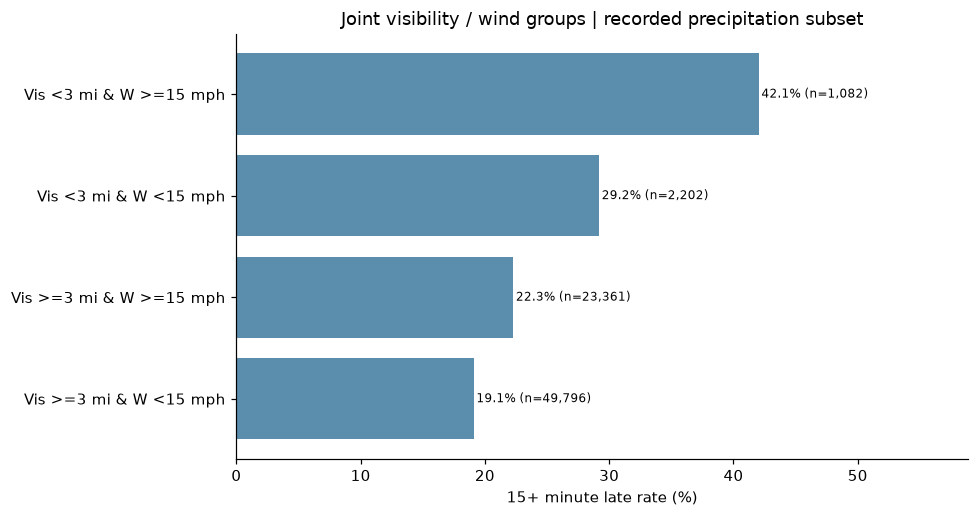

,Shift (min),Max lookback (min),Matched (vis),Low vis n,Rate difference (pp)
0,-30,45,76200,4272,13.97
1,-30,90,87294,4485,13.77
2,-30,120,87294,4485,13.77
3,0,45,74390,4083,12.84
4,0,90,88356,4358,12.79
5,0,120,88356,4358,12.79
6,30,45,74014,4053,11.45
7,30,90,86534,4295,11.53
8,30,120,86534,4295,11.53


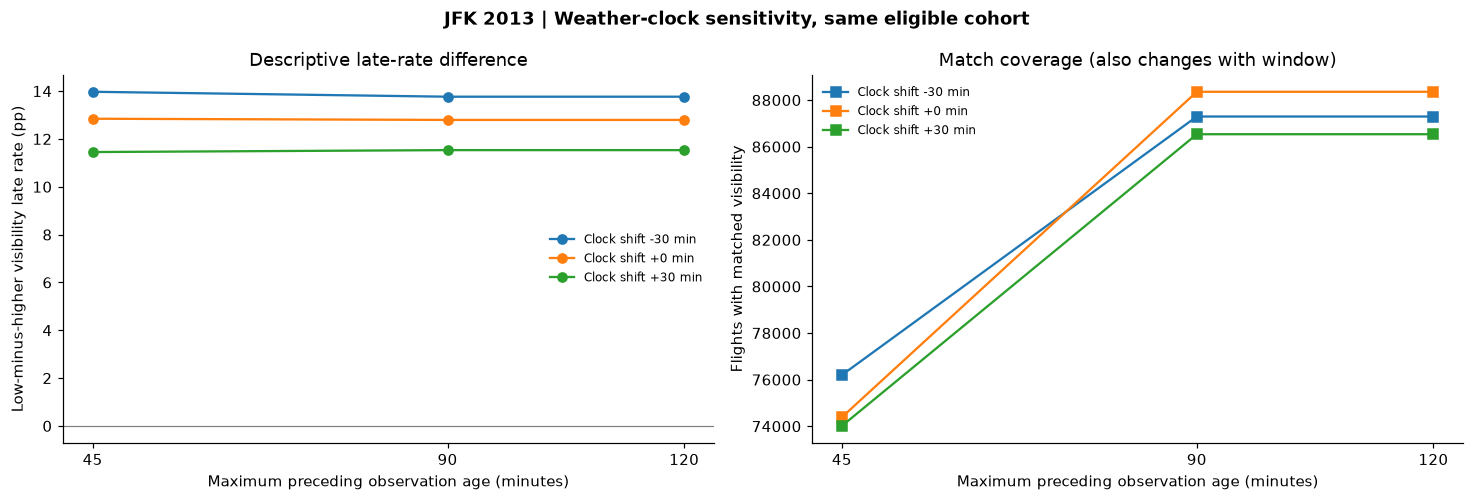

At a zero-minute shift, coverage rises from 74,390 (45-minute lookback) to 88,356 (90 minutes). Extending to 120 minutes gives 88,356; similar rate differences do not mean matching assumptions are verified.


In [24]:
interaction=wx.dropna(subset=['visibility_mi','wind_mph','precip_any','distance']).copy()
interaction['late_int']=interaction.late_15.astype(int)
interaction['low_vis']=(interaction.visibility_mi<3).astype(int)
interaction['strong_wind']=(interaction.wind_mph>=15).astype(int)
interaction['precip_flag']=interaction.precip_any.astype(int)
interaction['weekday_num']=interaction.flight_date.dt.dayofweek.astype(int)
interaction['distance_kmi']=interaction.distance/1000
interaction['route_group']=interaction.dest.where(interaction.dest.isin(top12_dest),'OTHER')
interaction['weather_group']=interaction.low_vis.map({0:'Visibility >=3 mi',1:'Visibility <3 mi'})+' & '+interaction.strong_wind.map({0:'wind <15 mph',1:'wind >=15 mph'})
interaction_groups=(interaction.groupby('weather_group').agg(n=('late_int','size'),
                    rate=('late_int','mean')).sort_values('rate'))
display(interaction_groups.round(3))
if len(interaction)>5000 and min(interaction_groups.n)>=60:
    interaction_formula=('late_int ~ low_vis * strong_wind + precip_flag + '
                         'distance_kmi + C(month) + C(weekday_num) + '
                         'C(carrier) + C(route_group)')
    imodel=smf.glm(interaction_formula,data=interaction,family=sm.families.Binomial()).fit(
        cov_type='cluster',cov_kwds={'groups':interaction.flight_date},maxiter=80)
    iterms=['low_vis','strong_wind','low_vis:strong_wind','precip_flag']
    weather_interaction_table=pd.DataFrame({
        'Term':iterms,'Adjusted_OR':np.exp(imodel.params[iterms].values),
        'CI_lower':np.exp(imodel.conf_int().loc[iterms,0].values),
        'CI_upper':np.exp(imodel.conf_int().loc[iterms,1].values),
        'Clustered_p':imodel.pvalues[iterms].values})
    display(weather_interaction_table.assign(Clustered_p=weather_interaction_table.Clustered_p.map(p_for_display)).round(4))
else:
    weather_interaction_table=pd.DataFrame()
    print('Not enough weather-group coverage for the adjusted interaction model.')
fig,ax=plt.subplots(figsize=(9,4.8))
labels=interaction_groups.index.str.replace('Visibility ','Vis ').str.replace('wind ','W ')
ax.barh(labels,interaction_groups.rate*100,color='#5b8dad')
for i,(val,n) in enumerate(zip(interaction_groups.rate*100,interaction_groups.n)):
    ax.text(val+.2,i,f'{val:.1f}% (n={n:,})',va='center',fontsize=8)
ax.set(xlabel='15+ minute late rate (%)',title='Joint visibility / wind groups | recorded precipitation subset')
ax.set_xlim(0,max(interaction_groups.rate*100)*1.4)
fig.tight_layout();fig.savefig(IMAGES_DIR/'21_weather_interactions.png',bbox_inches='tight');plt.show()

# Recheck as-of matching for the SAME clock-eligible flights as Section 7.
# Clock shifts and lookback changes are sensitivity checks, not a causal experiment.
base_times=flight_times.dropna(subset=['scheduled_departure_est']).sort_values('scheduled_departure_est').copy()
assert len(base_times)==len(flight_times), 'Weather sensitivity must use the Section 7 clock-eligible cohort'
wsel=weather[['weather_time','visibility_mi','wind_mph','precip_any']].sort_values('weather_time')
weather_sensitivity=[]
for time_shift in [-30,0,30]:
    left=base_times.assign(match_time=shift_naive_datetime_minutes(base_times.scheduled_departure_est, time_shift))
    left=left.sort_values('match_time')
    for tolerance in [45,90,120]:
        mm=merge_weather_asof(left,wsel,left_time='match_time',right_time='weather_time',
                         tolerance_minutes=tolerance)
        good=mm.dropna(subset=['visibility_mi']).copy()
        low=good.visibility_mi<3
        rate_low=good.loc[low,'late_15'].mean() if low.sum() else np.nan
        rate_high=good.loc[~low,'late_15'].mean() if (~low).sum() else np.nan
        weather_sensitivity.append({'Shift (min)':time_shift,'Max lookback (min)':tolerance,
            'Matched (vis)':len(good),'Low vis n':int(low.sum()),
            'Rate difference (pp)':(rate_low-rate_high)*100})
weather_sensitivity=pd.DataFrame(weather_sensitivity)
display(weather_sensitivity.round(2))
fig,axes=plt.subplots(1,2,figsize=(13.5,4.6),sharex=True)
for shift,g in weather_sensitivity.groupby('Shift (min)'):
    g=g.sort_values('Max lookback (min)')
    axes[0].plot(g['Max lookback (min)'],g['Rate difference (pp)'],'o-',
                 label=f'Clock shift {shift:+d} min')
    axes[1].plot(g['Max lookback (min)'],g['Matched (vis)'],'s-',
                 label=f'Clock shift {shift:+d} min')
axes[0].set(ylabel='Low-minus-higher visibility late rate (pp)',
            title='Descriptive late-rate difference')
axes[1].set(ylabel='Flights with matched visibility',
            title='Match coverage (also changes with window)')
for ax in axes:
    ax.set_xticks([45,90,120])
    ax.set_xlabel('Maximum preceding observation age (minutes)')
    ax.legend(frameon=False,fontsize=8)
axes[0].axhline(0,color='gray',lw=.8)
fig.suptitle('JFK 2013 | Weather-clock sensitivity, same eligible cohort',fontweight='bold')
fig.tight_layout();fig.savefig(IMAGES_DIR/'22_weather_matching_sensitivity.png',bbox_inches='tight');plt.show()
lookback_45=weather_sensitivity.loc[(weather_sensitivity['Shift (min)']==0)&
                                     (weather_sensitivity['Max lookback (min)']==45),'Matched (vis)'].iloc[0]
lookback_90=weather_sensitivity.loc[(weather_sensitivity['Shift (min)']==0)&
                                     (weather_sensitivity['Max lookback (min)']==90),'Matched (vis)'].iloc[0]
lookback_120=weather_sensitivity.loc[(weather_sensitivity['Shift (min)']==0)&
                                      (weather_sensitivity['Max lookback (min)']==120),'Matched (vis)'].iloc[0]
print(f'At a zero-minute shift, coverage rises from {lookback_45:,} (45-minute lookback) '
      f'to {lookback_90:,} (90 minutes). Extending to 120 minutes gives {lookback_120:,}; '
      'similar rate differences do not mean matching assumptions are verified.')

## 21. Small-route ranking uncertainty: transparent empirical-Bayes shrinkage

Raw rates from small routes can look extreme because of small denominators. Report destination late rates with a **Beta(α, β) regularization prior** whose mean is the observed overall delay rate and whose *assumed* effective sample size is 200 flights (a transparent sensitivity choice, **not fitted hierarchical Bayes**). Compare unadjusted raw and shrunk rate estimates; the shrinkage reflects small-sample uncertainty, not causal airline or route effects. This complements the earlier 1,000-flight Wilson interval view.

,n,late,raw_rate,regularized_rate,shrinkage_pp
dest,,,,,
SDF,43,15,0.349,0.237,11.149
EGE,101,37,0.366,0.265,10.163
MCI,256,89,0.348,0.289,5.889
SMF,282,94,0.333,0.284,4.977
SAT,353,114,0.323,0.283,3.963
BNA,696,212,0.305,0.284,2.036
DEN,699,219,0.313,0.291,2.223
CMH,707,241,0.341,0.313,2.811
CVG,953,346,0.363,0.337,2.596


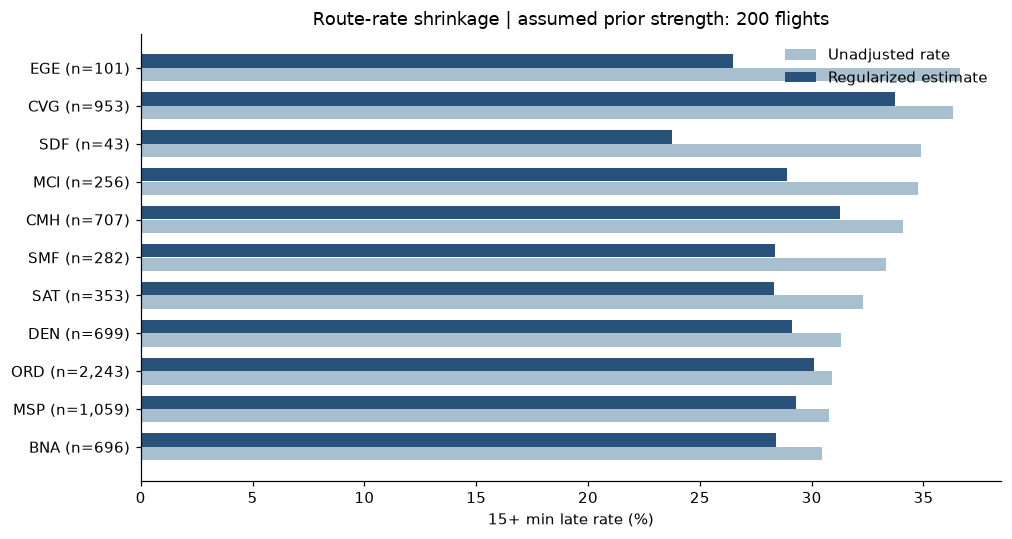

In [25]:
route_all=observed.groupby('dest').agg(n=('late_15','size'),late=('late_15','sum'))
route_all=route_all.loc[route_all.n>=25].copy()
prior_concentration=200
prior_a=observed.late_15.mean()*prior_concentration
prior_b=(1-observed.late_15.mean())*prior_concentration
route_all['raw_rate']=route_all.late/route_all.n
route_all['regularized_rate']=(route_all.late+prior_a)/(route_all.n+prior_a+prior_b)
route_all['shrinkage_pp']=(route_all.raw_rate-route_all.regularized_rate)*100
assert route_all.regularized_rate.between(0,1).all()
small_compare=(route_all.sort_values('raw_rate',ascending=False).head(7)
               .append(route_all.sort_values('regularized_rate',ascending=False).head(7))
               if hasattr(pd.DataFrame,'append') else
               pd.concat([route_all.nlargest(7,'raw_rate'),route_all.nlargest(7,'regularized_rate')]))
small_compare=small_compare.loc[~small_compare.index.duplicated()].sort_values('n')
display(small_compare.round(3))
plot_routes=small_compare.head(12).sort_values('raw_rate',ascending=True)
fig,ax=plt.subplots(figsize=(9.3,5))
y=np.arange(len(plot_routes))
ax.barh(y-.18,plot_routes.raw_rate*100,.35,label='Unadjusted rate',color='#a7bfcf')
ax.barh(y+.18,plot_routes.regularized_rate*100,.35,label='Regularized estimate',color='#28527a')
ax.set(yticks=y,yticklabels=[f'{key} (n={int(row.n):,})' for key,row in plot_routes.iterrows()],
       xlabel='15+ min late rate (%)',title='Route-rate shrinkage | assumed prior strength: 200 flights')
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(IMAGES_DIR/'23_route_rate_shrinkage.png',bbox_inches='tight');plt.show()

## 22. Missingness mechanism and selection sensitivity

A missing `dep_delay` is **not** labeled as a cancellation. Complete-case delay rates estimate an outcome among flights whose delays were recorded; if measurement availability differs across carrier/month, a full-record rate may differ. Check differences without asserting MCAR/MAR/MNAR and show extreme-case bounds where all missing cases are either nonlate or late. These are **sensitivity scenarios, not estimated true rates**. A chi-square association test detects distribution differences but cannot establish the cause of missingness.

,rows,missing,missing_rate
month,,,
1,9161,100,0.0109
2,8421,393,0.0467
3,9697,185,0.0191
4,9218,184,0.0200
5,9397,108,0.0115
6,9472,243,0.0257
7,10023,211,0.0211
8,9983,93,0.0093
9,8908,92,0.0103


,rows,missing,missing_rate
carrier,,,
EV,1408,82,0.0582
9E,14651,807,0.0551
MQ,7193,327,0.0455
AA,13783,141,0.0102
UA,4534,44,0.0097
US,2995,26,0.0087
B6,42076,315,0.0075
VX,3596,21,0.0058
DL,20701,100,0.0048


,Scenario,Numerator,Denominator,Rate
0,Missing flights nonlate,23347,111279,0.2098
1,Measured departures only,23347,109416,0.2134
2,Missing flights late,25210,111279,0.2265


Month missingness association: chi-square p = <0.001 | Carrier: p = <0.001 (descriptive association, NOT a diagnosis of missing-data mechanism)


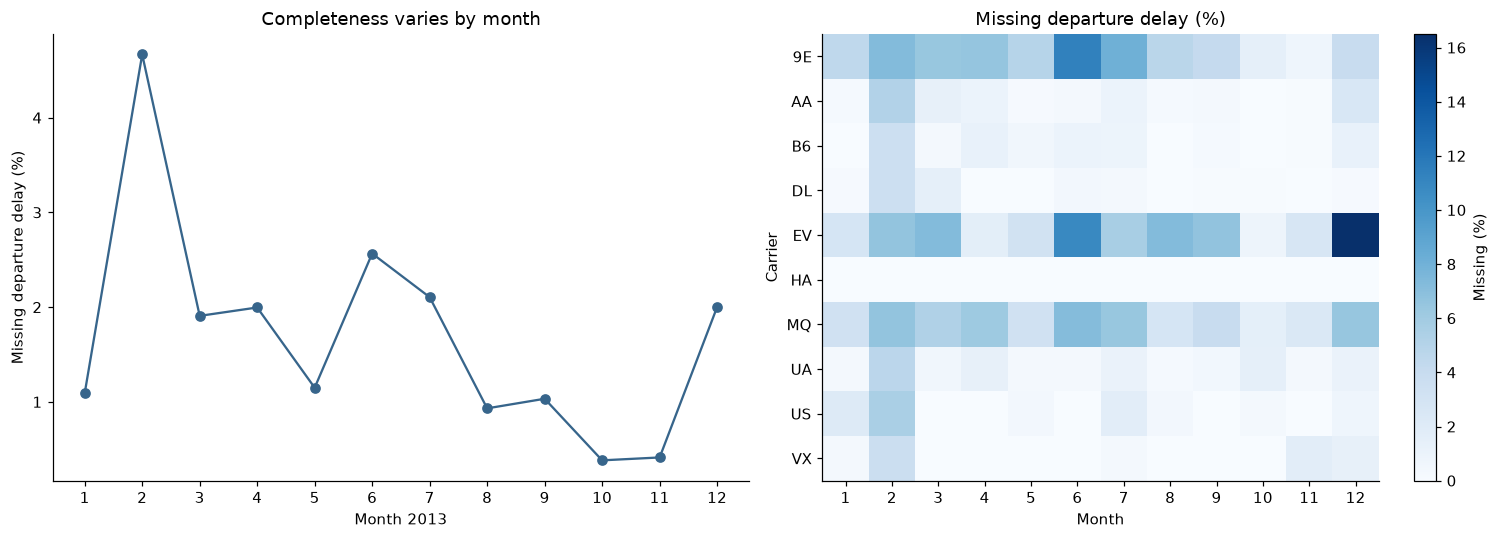

In [26]:
from scipy.stats import chi2_contingency
raw_missing = flights.copy()
raw_missing['missing_dep_delay'] = raw_missing.dep_delay.isna().astype(int)
miss_month = raw_missing.groupby('month').agg(rows=('missing_dep_delay','size'),missing=('missing_dep_delay','sum'))
miss_month['missing_rate'] = miss_month.missing/miss_month.rows
miss_carrier = raw_missing.groupby('carrier').agg(rows=('missing_dep_delay','size'),missing=('missing_dep_delay','sum'))
miss_carrier['missing_rate'] = miss_carrier.missing/miss_carrier.rows
miss_carrier = miss_carrier.sort_values('missing_rate',ascending=False)
miss_grid = raw_missing.pivot_table(index='carrier',columns='month',values='missing_dep_delay',aggfunc='mean')
chi_month = chi2_contingency(pd.crosstab(raw_missing.month,raw_missing.missing_dep_delay))
chi_carrier = chi2_contingency(pd.crosstab(raw_missing.carrier,raw_missing.missing_dep_delay))
n_total=len(flights); n_missing=int(raw_missing.missing_dep_delay.sum()); n_late=int(observed.late_15.sum())
missing_bounds = pd.DataFrame({'Scenario':['Missing flights nonlate','Measured departures only','Missing flights late'],
    'Numerator':[n_late,n_late,n_late+n_missing], 'Denominator':[n_total,len(observed),n_total],
    'Rate':[n_late/n_total,observed.late_15.mean(),(n_late+n_missing)/n_total]})
display(miss_month.round(4));display(miss_carrier.round(4));display(missing_bounds.round(4))
print('Month missingness association: chi-square p =',p_for_display(chi_month.pvalue),
      '| Carrier: p =',p_for_display(chi_carrier.pvalue),
      '(descriptive association, NOT a diagnosis of missing-data mechanism)')
fig,axes=plt.subplots(1,2,figsize=(14,5))
axes[0].plot(miss_month.index,miss_month.missing_rate*100,'o-',color='#37658b')
axes[0].set(xlabel='Month 2013',ylabel='Missing departure delay (%)',title='Completeness varies by month')
axes[0].set_xticks(np.arange(1,13))
a=axes[1]; im=a.imshow(miss_grid.to_numpy()*100,aspect='auto',cmap='Blues',vmin=0)
a.set_xticks(np.arange(12),labels=np.arange(1,13));a.set_yticks(np.arange(len(miss_grid)),labels=miss_grid.index)
a.set(xlabel='Month',ylabel='Carrier',title='Missing departure delay (%)');fig.colorbar(im,ax=a,label='Missing (%)')
fig.tight_layout();fig.savefig(IMAGES_DIR/'24_missingness_heatmap.png',bbox_inches='tight');plt.show()
RESULTS_DIR=PROJECT_DIR/'results';RESULTS_DIR.mkdir(exist_ok=True,parents=True)
miss_month.to_csv(RESULTS_DIR/'missingness_by_month.csv');miss_carrier.to_csv(RESULTS_DIR/'missingness_by_carrier.csv')
missing_bounds.to_csv(RESULTS_DIR/'missingness_bounds.csv',index=False)

## 23. Probability calibration on development months (Platt vs isotonic)

A model can rank delayed flights better without producing trustworthy probabilities. The existing Jan–Aug base logistic model remains **frozen**. Calibrators are fitted on **September only**, choose a mapping by **October Brier score**, and report the selected mapping once on the held-out **November–December** test data. This avoids calibration fitting on the holdout, although the base model's original selection used September–October and is not independent of the calibration development period. Seasonal prevalence shift can still cause miscalibration. Brier and log loss are proper scoring rules; lower values are better. Isotonic may overfit calendar-specific base rates.

**Calibration timeline:** The base Logistic Regression is fitted on **January–August** data. The Platt/Isotonic mapping is fitted exclusively on **September** scores and labels; **October** is used solely to choose the calibration method via Brier score. The chosen mapping is then evaluated on the repeatedly inspected **November–December** historical holdout. No test labels determine the calibration mapping or the selection; this is still not a fresh prospective test.


,October Brier,October LogLoss
Calibration,,
Uncalibrated,0.1543,0.4917
Platt,0.1137,0.3878
Isotonic,0.1141,0.3884


,Selected by October,Test Brier,Test LogLoss,Test AP
Calibration,,,,
Uncalibrated,False,0.1820,0.5510,0.2523
Platt,True,0.1567,0.4917,0.2523
Isotonic,False,0.1566,0.4909,0.2395


Selected by October Brier: Platt


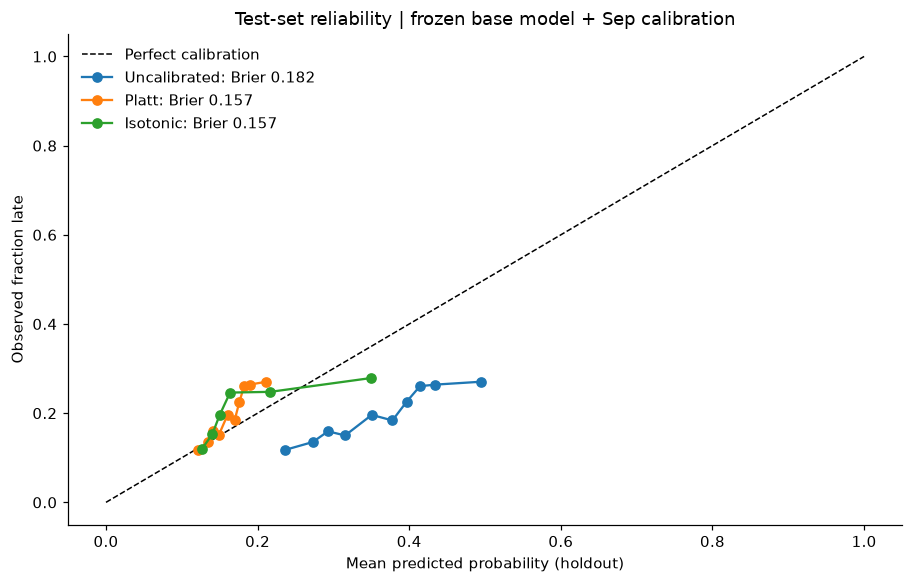

In [27]:
from sklearn.isotonic import IsotonicRegression
from sklearn.linear_model import LogisticRegression as CalibrationLogistic
from sklearn.calibration import calibration_curve
clip_prob=lambda p:np.clip(np.asarray(p,dtype=float),1e-5,1-1e-5)
log_odds=lambda p:np.log(clip_prob(p)/(1-clip_prob(p)))
calbase=models['Logistic Regression']
sep_mask=(valid.flight_date<pd.Timestamp('2013-10-01')).to_numpy()
oct_mask=~sep_mask
sep_y=y_valid.to_numpy()[sep_mask];oct_y=y_valid.to_numpy()[oct_mask]
sep_raw=validation_predictions['Logistic Regression'][sep_mask]
oct_raw=validation_predictions['Logistic Regression'][oct_mask]
test_raw=test_predictions['Logistic Regression']
platt=CalibrationLogistic(max_iter=400,random_state=42).fit(log_odds(sep_raw).reshape(-1,1),sep_y)
iso=IsotonicRegression(out_of_bounds='clip',y_min=0,y_max=1).fit(sep_raw,sep_y)
cal_methods={
 'Uncalibrated':(oct_raw,test_raw),
 'Platt':(platt.predict_proba(log_odds(oct_raw).reshape(-1,1))[:,1],
          platt.predict_proba(log_odds(test_raw).reshape(-1,1))[:,1]),
 'Isotonic':(iso.predict(oct_raw),iso.predict(test_raw)),
}
cal_oct=pd.DataFrame([{'Calibration':name,'October Brier':brier_score_loss(oct_y,p[0]),
    'October LogLoss':log_loss(oct_y,clip_prob(p[0]))} for name,p in cal_methods.items()]).set_index('Calibration')
cal_selected=cal_oct['October Brier'].idxmin()
cal_test=pd.DataFrame([{'Calibration':name,'Selected by October':name==cal_selected,
 'Test Brier':brier_score_loss(y_test,p[1]),'Test LogLoss':log_loss(y_test,clip_prob(p[1])),
 'Test AP':average_precision_score(y_test,p[1])} for name,p in cal_methods.items()]).set_index('Calibration')
display(cal_oct.round(4));display(cal_test.round(4));print('Selected by October Brier:',cal_selected)
fig,ax=plt.subplots(figsize=(8.4,5.4));ax.plot([0,1],[0,1],'k--',label='Perfect calibration',lw=1)
for label,(_,p) in cal_methods.items():
    frac,meanp=calibration_curve(y_test,p,n_bins=10,strategy='quantile')
    ax.plot(meanp,frac,'o-',label=f'{label}: Brier {brier_score_loss(y_test,p):.3f}')
ax.set(xlabel='Mean predicted probability (holdout)',ylabel='Observed fraction late',
 title='Test-set reliability | frozen base model + Sep calibration')
ax.legend(frameon=False);fig.tight_layout()
fig.savefig(IMAGES_DIR/'25_recalibration_reliability.png',bbox_inches='tight');plt.show()
cal_oct.to_csv(RESULTS_DIR/'calibration_october_selection.csv')
cal_test.to_csv(RESULTS_DIR/'calibration_holdout.csv')

## 24. Operational risk concentration: Lift / Precision@K / Cumulative Gains

When review capacity is limited, can the model prioritize flights? Sort **unseen Nov–Dec** records by the original train-only logistic's probability, then measure the fraction of late flights among the top K% and the share of all delayed flights captured. Fixed population prevalence is the no-ranking reference. These are **retrospective triage diagnostics**, not a validated operational benefit or intervention effect. They do not assume perfect probability calibration.

,Top population share,Number reviewed,Precision@K,Recall@K,Lift@K
0,0.05,882,0.272,0.069,1.387
1,0.10,1764,0.270,0.138,1.378
2,0.20,3528,0.267,0.273,1.362
3,0.30,5292,0.265,0.405,1.350
4,0.50,8819,0.241,0.614,1.227
5,1.00,17637,0.196,1.000,1.000


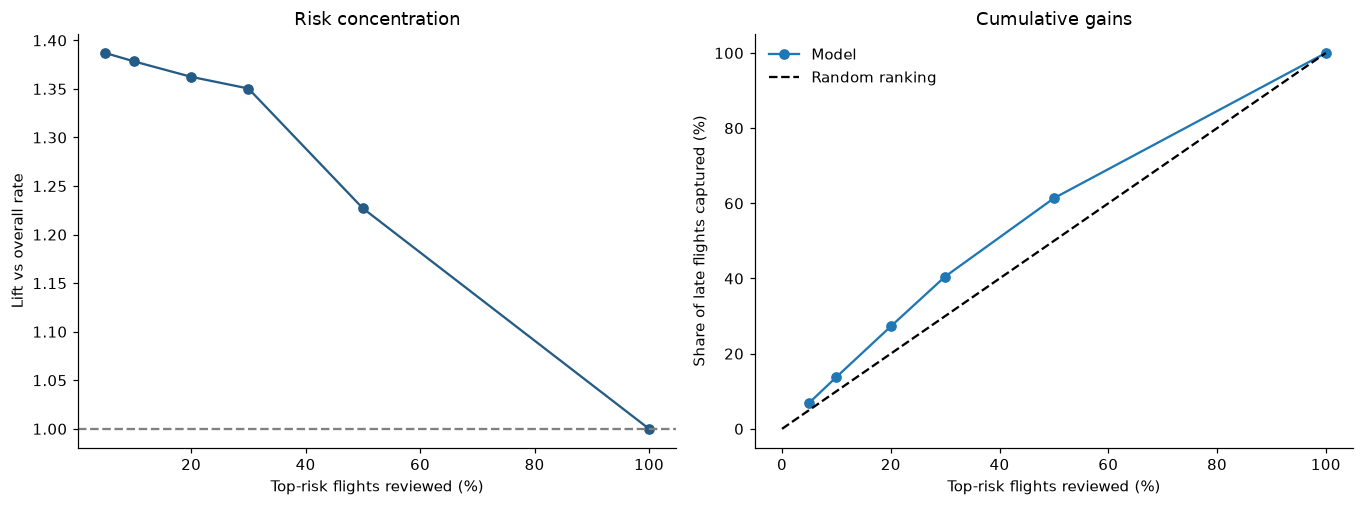

In [28]:
rank_test=pd.DataFrame({'flight_date':test.flight_date.to_numpy(),
                        'y':y_test.to_numpy(),'risk':test_raw})
rank_test=rank_test.sort_values('risk',ascending=False,kind='mergesort').reset_index(drop=True)
base_rate=rank_test.y.mean();total_positive=int(rank_test.y.sum());N=len(rank_test)
ks=[.05,.10,.20,.30,.50,1.0]
rows=[]
for fraction in ks:
    top=rank_test.iloc[:int(np.ceil(N*fraction))]
    precision=float(top.y.mean())
    rows.append({'Top population share':fraction,'Number reviewed':len(top),
       'Precision@K':precision,'Recall@K':float(top.y.sum()/total_positive),
       'Lift@K':precision/base_rate})
lift_metrics=pd.DataFrame(rows)
display(lift_metrics.round(3))
fig,axes=plt.subplots(1,2,figsize=(12.5,4.7))
axes[0].plot(lift_metrics['Top population share']*100,lift_metrics['Lift@K'],'o-',color='#245c85')
axes[0].axhline(1,color='gray',ls='--');axes[0].set(xlabel='Top-risk flights reviewed (%)',ylabel='Lift vs overall rate',title='Risk concentration')
axes[1].plot(lift_metrics['Top population share']*100,lift_metrics['Recall@K']*100,'o-',label='Model')
axes[1].plot([0,100],[0,100],'k--',label='Random ranking')
axes[1].set(xlabel='Top-risk flights reviewed (%)',ylabel='Share of late flights captured (%)',title='Cumulative gains')
axes[1].legend(frameon=False);fig.tight_layout();fig.savefig(IMAGES_DIR/'26_lift_and_gains.png',bbox_inches='tight');plt.show()
lift_metrics.to_csv(RESULTS_DIR/'risk_ranking_lift.csv',index=False)

## 25. Covariate-adjusted same-aircraft departure persistence

Observed repeat departures by a `tailnum` are **not a complete aircraft rotation**, because intermediate inbound/outbound movements at other airports are absent. Estimate an adjusted *association* with the current flight's 15+ minute departure delay after controlling for carrier, destination group, month, weekday, and observed gap hours; use standard errors **clustered by date** to account for shared disruption shocks. This does **not** eliminate all day-level confounding or establish a knock-on causal mechanism. Compare 3–8h and 8–20h gap strata descriptively. The left panel gives one adjusted odds ratio with a 95% date-clustered confidence interval; the right panel shows **unadjusted** late rates within each observed gap group. These quantities answer different questions and should not be read as equivalent effects.

,Effect,Adjusted OR,CI lower,CI upper,Date-clustered p,N
0,Previous departure late (vs not),4.6264,4.2031,5.0922,<0.001,24211


,gap_group,previous_late,n,rate
0,3–<8 hours,0,14129,0.187
1,3–<8 hours,1,2782,0.579
2,8–20 hours,0,6406,0.317
3,8–20 hours,1,894,0.548


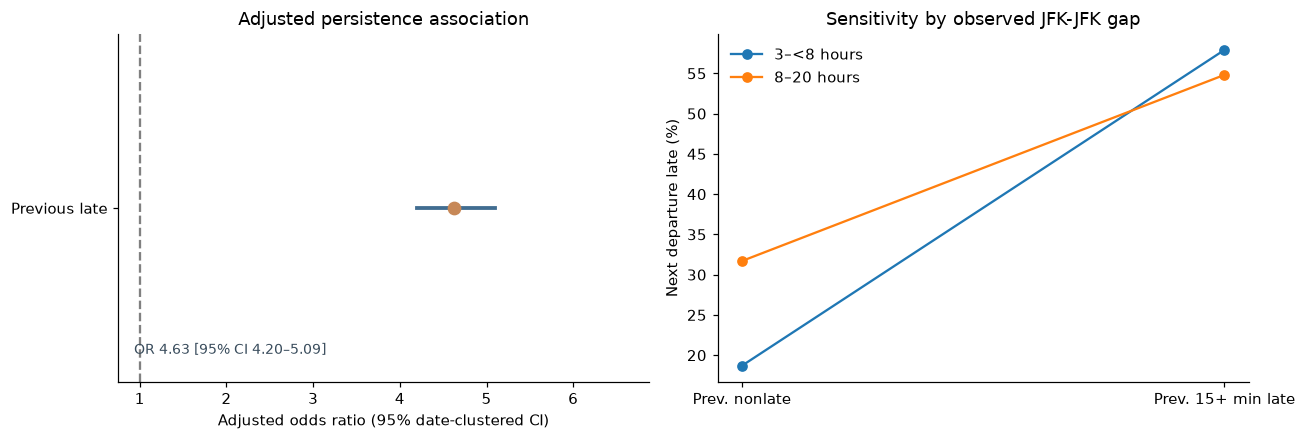

In [29]:
rotation_adj=rotation_pairs.copy()
rotation_adj['month']=rotation_adj.flight_date.dt.month.astype(int)
rotation_adj['weekday_num']=rotation_adj.flight_date.dt.dayofweek.astype(int)
rotation_adj['route_group']=rotation_adj.dest.where(rotation_adj.dest.isin(top12_dest),'OTHER')
rotation_adj=rotation_adj.dropna(subset=['previous_late','current_late','carrier','route_group','gap_hours']).copy()
rot_model=smf.glm('current_late ~ previous_late + gap_hours + C(month) + C(weekday_num) + C(carrier) + C(route_group)',
    data=rotation_adj,family=sm.families.Binomial()).fit(
    cov_type='cluster',cov_kwds={'groups':rotation_adj.flight_date},maxiter=80)
rot_or=float(np.exp(rot_model.params['previous_late']))
rot_ci=np.exp(rot_model.conf_int().loc['previous_late']).to_numpy()
rot_p=float(rot_model.pvalues['previous_late'])
rot_gap=rotation_adj.assign(gap_group=np.where(rotation_adj.gap_hours<8,'3–<8 hours','8–20 hours'))
rot_by_gap=rot_gap.groupby(['gap_group','previous_late']).agg(n=('current_late','size'),rate=('current_late','mean')).reset_index()
rot_effect=pd.DataFrame({'Effect':['Previous departure late (vs not)'],
   'Adjusted OR':[rot_or],'CI lower':[rot_ci[0]],'CI upper':[rot_ci[1]],'Date-clustered p':[rot_p],
   'N':[len(rotation_adj)]})
display(rot_effect.assign(**{'Date-clustered p':rot_effect['Date-clustered p'].map(p_for_display)}).round(4));display(rot_by_gap.round(3))
fig,axes=plt.subplots(1,2,figsize=(12,4.1))
axes[0].plot([rot_ci[0],rot_ci[1]],[0,0],lw=2.5,color='#416d91');axes[0].plot(rot_or,0,'o',ms=8,color='#c78857')
axes[0].axvline(1,ls='--',color='gray')
axes[0].set(yticks=[0],yticklabels=['Previous late'],ylim=(-.8,.8),
            xlim=(.75,max(6.4,rot_ci[1]*1.35)),
            xlabel='Adjusted odds ratio (95% date-clustered CI)',
            title='Adjusted persistence association')
axes[0].text(.03,.08,f'OR {rot_or:.2f} [95% CI {rot_ci[0]:.2f}–{rot_ci[1]:.2f}]',
             transform=axes[0].transAxes,fontsize=9,color='#394c5c')
for group,g in rot_by_gap.groupby('gap_group'):
    g=g.set_index('previous_late').reindex([0,1]);axes[1].plot([0,1],g.rate*100,'o-',label=group)
axes[1].set(xticks=[0,1],xticklabels=['Prev. nonlate','Prev. 15+ min late'],ylabel='Next departure late (%)',title='Sensitivity by observed JFK-JFK gap')
axes[1].legend(frameon=False);fig.tight_layout();fig.savefig(IMAGES_DIR/'27_adjusted_aircraft_persistence.png',bbox_inches='tight');plt.show()
rot_effect.to_csv(RESULTS_DIR/'adjusted_aircraft_association.csv',index=False)
rot_by_gap.to_csv(RESULTS_DIR/'aircraft_gap_sensitivity.csv',index=False)

## 26. Conditional delay magnitude: P50 and P90 once 15+ minutes late

The earlier unconditional P50 delay target often equals zero, so its baseline-like pinball score is expected. As a separate **conditional descriptive forecasting experiment**, train quantile regressors **only on training flights actually delayed ≥15 minutes**, then evaluate on the *actually delayed* held-out flights. The condition uses the true label only to define the estimation target and evaluation subset; **it is not available in advance**. This model **cannot** be advertised as an unconditional pre-departure forecaster without an additional first-stage event probability model. Show pinball loss and nominal coverage versus constant train-quantile baselines.

,Conditional quantile,Train late flights,Holdout late flights,Model pinball loss,Baseline pinball loss,Empirical coverage,Nominal coverage,Baseline quantile minutes
0,0.5,17405,3460,16.904,16.831,0.538,0.5,45.0
1,0.9,17405,3460,12.933,13.066,0.904,0.9,142.0


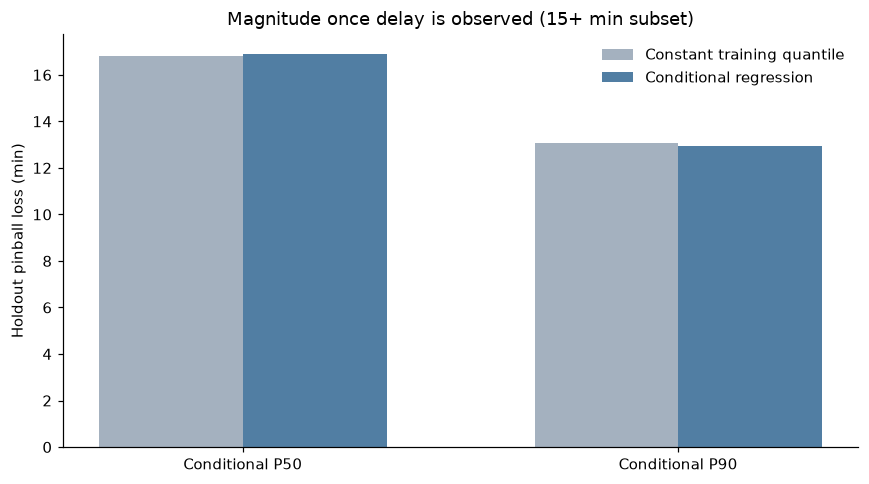

In [30]:
condition_train=train.loc[train.dep_delay>=15].copy()
condition_test=test.loc[test.dep_delay>=15].copy()
cond_scores=[]; cond_predictions={}
assert len(condition_train)>3000 and len(condition_test)>500
for alpha in [.5,.9]:
    mdl=make_q_model(alpha)
    mdl.fit(condition_train[predictors],condition_train.dep_delay.to_numpy())
    p=np.maximum(0,mdl.predict(condition_test[predictors]))
    ref=float(np.quantile(condition_train.dep_delay,alpha))
    truth=condition_test.dep_delay.to_numpy()
    cond_predictions[alpha]=p
    cond_scores.append({'Conditional quantile':alpha,'Train late flights':len(condition_train),
        'Holdout late flights':len(condition_test),'Model pinball loss':mean_pinball_loss(truth,p,alpha=alpha),
        'Baseline pinball loss':mean_pinball_loss(truth,np.repeat(ref,len(truth)),alpha=alpha),
        'Empirical coverage':float(np.mean(truth<=p)),'Nominal coverage':alpha,
        'Baseline quantile minutes':ref})
cond_q=pd.DataFrame(cond_scores)
display(cond_q.round(3))
fig,ax=plt.subplots(figsize=(8,4.5))
xx=np.arange(len(cond_q));w=.33
ax.bar(xx-w/2,cond_q['Baseline pinball loss'],w,label='Constant training quantile',color='#a4b1bf')
ax.bar(xx+w/2,cond_q['Model pinball loss'],w,label='Conditional regression',color='#517ea3')
ax.set(xticks=xx,xticklabels=['Conditional P50','Conditional P90'],ylabel='Holdout pinball loss (min)',title='Magnitude once delay is observed (15+ min subset)')
ax.legend(frameon=False);fig.tight_layout();fig.savefig(IMAGES_DIR/'28_conditional_delay_quantiles.png',bbox_inches='tight');plt.show()
cond_q.to_csv(RESULTS_DIR/'conditional_delay_quantiles.csv',index=False)

## 27. Interpreting the validation results

The models address different tasks: AP measures ranking, Brier score measures probability error, and conditional quantile models examine delay size *after* a delay has occurred. These metrics are reported separately rather than combined into a single accuracy score. The tables below show what improved, what did not, and where the data limit the conclusions.


In [31]:
import json
review_summary = {
 'source_schedule': schedule_audit,
 'missing_dep_delay_count':int(n_missing),
 'monthly_missing_max_pct':float(miss_month.missing_rate.max()*100),
 'missing_lower_rate':float(missing_bounds.Rate.iloc[0]),
 'missing_upper_rate':float(missing_bounds.Rate.iloc[2]),
 'calibration_selected_on_october':cal_selected,
 'calibration_october_metrics':cal_oct.reset_index().to_dict(orient='records'),
 'calibration_nov_dec_metrics':cal_test.reset_index().to_dict(orient='records'),
 'lift_metrics':lift_metrics.to_dict(orient='records'),
 'adjusted_aircraft_or':rot_or,
 'adjusted_aircraft_ci':list(map(float,rot_ci)),
 'adjusted_aircraft_clustered_p':rot_p,
 'conditional_quantiles':cond_q.to_dict(orient='records'),
}
(RESULTS_DIR/'final_review_metrics.json').write_text(json.dumps(review_summary,indent=2,default=float),encoding='utf-8')
comparison = cal_test.loc[cal_selected]
selected_brier=float(comparison['Test Brier']);raw_brier=float(cal_test.loc['Uncalibrated','Test Brier'])
val_top = lift_metrics.loc[np.isclose(lift_metrics['Top population share'],.10)].iloc[0]
review_text=f"""### Model checks in context

- **Missing records:** {n_missing:,} flights have no departure-delay value. The observed 15-minute late rate is {observed.late_15.mean():.1%}. Under the extreme assumptions that all missing values were on time or all were late, the full-file rate would range from {missing_bounds.Rate.iloc[0]:.1%} to {missing_bounds.Rate.iloc[2]:.1%}. These are extreme scenarios, not a confidence interval.
- **Probability estimates:** {cal_selected} calibration lowered the historical test Brier score from {raw_brier:.3f} to {selected_brier:.3f}. That helps on these dates, but it doesn't guarantee the same fit in another season.
- **High-risk group:** The top-scored 10% of test flights had a {val_top['Precision@K']:.1%} late rate, or {val_top['Lift@K']:.2f} times the overall test rate. This describes ranking, not prevented delays.

The aircraft and severity results are discussed separately below. None of these checks turns the 2013 data into an operational forecasting service.
"""
display(Markdown(review_text))

### Model checks in context

- **Missing records:** 1,863 flights have no departure-delay value. The observed 15-minute late rate is 21.3%. Under the extreme assumptions that all missing values were on time or all were late, the full-file rate would range from 21.0% to 22.7%. These are extreme scenarios, not a confidence interval.
- **Probability estimates:** Platt calibration lowered the historical test Brier score from 0.182 to 0.157. That helps on these dates, but it doesn't guarantee the same fit in another season.
- **High-risk group:** The top-scored 10% of test flights had a 27.0% late rate, or 1.38 times the overall test rate. This describes ranking, not prevented delays.

The aircraft and severity results are discussed separately below. None of these checks turns the 2013 data into an operational forecasting service.


## 28. A closer look at severe delays and repeated aircraft

This section puts the additional checks in one place: extreme delays, repeated aircraft departures, the P90 delay model and the stability of rankings through the year. None of these comparisons establish why a particular flight was delayed. The original flight file does not contain enough information to reconstruct a complete aircraft rotation or confirm the true schedule time.


In [32]:
import json
extra_findings=f"""### Severe delays and repeated aircraft: additional checks

- Among {len(rotation_pairs):,} consecutive observed JFK departures on the same aircraft, the next departure was late {p_prev_late:.1%} of the time after a late prior JFK departure, versus {p_prev_on_time:.1%} after an on-time one. Intermediate legs at other airports are not captured, so this finding is an association rather than evidence of direct delay propagation.
- The test-period rate of departures delayed at least 60 minutes was {(test.dep_delay>=60).mean():.1%}. The best development-selected 60-minute classifier achieved AP {severity_scores.loc[(severity_scores.Target=='60+ min') & (severity_scores.Model==severity_predictions[60][2]), 'AP'].iloc[0]:.3f}, against test prevalence {(test.dep_delay>=60).mean():.3f}.
- For the positive-delay P90 model, pinball loss was {q_scores.loc[q_scores.Quantile==.9,'Model pinball loss'].iloc[0]:.2f} versus {q_scores.loc[q_scores.Quantile==.9,'Baseline pinball loss'].iloc[0]:.2f} for a constant training-set quantile. The gain was small.
- Expanding-window validation AP ranged from {rolling_scores.AP.min():.3f} to {rolling_scores.AP.max():.3f}. Model performance changed over 2013, so a single monthly score would hide some of the variation.

These checks point to follow-up data worth collecting: full aircraft rotations, independent scheduled times and reliable weather observation timestamps. The current weather subgroup excludes date-boundary cases, which are examined in Section 7A.
"""
display(Markdown(extra_findings))
results_extra={
 'repeat_aircraft_pairs':int(len(rotation_pairs)),
 'next_late_rate_previous_late':float(p_prev_late),
 'next_late_rate_previous_on_time':float(p_prev_on_time),
 'day_bootstrap_difference_95ci':rotation_diff_ci.tolist(),
 'severity_test_metrics':severity_scores.to_dict(orient='records'),
 'quantile_test_metrics':q_scores.to_dict(orient='records'),
 'rolling_validation':rolling_scores.to_dict(orient='records'),
 'weather_interaction':weather_interaction_table.to_dict(orient='records'),
 'route_prior_effective_flights':int(prior_concentration),
 'schedule_source':'derived from actual clock and departure delay; no independent sched_dep_time'}
RESULTS_DIR=PROJECT_DIR/'results';RESULTS_DIR.mkdir(exist_ok=True,parents=True)
(RESULTS_DIR/'advanced_metrics.json').write_text(json.dumps(results_extra,indent=2,default=float),encoding='utf-8')
rotation_summary.to_csv(RESULTS_DIR/'aircraft_repeat_departure.csv')
severity_scores.to_csv(RESULTS_DIR/'severe_delay_test_scores.csv',index=False)
q_scores.to_csv(RESULTS_DIR/'quantile_test_scores.csv',index=False)
rolling_scores.to_csv(RESULTS_DIR/'rolling_validation.csv',index=False)
weather_interaction_table.to_csv(RESULTS_DIR/'weather_interaction_or.csv',index=False)
weather_sensitivity.to_csv(RESULTS_DIR/'weather_matching_sensitivity.csv',index=False)
route_all.to_csv(RESULTS_DIR/'route_shrinkage.csv')
print('Saved 7 new analysis tables + machine-readable summary under results/.')

### Severe delays and repeated aircraft: additional checks

- Among 24,211 consecutive observed JFK departures on the same aircraft, the next departure was late 57.2% of the time after a late prior JFK departure, versus 22.7% after an on-time one. Intermediate legs at other airports are not captured, so this finding is an association rather than evidence of direct delay propagation.
- The test-period rate of departures delayed at least 60 minutes was 6.2%. The best development-selected 60-minute classifier achieved AP 0.088, against test prevalence 0.062.
- For the positive-delay P90 model, pinball loss was 7.85 versus 7.99 for a constant training-set quantile. The gain was small.
- Expanding-window validation AP ranged from 0.170 to 0.388. Model performance changed over 2013, so a single monthly score would hide some of the variation.

These checks point to follow-up data worth collecting: full aircraft rotations, independent scheduled times and reliable weather observation timestamps. The current weather subgroup excludes date-boundary cases, which are examined in Section 7A.


Saved 7 new analysis tables + machine-readable summary under results/.


## 29. Main findings and next steps

The airport and route comparisons help identify where delays were concentrated in 2013. The weather results are more tentative because the estimated departure clock is derived from the observed delay, and the clock-matching rule excludes some especially late flights (Section 7A). The model improves risk ranking compared with a constant baseline, but it is not reliable enough to use as an operational alert.

A useful next dataset would include actual scheduled departure timestamps, verified timezone information, cancellations and inbound aircraft movements. That would allow a better weather match and a more realistic explanation of repeated delays.


In [33]:
worst_dest=large_routes.late_15_rate.idxmax()
worst_day=worst_days.index[0]
weather_or_low=float(adjusted_weather.loc[adjusted_weather.Term=='Visibility <3 miles','Adjusted_OR'].iloc[0])
weather_ci_low=adjusted_weather.loc[adjusted_weather.Term=='Visibility <3 miles'].iloc[0]
model_best_ap=float(model_scores.loc[winner,'Avg precision'])
model_base_ap=float(model_scores.loc['Constant baseline','Avg precision'])
summary_text=f"""### Main findings from the 2013 data

**Delay patterns.** Among {len(observed):,} flights with a measured departure delay, {observed.late_15.mean():.1%} were 15+ minutes late. For routes with at least 1,000 flights, {worst_dest} had the highest unadjusted rate ({large_routes.loc[worst_dest,'late_15_rate']:.1%}). The most disrupted day among those with 150+ departures was {worst_day:%Y-%m-%d}, at {worst_days.iloc[0].late_rate:.1%}. These comparisons do not tell us what caused the delays.

**Weather: a narrower sample.** Flights excluded by the estimated-clock date boundary had a much higher late rate than flights retained for weather matching (see Section 7A). In the matched and fully observed sample, visibility below 3 miles was associated with an adjusted odds ratio of {weather_or_low:.2f} (95% interval {weather_ci_low.Lower_95:.2f}–{weather_ci_low.Upper_95:.2f}). The missing independent schedule and unresolved weather timezone prevent a causal interpretation or generalization to all flights.

**Prediction: some signal, limited use.** {winner} was selected on development data. Its Nov–Dec AP was {model_best_ap:.3f}, compared with {model_base_ap:.3f} for the constant reference. The test period has been examined repeatedly, and several carrier groups had too many false alarms for an operating alert.

**Recommended next steps.** Verify the flight schedule and weather time conventions, include actual inbound aircraft rotations, and test on another year before interpreting these findings as a basis for operational decisions.
"""
display(Markdown(summary_text))

# Machine-readable metrics for README consistency, in the local project results folder.
import json
report={'records':int(len(flights)),'recorded_departures':int(len(observed)),
 'overall_late_rate':float(observed.late_15.mean()),
 'highest_route_n1000':str(worst_dest),'highest_route_rate':float(large_routes.loc[worst_dest,'late_15_rate']),
 'worst_day_n150':str(worst_day.date()),'worst_day_rate':float(worst_days.iloc[0].late_rate),
 'adjusted_visibility_odds_ratio':weather_or_low,
 'weather_95_ci':[float(weather_ci_low.Lower_95),float(weather_ci_low.Upper_95)],
 'model_selected_on_validation':winner,'test_ap':model_best_ap,
 'baseline_test_ap':model_base_ap,'test_prevalence':float(y_test.mean()),
 'train_n':int(len(train)),'validation_n':int(len(valid)),'test_n':int(len(test))}
RESULTS_DIR=PROJECT_DIR/'results'; RESULTS_DIR.mkdir(parents=True,exist_ok=True)
(RESULTS_DIR/'summary_metrics.json').write_text(json.dumps(report,indent=2),encoding='utf-8')
model_scores.round(6).to_csv(RESULTS_DIR/'model_test_scores.csv')
adjusted_weather.round(6).to_csv(RESULTS_DIR/'adjusted_weather_associations.csv',index=False)
print('Saved report tables to results/.')

### Main findings from the 2013 data

**Delay patterns.** Among 109,416 flights with a measured departure delay, 21.3% were 15+ minutes late. For routes with at least 1,000 flights, ORD had the highest unadjusted rate (30.9%). The most disrupted day among those with 150+ departures was 2013-03-08, at 61.8%. These comparisons do not tell us what caused the delays.

**Weather: a narrower sample.** Flights excluded by the estimated-clock date boundary had a much higher late rate than flights retained for weather matching (see Section 7A). In the matched and fully observed sample, visibility below 3 miles was associated with an adjusted odds ratio of 1.97 (95% interval 1.53–2.53). The missing independent schedule and unresolved weather timezone prevent a causal interpretation or generalization to all flights.

**Prediction: some signal, limited use.** Logistic Regression was selected on development data. Its Nov–Dec AP was 0.252, compared with 0.196 for the constant reference. The test period has been examined repeatedly, and several carrier groups had too many false alarms for an operating alert.

**Recommended next steps.** Verify the flight schedule and weather time conventions, include actual inbound aircraft rotations, and test on another year before interpreting these findings as a basis for operational decisions.


Saved report tables to results/.


## 30. Feature-group ablation — does each input block add out-of-time predictive value?

**Decision question:** Does calendar, airline, destination or distance information actually improve classification beyond simpler alternatives? Compare *the same logistic estimator and regularization* across four pre-specified feature groups. Fit each complete preprocessing pipeline **only on Jan–Aug**. Display Sep–Oct development and chronological Nov–Dec historical holdout (repeatedly inspected during portfolio revision) AP, AUC and Brier. No feature set is optimized on the holdout: test comparisons here are **retrospective diagnostic comparisons**, not an additional test-selected winner. Exclude actual departure, observed weather, and outcome-reconstructed schedule to prevent label leakage. AP should be interpreted relative to changing target prevalence.

,Feature set,Period,N,AP,ROC-AUC,Brier
0,Calendar only,Validation (Sep-Oct),17924,0.1374,0.4868,0.1517
1,Calendar only,Holdout (Nov-Dec),17637,0.2324,0.5684,0.1823
2,Calendar + carrier,Validation (Sep-Oct),17924,0.1661,0.5350,0.1527
3,Calendar + carrier,Holdout (Nov-Dec),17637,0.2551,0.5990,0.1808
4,Calendar + destination,Validation (Sep-Oct),17924,0.1738,0.5548,0.1520
5,Calendar + destination,Holdout (Nov-Dec),17637,0.2421,0.5810,0.1820
6,All planning fields,Validation (Sep-Oct),17924,0.1718,0.5511,0.1533
7,All planning fields,Holdout (Nov-Dec),17637,0.2523,0.5963,0.1820


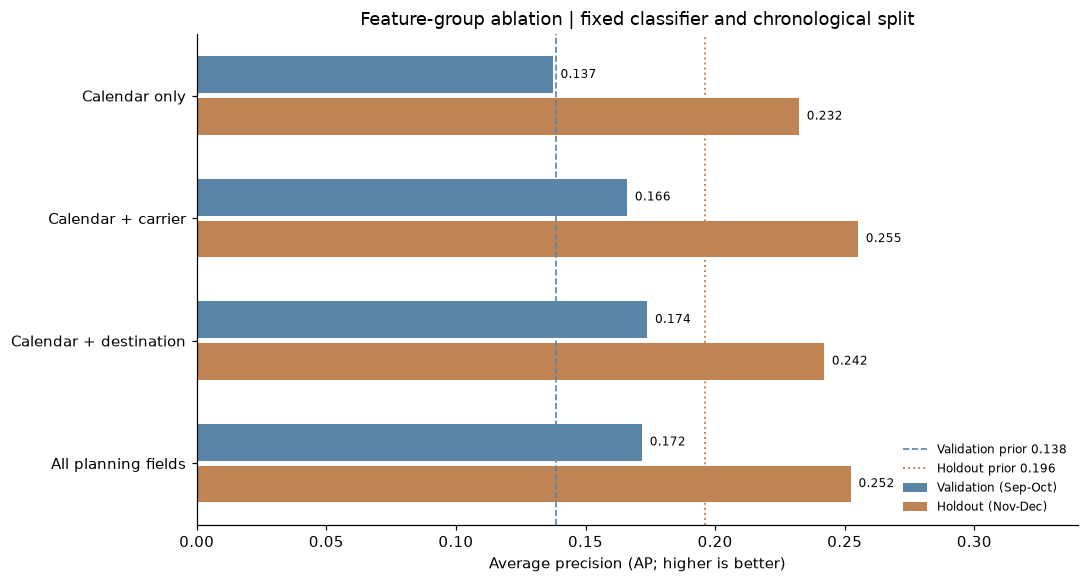

All-feature Logistic AP on holdout: 0.2523 | Original full logistic: 0.2523


In [34]:
# Four pre-specified feature blocks: no holdout-driven tuning.
ablation_groups={
    'Calendar only':['month','weekday_num'],
    'Calendar + carrier':['month','weekday_num','carrier'],
    'Calendar + destination':['month','weekday_num','dest'],
    'All planning fields':['month','weekday_num','carrier','dest','distance'],
}
ablation_rows=[]
for group_name,features in ablation_groups.items():
    categorical=[x for x in features if x in ('carrier','dest')]
    numeric=[x for x in features if x not in categorical]
    transformations=[]
    if categorical:transformations.append(('categorical',OneHotEncoder(handle_unknown='ignore'),categorical))
    if numeric:transformations.append(('numeric',StandardScaler(),numeric))
    model=Pipeline([('preprocess',ColumnTransformer(transformations)),
                    ('classifier',LogisticRegression(max_iter=600,solver='lbfgs'))])
    model.fit(train[features],y_train)
    for split,part,y in [('Validation (Sep-Oct)',valid,y_valid),('Holdout (Nov-Dec)',test,y_test)]:
        scores=model.predict_proba(part[features])[:,1]
        ablation_rows.append({'Feature set':group_name,'Period':split,'N':len(part),
           'AP':average_precision_score(y,scores),'ROC-AUC':roc_auc_score(y,scores),
           'Brier':brier_score_loss(y,scores)})
ablation_table=pd.DataFrame(ablation_rows)
display(ablation_table.round(4))
fig,ax=plt.subplots(figsize=(10,5.4))
feature_order=list(ablation_groups)
yloc=np.arange(len(feature_order))
for ix,(period,shift,col) in enumerate([('Validation (Sep-Oct)',-.17,'#5985a7'),('Holdout (Nov-Dec)',.17,'#c08454')]):
    subset=ablation_table[ablation_table.Period.eq(period)].set_index('Feature set').loc[feature_order]
    ax.barh(yloc+shift,subset.AP,height=.3,label=period,color=col)
    for i,val in enumerate(subset.AP):ax.text(val+.003,yloc[i]+shift,f'{val:.3f}',va='center',fontsize=8)
ax.axvline(y_valid.mean(),ls='--',lw=1.1,color='#5985a7',label=f'Validation prior {y_valid.mean():.3f}')
ax.axvline(y_test.mean(),ls=':',lw=1.25,color='#c08454',label=f'Holdout prior {y_test.mean():.3f}')
ax.set_yticks(yloc,feature_order);ax.invert_yaxis();ax.set_xlim(0,max(.34,ablation_table.AP.max()+.075))
ax.set(xlabel='Average precision (AP; higher is better)',title='Feature-group ablation | fixed classifier and chronological split')
ax.legend(frameon=False,fontsize=8,loc='lower right');fig.tight_layout()
fig.savefig(IMAGES_DIR/'29_feature_ablation.png',bbox_inches='tight');plt.show()
ablation_table.to_csv(RESULTS_DIR/'feature_ablation_metrics.csv',index=False)
full_test_ap=float(ablation_table.query('`Feature set`=="All planning fields" and Period=="Holdout (Nov-Dec)"').AP.iloc[0])
print('All-feature Logistic AP on holdout:',round(full_test_ap,4), '| Original full logistic:',round(float(model_scores.loc['Logistic Regression','Avg precision']),4))


## 31. Holdout error diagnostics — which groups are missed?

Choose the **validation-only F1 threshold** computed in §13 and freeze it before inspecting Nov–Dec. For each carrier with ≥300 measured test departures and ≥20 test delays, compare recall (sensitivity) and false-positive rate; **performance is conditional on the test period and not a carrier safety ranking**. The selection of groups with adequate counts is solely for interpretability, not tuning. Separately tabulate missed 60+ minute departures under the **15+ minute late classifier** to demonstrate why overall discrimination may mask severe errors. Subgroup rates are descriptive without multiplicity adjustments; small cells are suppressed.

**False-alarm interpretation:** For a carrier with a very high false-positive rate, almost all observed non-late flights in that subgroup are incorrectly flagged at the frozen threshold, regardless of how high its recall is. Report both FNR and FPR and do not claim a reliable per-carrier alerting system.


Frozen validation-selected threshold = 0.2760. This is NOT a test-optimized cutoff.


,Carrier,Test N,True late (15+),Late recall,False negative rate,False positive rate,Missed severe (60+),Severe flights
2,B6,6770,1540,0.991,0.009,0.978,3,448
3,DL,3306,465,0.673,0.327,0.631,34,119
1,AA,2166,372,0.820,0.180,0.748,24,125
0,9E,2028,523,0.998,0.002,0.999,1,201
4,MQ,1219,247,1.000,0.000,1.000,0,96
5,UA,753,104,0.356,0.644,0.356,17,30
7,VX,582,91,1.000,0.000,1.000,0,27
6,US,567,68,0.029,0.971,0.028,16,16


,n,late,missed,false_alarms,FN rate
flight_date,,,,,
11,8674,1129,196,5842,0.174
12,8963,2331,172,5764,0.074


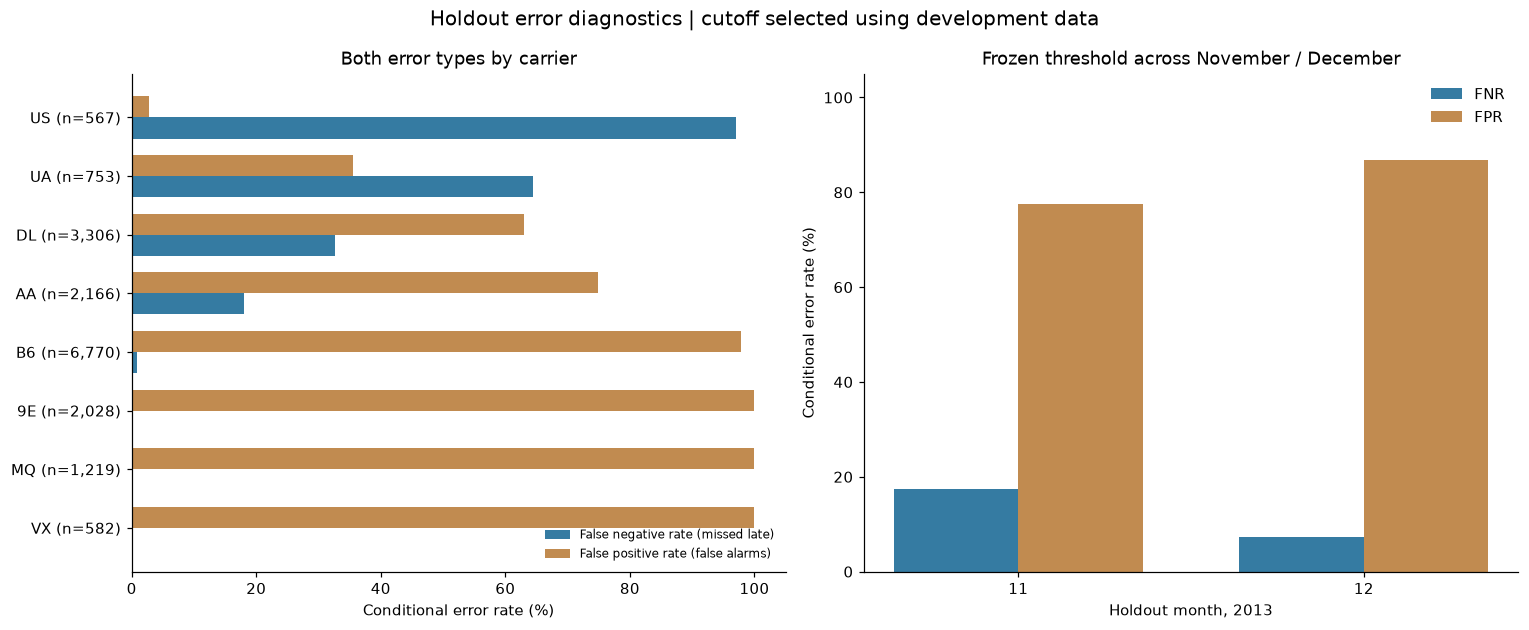

In [35]:
frozen_cutoff=float(chosen_threshold)
error_frame=test[['flight_date','carrier','dest','dep_delay']].copy()
error_frame['actual_late_15']=y_test.to_numpy()
error_frame['risk_score']=test_raw
error_frame['predicted_late_15']=(error_frame.risk_score>=frozen_cutoff).astype(int)
error_frame['false_negative']=((error_frame.actual_late_15==1)&(error_frame.predicted_late_15==0)).astype(int)
error_frame['false_positive']=((error_frame.actual_late_15==0)&(error_frame.predicted_late_15==1)).astype(int)
error_frame['severe_60']=error_frame.dep_delay.ge(60)
error_rows=[]
for airline,g in error_frame.groupby('carrier'):
    positives=int(g.actual_late_15.sum());negatives=int((g.actual_late_15==0).sum())
    if len(g)<300 or positives<20 or negatives<20: continue
    missed=int(g.false_negative.sum());fp=int(g.false_positive.sum())
    error_rows.append({'Carrier':airline,'Test N':len(g),'True late (15+)':positives,
       'Late recall':1-missed/positives,'False negative rate':missed/positives,
       'False positive rate':fp/negatives,'Missed severe (60+)':int((g.severe_60 & g.false_negative.astype(bool)).sum()),
       'Severe flights':int(g.severe_60.sum())})
carrier_errors=pd.DataFrame(error_rows).sort_values('Test N',ascending=False)
month_error=error_frame.groupby(error_frame.flight_date.dt.month).agg(
    n=('actual_late_15','size'),late=('actual_late_15','sum'),missed=('false_negative','sum'),
    false_alarms=('false_positive','sum'))
month_error['FN rate']=month_error.missed/month_error.late
print(f'Frozen validation-selected threshold = {frozen_cutoff:.4f}. This is NOT a test-optimized cutoff.')
display(carrier_errors.round(3));display(month_error.round(3))
fig,axes=plt.subplots(1,2,figsize=(14,5.8))
plot_errors=carrier_errors.sort_values('False negative rate',ascending=True)
ypos=np.arange(len(plot_errors))
axes[0].barh(ypos-.18,plot_errors['False negative rate']*100,height=.36,
             color='#357ba2',label='False negative rate (missed late)')
axes[0].barh(ypos+.18,plot_errors['False positive rate']*100,height=.36,
             color='#c18b50',label='False positive rate (false alarms)')
axes[0].set_yticks(ypos,[f"{r.Carrier} (n={int(r['Test N']):,})" for _,r in plot_errors.iterrows()])
axes[0].set(xlabel='Conditional error rate (%)',title='Both error types by carrier',xlim=(0,105))
axes[0].legend(frameon=False,fontsize=8,loc='lower right')
month_error['FP rate']=month_error.false_alarms/(month_error.n-month_error.late)
mx=np.arange(len(month_error))
axes[1].bar(mx-.18,month_error['FN rate']*100,width=.36,color='#357ba2',label='FNR')
axes[1].bar(mx+.18,month_error['FP rate']*100,width=.36,color='#c18b50',label='FPR')
axes[1].set_xticks(mx,month_error.index.astype(str))
axes[1].set(xlabel='Holdout month, 2013',ylabel='Conditional error rate (%)',
            title='Frozen threshold across November / December',ylim=(0,105))
axes[1].legend(frameon=False)
fig.suptitle('Holdout error diagnostics | cutoff selected using development data',fontsize=13)
fig.tight_layout();fig.savefig(IMAGES_DIR/'30_model_error_subgroups.png',bbox_inches='tight');plt.show()
carrier_errors.to_csv(RESULTS_DIR/'model_error_by_carrier.csv',index=False)
month_error.to_csv(RESULTS_DIR/'model_error_by_month.csv')


## 32. Operational value sensitivity — hypothetical review costs, **not observed savings**

Consider *reviewing* a top-risk fraction of departures. The real project has **no airline labor costs, intervention records, effectiveness estimates or service recovery outcomes**. To illustrate break-even conditions rather than assert financial ROI, define the **unitless net-value proxy** `benefit_per_true_positive × TP − review_cost_per_flagged × flagged`. A true positive here represents a correctly selected historical late flight, *not a demonstrated preventable delay*. For sensitivity analysis, hypothetical benefit/cost ratios of 2, 5, and 10 are assumed. Rank with the frozen logistic risk scores; compare with the expected yield of a random review at equal capacity and an all-review comparator. Cost curves are retrospective on the historical holdout (reviewed during iteration); never use them to claim an intervention would reduce delays. Review fractions are fixed at 0/5/10/20/30/50/100%.

,Benefit/review-cost ratio,Review share,Reviews,True late identified,Recall,"Model net proxy per 1,000","Random expected proxy per 1,000"
0,2,0.00,0,0,0.00,0.00,0.00
1,2,0.05,882,240,0.07,-22.79,-30.39
2,2,0.10,1764,477,0.14,-45.93,-60.77
3,2,0.20,3528,943,0.27,-93.10,-121.55
4,2,0.30,5292,1402,0.41,-141.07,-182.32
5,2,0.50,8819,2123,0.61,-259.28,-303.84
6,2,1.00,17637,3460,1.00,-607.64,-607.64
7,5,0.00,0,0,0.00,0.00,0.00
8,5,0.05,882,240,0.07,18.03,-0.96
9,5,0.10,1764,477,0.14,35.21,-1.91


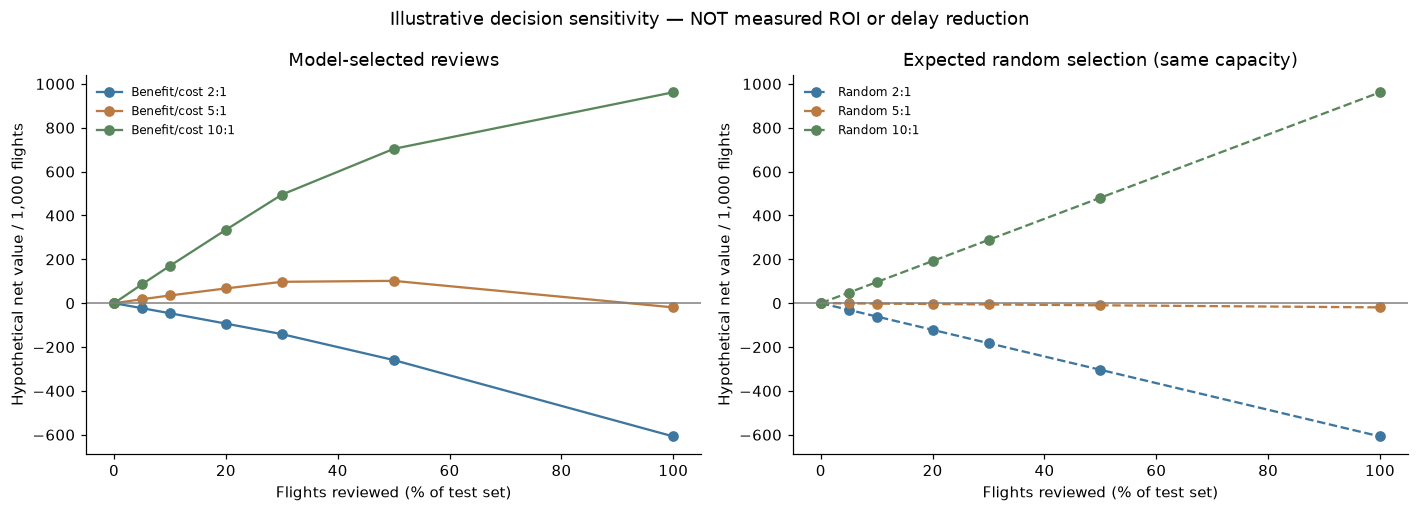

In [36]:
review_shares=[0,.05,.10,.20,.30,.50,1]
benefit_cost_ratios=[2,5,10]
ranked=error_frame.sort_values('risk_score',ascending=False,kind='stable').reset_index(drop=True)
n_holdout=len(ranked);overall_prev=float(ranked.actual_late_15.mean());late_total=int(ranked.actual_late_15.sum())
unit_cost=1.0
cost_rows=[]
for ratio in benefit_cost_ratios:
    for share in review_shares:
        n_review=int(np.ceil(n_holdout*share)) if share else 0
        identified=int(ranked.actual_late_15.iloc[:n_review].sum())
        net=(ratio*identified-unit_cost*n_review)/n_holdout*1000
        # Expected value under random selection at identical workload, not a second stochastic sample.
        random_expected=(ratio*(n_review*overall_prev)-unit_cost*n_review)/n_holdout*1000
        cost_rows.append({'Benefit/review-cost ratio':ratio,'Review share':share,'Reviews':n_review,
         'True late identified':identified,'Recall':identified/max(1,late_total),
         'Model net proxy per 1,000':net,'Random expected proxy per 1,000':random_expected})
cost_sensitivity=pd.DataFrame(cost_rows)
display(cost_sensitivity.round(2))
fig,axes=plt.subplots(1,2,figsize=(13,4.7))
for ratio,col in zip(benefit_cost_ratios,['#3d779f','#ba7b43','#59875b']):
    subset=cost_sensitivity[cost_sensitivity['Benefit/review-cost ratio'].eq(ratio)]
    axes[0].plot(subset['Review share']*100,subset['Model net proxy per 1,000'],marker='o',color=col,label=f'Benefit/cost {ratio}:1')
    axes[1].plot(subset['Review share']*100,subset['Random expected proxy per 1,000'],marker='o',ls='--',color=col,label=f'Random {ratio}:1')
axes[0].axhline(0,color='gray',lw=1);axes[1].axhline(0,color='gray',lw=1)
axes[0].set(title='Model-selected reviews',ylabel='Hypothetical net value / 1,000 flights')
axes[1].set(title='Expected random selection (same capacity)',ylabel='Hypothetical net value / 1,000 flights')
for ax in axes:
    ax.set_xlabel('Flights reviewed (% of test set)');ax.legend(frameon=False,fontsize=8)
fig.suptitle('Illustrative decision sensitivity — NOT measured ROI or delay reduction',fontsize=12)
fig.tight_layout();fig.savefig(IMAGES_DIR/'31_operational_cost_sensitivity.png',bbox_inches='tight');plt.show()
cost_sensitivity.to_csv(RESULTS_DIR/'operational_cost_scenarios.csv',index=False)


## 33. Paired date-block bootstrap — uncertainty in model performance differences

Hold fixed the Nov–Dec predictions from the previously **trained** logistic, boosting and constant-prior models. Sample whole test dates (not individual flight rows) with replacement in **350 paired bootstrap replicates** and recompute **average precision (AP)** and **ROC-AUC** differences on the *same sampled flights*. This preserves within-date groupings better than flight-level resampling; it is still an approximate historical test-window CI, excludes model refitting uncertainty and does not establish transportability to later years. A 95% percentile interval crossing zero means the observed difference is not robustly distinguishable from zero under this resampling scheme. Differences are **in metric units**, not percentages.

,Comparison,Metric,Observed difference,Lower 95%,Upper 95%,Bootstrap samples,Interval includes 0
0,Logistic - Boosting,AP difference,0.0216,0.0058,0.0372,350,False
1,Logistic - Boosting,ROC-AUC difference,0.0341,0.0130,0.0499,350,False
2,Logistic - Constant,AP difference,0.0562,0.0424,0.0701,350,False
3,Logistic - Constant,ROC-AUC difference,0.0963,0.0801,0.1090,350,False


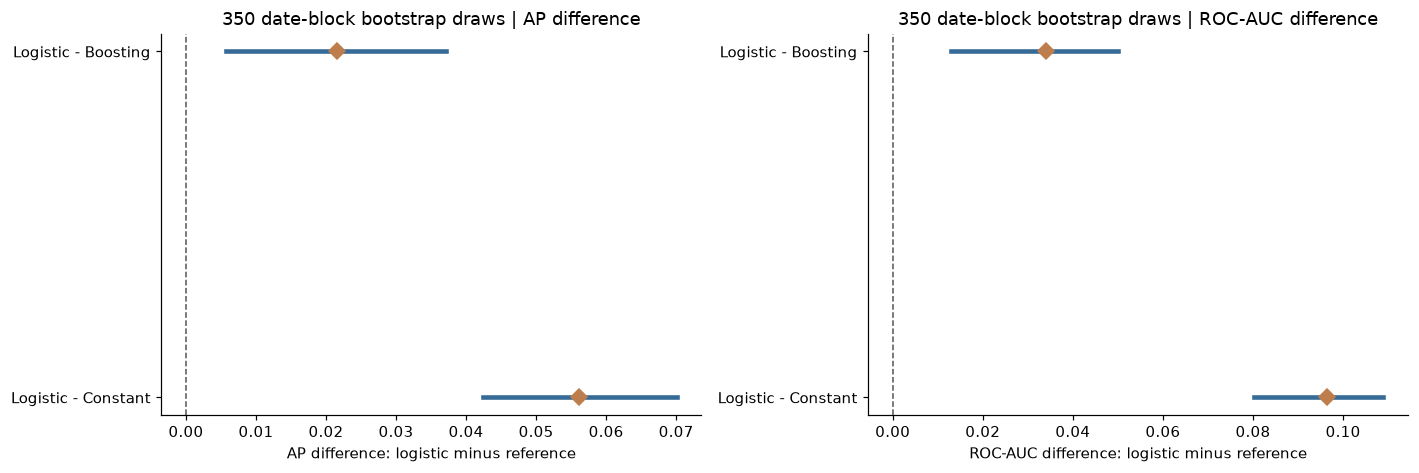

In [37]:
from sklearn.metrics import roc_auc_score
rng=np.random.default_rng(42)
y_true=y_test.to_numpy().astype(int)
p_log=np.asarray(test_predictions['Logistic Regression'])
p_boost=np.asarray(test_predictions['Gradient Boosting'])
p_prior=np.asarray(test_predictions['Constant baseline'])
# Test.frame and y_test have identical row order; groups are complete calendar days.
date_label=test.flight_date.to_numpy(dtype='datetime64[D]')
unique_days,day_code=np.unique(date_label,return_inverse=True)
day_indices=[np.flatnonzero(day_code==j) for j in range(len(unique_days))]
B=350
boot_rows=[]
for b in range(B):
    selected_days=rng.integers(0,len(unique_days),size=len(unique_days))
    idx=np.concatenate([day_indices[j] for j in selected_days])
    yb=y_true[idx]
    if yb.min()==yb.max():continue
    for comparison,label,alternative in [('Logistic - Boosting','Gradient Boosting',p_boost),
                                          ('Logistic - Constant','Constant baseline',p_prior)]:
        ap_diff=average_precision_score(yb,p_log[idx])-average_precision_score(yb,alternative[idx])
        roc_diff=roc_auc_score(yb,p_log[idx])-roc_auc_score(yb,alternative[idx])
        boot_rows.append({'Iteration':b,'Comparison':comparison,'AP difference':ap_diff,'ROC-AUC difference':roc_diff})
bootstrap_draws=pd.DataFrame(boot_rows)
comparison_scores=[]
for comparison,alternative in [('Logistic - Boosting',p_boost),('Logistic - Constant',p_prior)]:
    sub=bootstrap_draws.loc[bootstrap_draws.Comparison.eq(comparison)]
    for metric,func in [('AP difference',average_precision_score),('ROC-AUC difference',roc_auc_score)]:
        boot=sub[metric].to_numpy()
        observed_diff=func(y_true,p_log)-func(y_true,alternative)
        lo,hi=np.percentile(boot,[2.5,97.5])
        comparison_scores.append({'Comparison':comparison,'Metric':metric,'Observed difference':observed_diff,
          'Lower 95%':lo,'Upper 95%':hi,'Bootstrap samples':len(boot),'Interval includes 0':bool(lo<=0<=hi)})
bootstrap_summary=pd.DataFrame(comparison_scores)
display(bootstrap_summary.round(4))
fig,axes=plt.subplots(1,2,figsize=(13,4.4))
for ax,metric in zip(axes,['AP difference','ROC-AUC difference']):
    sub=bootstrap_summary[bootstrap_summary.Metric.eq(metric)]
    for j,(_,record) in enumerate(sub.iterrows()):
        lo,hi=record['Lower 95%'],record['Upper 95%'];pt=record['Observed difference']
        ax.plot([lo,hi],[j,j],lw=3,color='#356b96');ax.plot(pt,j,marker='D',ms=7,color='#bd7d4c')
    ax.axvline(0,ls='--',color='#555555',lw=1)
    ax.set_yticks(range(len(sub)),sub.Comparison.tolist());ax.invert_yaxis()
    ax.set(xlabel=f'{metric}: logistic minus reference',title=f'350 date-block bootstrap draws | {metric}')
fig.tight_layout();fig.savefig(IMAGES_DIR/'32_model_difference_bootstrap.png',bbox_inches='tight');plt.show()
bootstrap_summary.to_csv(RESULTS_DIR/'paired_bootstrap_summary.csv',index=False)
bootstrap_draws.to_csv(RESULTS_DIR/'paired_bootstrap_draws.csv',index=False)


## 34. Export decision diagnostics for documentation

The model comparisons, risk ranking, feature-ablation tables, subgroup error rates and date-block uncertainty are exported here for reproducible reporting. The **single final Executive Summary Dashboard** is generated in Section 40, after the monthly and cost-uncertainty studies. These are retrospective diagnostics of a repeatedly inspected historical holdout.


In [38]:
# Consolidated decision metrics: one final dashboard is created in Section 40.
metric_ap = float(model_scores.loc['Logistic Regression', 'Avg precision'])
metric_baseline = float(model_scores.loc['Constant baseline', 'Avg precision'])
metric_brier = float(cal_test.loc[cal_selected, 'Test Brier'])
share10 = lift_metrics.loc[np.isclose(lift_metrics['Top population share'], .1)].iloc[0]
plot_boot = bootstrap_summary.query('Metric == "AP difference"')
new_metrics={'ablation':ablation_table.to_dict(orient='records'),
 'subgroup_test_error':carrier_errors.to_dict(orient='records'),
 'validation_fixed_cutoff':frozen_cutoff,'hypothetical_cost':cost_sensitivity.to_dict(orient='records'),
 'bootstrap':bootstrap_summary.to_dict(orient='records'),
 'dashboard':{'flight_count':len(flights),'observed_late_rate':float(observed.late_15.mean()),
              'test_logistic_ap':metric_ap,'test_baseline_ap':metric_baseline,'test_calibrated_brier':metric_brier}}
(RESULTS_DIR/'decision_ready_metrics.json').write_text(json.dumps(new_metrics,indent=2,default=float),encoding='utf-8')
print('Saved core decision diagnostics to decision_ready_metrics.json; final visual appears in Section 40.')


Saved core decision diagnostics to decision_ready_metrics.json; final visual appears in Section 40.


## 35. Model checks: what worked, and what did not

**Simpler features held up well.** The calendar + carrier model scored AP 0.255 on the repeatedly inspected Nov–Dec period, compared with 0.252 using every planning variable. The small difference is not a reason to pick a new model after seeing test results.

**The alarm threshold was not usable as-is.** The validation-selected F1 cutoff (0.276) flagged too many on-time flights for several carriers. High recall looks attractive in isolation, but these false alarms would create a substantial review workload.

**Ranking and business value are not the same.** Reviewing the top-scored 10% identified 477 late departures among 1,764 reviewed flights. At an assumed 2:1 benefit-to-review-cost ratio the net-value proxy remained negative. These values are hypothetical units, not measured savings.

**There is still substantial uncertainty.** Date-block bootstrap results favored Logistic Regression over Gradient Boosting on this historical test period, but the data come from one year and were repeatedly examined during project development.

The main value of these models is the comparison and error analysis. A real deployment would need fresher data, verified scheduled times, a predefined workload and known review costs.


## 36. Monthly Top-K stability — does risk concentration persist in November *and* December?

**Decision question:** Would a fixed 10% review *capacity per month* identify above-average delays in **both** later holdout months? The model is not re-trained or threshold-tuned; within each month, flights are simply sorted by their **original frozen Logistic Regression probabilities**. This monthly top-decile policy is **different** from ranking the entire two-month sample at once. Report Precision@10%, Recall@10%, Lift@10%, late-rate baselines and Wilson 95% binomial intervals on precision. The month-specific results are *post-hoc diagnostics* on an already repeatedly inspected 2013 test window, not independent deployment validation.

,Month,Flights,Observed late,Prevalence,Reviews in top 10%,Late found,Precision@10%,Precision lower 95%,Precision upper 95%,Recall@10%,Lift@10%
0,11,8674,1129,0.1302,868,139,0.1601,0.1372,0.1860,0.1231,1.2303
1,12,8963,2331,0.2601,897,320,0.3567,0.3261,0.3886,0.1373,1.3717


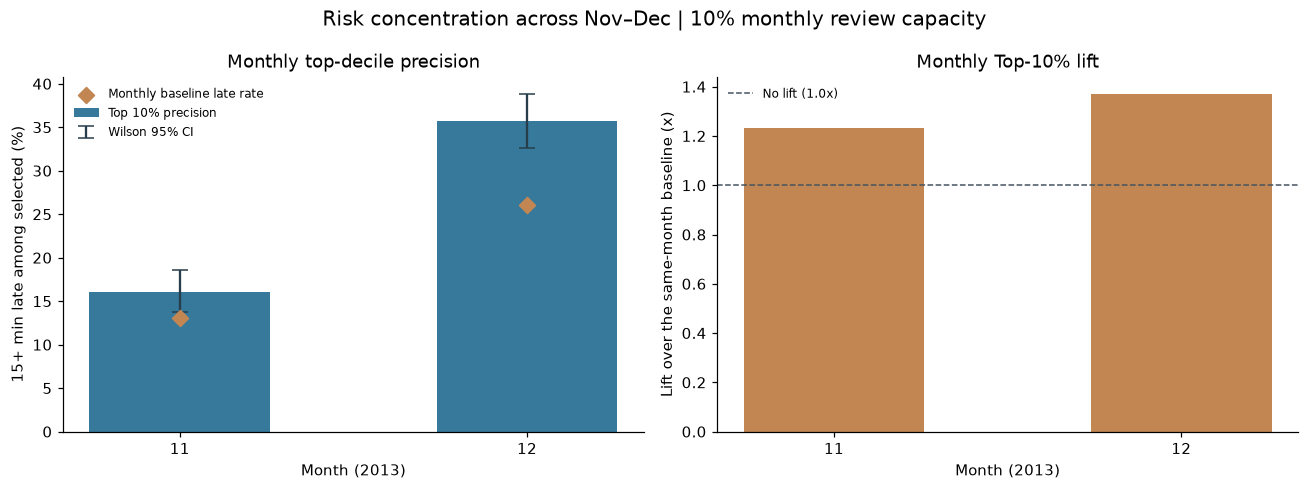

Caution: only two later months; confidence intervals do not establish future-year stability.


In [39]:
# Test months only: same frozen predictions; month-specific capacity constraint.
monthly_rows=[]
for m,g in error_frame.groupby(error_frame.flight_date.dt.month):
    gs=g.sort_values('risk_score',ascending=False,kind='stable')
    n=len(gs);k=int(np.ceil(.10*n)); selected=gs.head(k)
    prevalence=g.actual_late_15.mean()
    tp=int(selected.actual_late_15.sum())
    precision=tp/k
    ci_lo,ci_hi=wilson_ci(tp,k)
    monthly_rows.append({'Month':int(m),'Flights':n,'Observed late':int(g.actual_late_15.sum()),
      'Prevalence':prevalence,'Reviews in top 10%':k,'Late found':tp,
      'Precision@10%':precision,'Precision lower 95%':float(ci_lo),'Precision upper 95%':float(ci_hi),
      'Recall@10%':tp/max(1,int(g.actual_late_15.sum())),'Lift@10%':precision/max(prevalence,1e-12)})
monthly_topk=pd.DataFrame(monthly_rows).sort_values('Month')
display(monthly_topk.round(4))
fig,axs=plt.subplots(1,2,figsize=(12,4.5))
x=np.arange(len(monthly_topk));precision=monthly_topk['Precision@10%'].to_numpy()
low=monthly_topk['Precision lower 95%'].to_numpy();high=monthly_topk['Precision upper 95%'].to_numpy()
axs[0].bar(x,precision*100,color='#36799b',width=.52,label='Top 10% precision')
axs[0].errorbar(x,precision*100,yerr=np.vstack([(precision-low)*100,(high-precision)*100]),
     fmt='none',ecolor='#283d4c',capsize=5,label='Wilson 95% CI')
axs[0].scatter(x,monthly_topk.Prevalence*100,marker='D',color='#c28652',s=55,zorder=3,label='Monthly baseline late rate')
axs[0].set(xlabel='Month (2013)',ylabel='15+ min late among selected (%)',title='Monthly top-decile precision')
axs[0].set_xticks(x,monthly_topk.Month.astype(str));axs[0].legend(frameon=False,fontsize=8)
axs[1].bar(x,monthly_topk['Lift@10%'],color='#c28652',width=.52)
axs[1].axhline(1,color='#455460',lw=1,ls='--',label='No lift (1.0x)')
axs[1].set(xlabel='Month (2013)',ylabel='Lift over the same-month baseline (x)',title='Monthly Top-10% lift')
axs[1].set_xticks(x,monthly_topk.Month.astype(str));axs[1].legend(frameon=False,fontsize=8)
fig.suptitle('Risk concentration across Nov–Dec | 10% monthly review capacity',fontsize=13)
fig.tight_layout();fig.savefig(IMAGES_DIR/'34_monthly_topk_stability.png',bbox_inches='tight');plt.show()
monthly_topk.to_csv(RESULTS_DIR/'monthly_topk_stability.csv',index=False)
print('Caution: only two later months; confidence intervals do not establish future-year stability.')

## 37. Illustrative net-value uncertainty — date-block bootstrap

**Decision question:** At a fixed **top-10% holdout review capacity**, how sensitive are model-ranked and random-review net-value *proxies* to variation across days? The analysis retains the existing hypothetical utility **R × correctly identified late departures − 1 × reviewed flights**, per 1,000 recorded test flights, under three **assumed** benefit/review-cost ratios (2:1, 5:1, 10:1). Neither ratio nor the unit is money or measured operational savings. **Whole dates** are resampled with replacement (fixed trained models, 500 replicates), re-rank within each resampled pseudo-period, and estimate percentile 95% intervals for model-selected, expected random, and model-minus-random value. This is not an experimental intervention; it omits retraining uncertainty, unknown airport resource costs, and cross-year transportability.

,Ratio,Method,Point,Lower 95%,Upper 95%,B
0,2,Model,-45.93,-55.16,-37.02,500
1,2,Random expected,-60.77,-65.98,-55.61,500
2,2,Model minus random,14.85,10.43,19.36,500
3,5,Model,35.21,12.13,57.47,500
4,5,Random expected,-1.91,-14.88,11.03,500
5,5,Model minus random,37.12,26.08,48.40,500
6,10,Model,170.44,124.27,214.94,500
7,10,Random expected,96.19,70.29,122.08,500
8,10,Model minus random,74.24,52.17,96.81,500


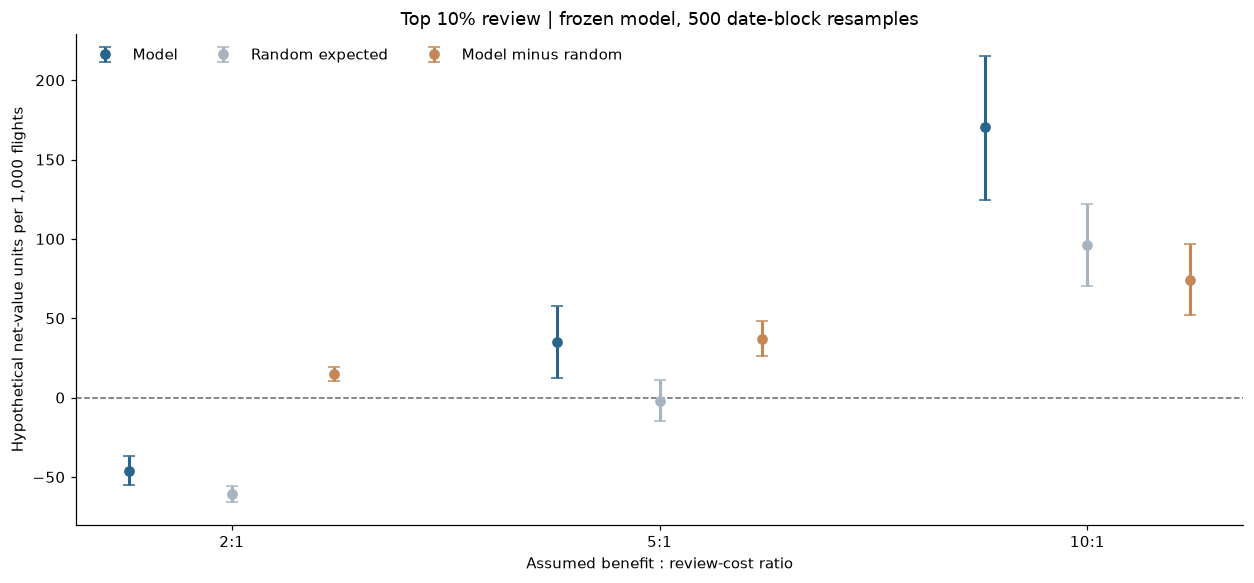

Intervals describe sampling-day variability under invented utilities — not ROI, saved money, or a proven intervention.


In [40]:
# Date-cluster bootstrap of hypothetical review net proxy: monthly blocks are not mixed with training.
from numpy.random import default_rng
risk_values=error_frame.risk_score.to_numpy(dtype=float)
outcomes=error_frame.actual_late_15.to_numpy(dtype=int)
date_val=error_frame.flight_date.to_numpy(dtype='datetime64[D]')
unique_date,group_idx=np.unique(date_val,return_inverse=True)
indices_by_day=[np.flatnonzero(group_idx==i) for i in range(len(unique_date))]
random_state=default_rng(20261018)
bootstrap_runs=500;bootstrap_share=.10;ratios=(2,5,10)

def net_value_components(indices,ratio):
    labels=outcomes[indices];scores=risk_values[indices]
    n=len(indices);k=max(1,int(np.ceil(bootstrap_share*n)))
    # Rank by prior fitted predictions (do not recalibrate or retune here).
    top=np.argpartition(-scores,k-1)[:k]
    tp=int(labels[top].sum());prev=float(labels.mean())
    model=(ratio*tp-k)/n*1000
    random=(ratio*k*prev-k)/n*1000
    return model,random,model-random

rows=[]
original_idx=np.arange(len(outcomes))
for ratio in ratios:
    model,random_ref,increment=net_value_components(original_idx,ratio)
    rows.append({'Ratio':ratio,'Method':'Model','Point':model})
    rows.append({'Ratio':ratio,'Method':'Random expected','Point':random_ref})
    rows.append({'Ratio':ratio,'Method':'Model minus random','Point':increment})
boot_values={(ratio,metric):[] for ratio in ratios for metric in ('Model','Random expected','Model minus random')}
for b in range(bootstrap_runs):
    picks=random_state.integers(0,len(indices_by_day),size=len(indices_by_day))
    selected=np.concatenate([indices_by_day[p] for p in picks])
    for ratio in ratios:
        vals=net_value_components(selected,ratio)
        for metric,v in zip(('Model','Random expected','Model minus random'),vals):
            boot_values[(ratio,metric)].append(v)
summary_rows=[]
for row in rows:
    draws=np.asarray(boot_values[(row['Ratio'],row['Method'])])
    lo,hi=np.quantile(draws,[.025,.975])
    summary_rows.append({**row,'Lower 95%':float(lo),'Upper 95%':float(hi),'B':bootstrap_runs})
cost_uncertainty=pd.DataFrame(summary_rows)
display(cost_uncertainty.round(2))
fig,ax=plt.subplots(figsize=(11.5,5.4))
ratio_x=np.arange(len(ratios));colors=['#28658b','#a7b4c0','#c48755'];methods=['Model','Random expected','Model minus random']
for j,method in enumerate(methods):
    ss=cost_uncertainty[cost_uncertainty.Method.eq(method)].set_index('Ratio').loc[list(ratios)]
    x=ratio_x+(j-1)*.24; val=ss.Point.to_numpy()
    yerr=np.vstack([val-ss['Lower 95%'].to_numpy(),ss['Upper 95%'].to_numpy()-val])
    ax.errorbar(x,val,yerr=yerr,fmt='o',markersize=6,lw=2,capsize=4,
      color=colors[j],label=method)
ax.axhline(0,color='#5f6972',lw=1,ls='--')
ax.set_xticks(ratio_x,[f'{r}:1' for r in ratios]);ax.set(xlabel='Assumed benefit : review-cost ratio',
    ylabel='Hypothetical net-value units per 1,000 flights',
    title='Top 10% review | frozen model, 500 date-block resamples')
ax.legend(frameon=False,ncol=3,loc='upper left');fig.tight_layout()
fig.savefig(IMAGES_DIR/'35_cost_bootstrap_uncertainty.png',bbox_inches='tight');plt.show()
cost_uncertainty.to_csv(RESULTS_DIR/'cost_bootstrap_uncertainty.csv',index=False)
print('Intervals describe sampling-day variability under invented utilities — not ROI, saved money, or a proven intervention.')

## 38. Data drift audit — composition and outcome-rate shift

**Question:** How do population mix, route mix, scheduled-season proxies and target prevalence change from **Jan–Aug training** through **Sep–Oct validation** to the repeatedly examined **Nov–Dec test** period?

This analysis uses only existing partitions; no future labels enter model fitting. Jensen–Shannon distances describe category-distribution differences, not hypothesis tests or proof that any shift caused poor model calibration. Comparing target prevalences is a **label shift diagnostic**, not a deployable drift monitor. All figures use the 2013 historical sample only.


,Period,N,Late 15+ rate,Distance mean (miles),Distance median (miles),Unique carriers,Unique destinations
0,Train (Jan–Aug),73855,0.2357,1265.8084,1069.0,10,68
1,Validation (Sep–Oct),17924,0.1385,1287.6258,1069.0,10,62
2,Test (Nov–Dec),17637,0.1962,1302.8161,1069.0,10,65


,Grouping,Compared with training,JS distance
0,Carrier,Validation (Sep–Oct),0.0372
1,Carrier,Test (Nov–Dec),0.0299
2,Destination,Validation (Sep–Oct),0.0279
3,Destination,Test (Nov–Dec),0.0126


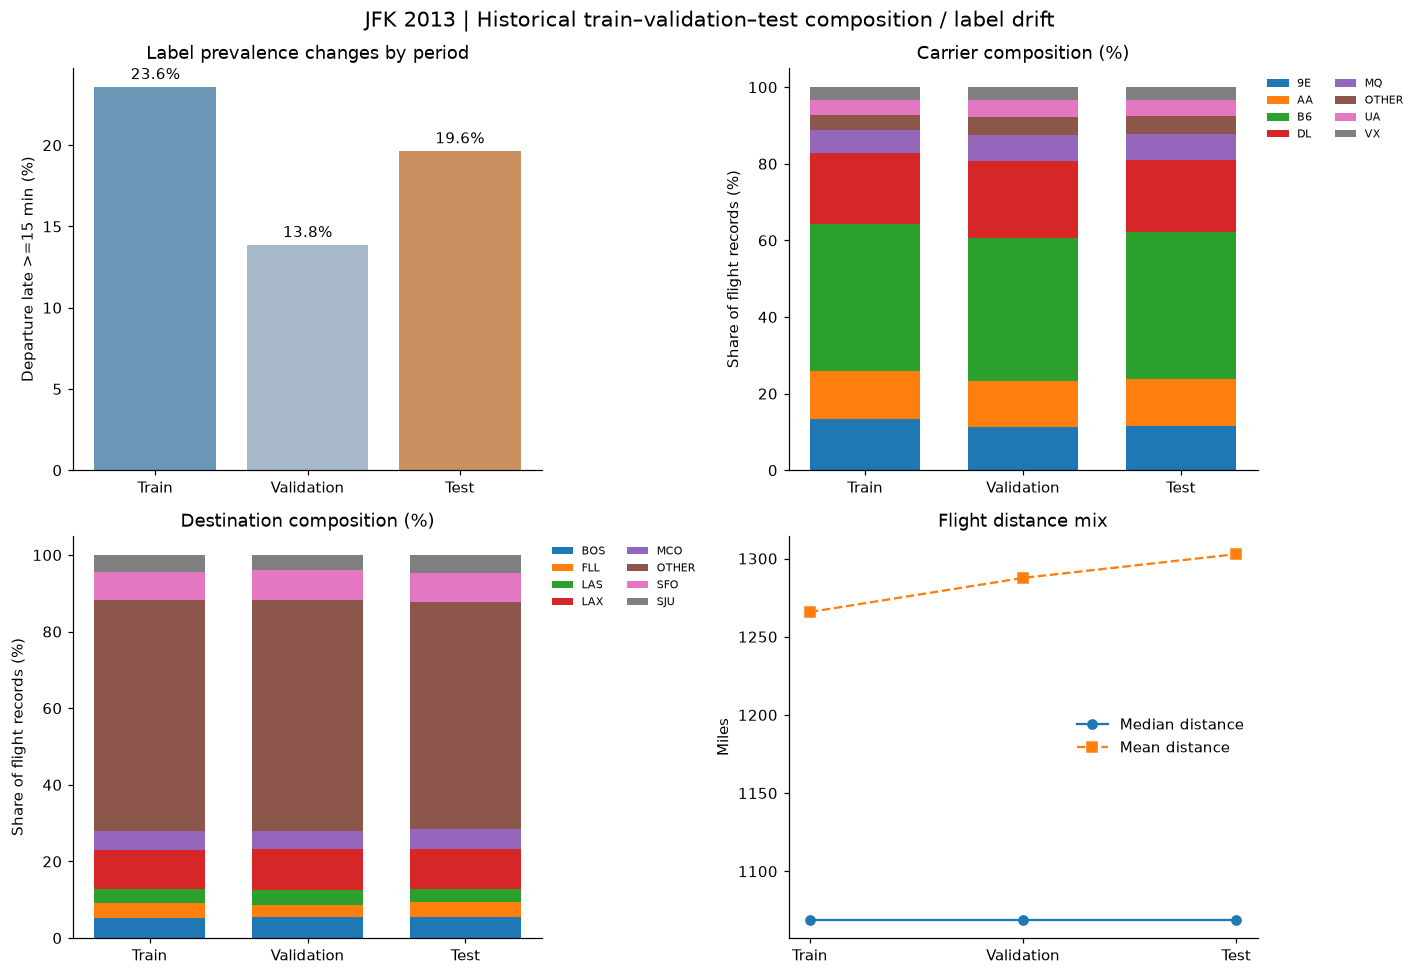

Caution: historical seasonal composition shift is not a demonstrated cause of performance change.


In [41]:
from scipy.spatial.distance import jensenshannon
split_frames={'Train (Jan–Aug)':train,'Validation (Sep–Oct)':valid,'Test (Nov–Dec)':test}
period_order=list(split_frames)
drift_profile=pd.DataFrame([{'Period':name,'N':len(part),
    'Late 15+ rate':float(part.target.mean()),
    'Distance mean (miles)':float(part.distance.mean()),
    'Distance median (miles)':float(part.distance.median()),
    'Unique carriers':int(part.carrier.nunique()),'Unique destinations':int(part.dest.nunique())}
    for name,part in split_frames.items()])
def make_mix(col,top_n):
    top=set(train[col].value_counts().head(top_n).index)
    pieces=[]
    for name,part in split_frames.items():
        labels=part[col].where(part[col].isin(top),'OTHER').fillna('UNKNOWN')
        pieces.append(labels.value_counts(normalize=True).rename(name))
    result=pd.concat(pieces,axis=1).fillna(0).T.reindex(period_order)
    return result.reindex(columns=sorted(result.columns))
carrier_mix=make_mix('carrier',7)
destination_mix=make_mix('dest',7)
# Jensen-Shannon distance (square root of JS divergence), base 2; higher = more different.
drift_divergences=[]
for group,mix in [('Carrier',carrier_mix),('Destination',destination_mix)]:
    for period in period_order[1:]:
        d=float(jensenshannon(mix.loc[period].to_numpy(),mix.loc[period_order[0]].to_numpy(),base=2))
        drift_divergences.append({'Grouping':group,'Compared with training':period,'JS distance':d})
drift_divergences=pd.DataFrame(drift_divergences)
display(drift_profile.round(4));display(drift_divergences.round(4))
fig,axes=plt.subplots(2,2,figsize=(13,9))
xx=np.arange(3);ax=axes[0,0]
vals=drift_profile['Late 15+ rate'].to_numpy()*100
ax.bar(xx,vals,color=['#6c96b5','#a7b9c8','#ca9060']);ax.set_xticks(xx,['Train','Validation','Test']);
ax.set(ylabel='Departure late >=15 min (%)',title='Label prevalence changes by period')
for idx,val in enumerate(vals):ax.text(idx,val+.5,f'{val:.1f}%',ha='center')
for ax,mix,title in [(axes[0,1],carrier_mix,'Carrier composition (%)'),(axes[1,0],destination_mix,'Destination composition (%)')]:
    bottom=np.zeros(3)
    for category in mix.columns:
        heights=mix[category].to_numpy()*100
        ax.bar(np.arange(3),heights,bottom=bottom,label=str(category),width=.7)
        bottom+=heights
    ax.set_xticks(np.arange(3),['Train','Validation','Test']);ax.set(ylabel='Share of flight records (%)',title=title)
    ax.legend(title=None,fontsize=7,ncol=2,frameon=False,loc='upper left',bbox_to_anchor=(1.0,1.0))
ax=axes[1,1];ax.plot(xx,drift_profile['Distance median (miles)'],'o-',label='Median distance')
ax.plot(xx,drift_profile['Distance mean (miles)'],'s--',label='Mean distance')
ax.set_xticks(xx,['Train','Validation','Test']);ax.set(ylabel='Miles',title='Flight distance mix');ax.legend(frameon=False)
fig.suptitle('JFK 2013 | Historical train–validation–test composition / label drift',fontsize=14)
fig.tight_layout();fig.savefig(IMAGES_DIR/'36_data_drift_composition.png',bbox_inches='tight');plt.show()
drift_profile.to_csv(RESULTS_DIR/'data_drift_profiles.csv',index=False)
drift_divergences.to_csv(RESULTS_DIR/'data_drift_js_distance.csv',index=False)
carrier_mix.to_csv(RESULTS_DIR/'data_drift_carrier_mix.csv')
destination_mix.to_csv(RESULTS_DIR/'data_drift_destination_mix.csv')
print('Caution: historical seasonal composition shift is not a demonstrated cause of performance change.')


## 39. Carrier-level calibration — expected versus observed late rates

**Question:** For each sufficiently represented carrier in the repeatedly examined Nov–Dec holdout, are the *mean predicted probabilities* close to actual late-departure frequencies?

The base model was trained Jan–Aug. Platt/Isotonic calibrators were fitted using September and chosen using October. The **raw Logistic** and **October-selected calibrated** outputs are compared without using test labels to fit them. Vertical Wilson 95% intervals represent uncertainty in the observed proportion and do **not** adjust for repeated flights/dates, model-estimation error, or multiple group comparisons. Groups with fewer than 250 test flights are excluded from the plot but not silently reweighted.


,carrier,n,observed_count,observed_rate,mean_raw,mean_calibrated,observed_lo95,observed_hi95,raw_gap_pp,calibrated_gap_pp
2,B6,6770,1540,0.2275,0.4017,0.1781,0.2176,0.2376,17.4240,-4.9398
3,DL,3306,465,0.1407,0.2936,0.1413,0.1292,0.1529,15.2922,0.0659
1,AA,2166,372,0.1717,0.2977,0.1427,0.1564,0.1882,12.5981,-2.9094
0,9E,2028,523,0.2579,0.4472,0.1944,0.2393,0.2774,18.9341,-6.3448
6,MQ,1219,247,0.2026,0.3858,0.1728,0.1810,0.2261,18.3151,-2.9804
7,UA,753,104,0.1381,0.2633,0.1311,0.1153,0.1646,12.5175,-0.6993
9,VX,582,91,0.1564,0.3314,0.1540,0.1291,0.1881,17.5089,-0.2406
8,US,567,68,0.1199,0.2296,0.1197,0.0957,0.1493,10.9631,-0.0219


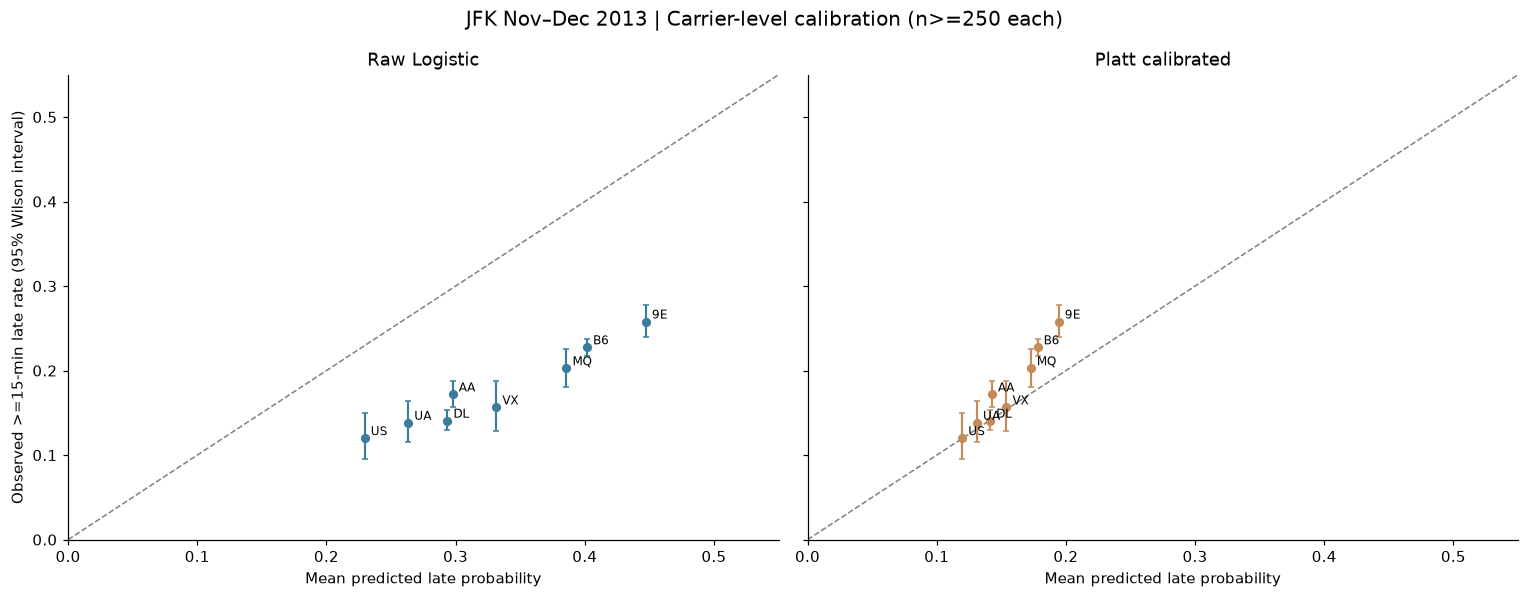

Carrier gaps reflect this historical holdout only; group-specific deployment calibration remains unverified.


In [42]:
carrier_frame=test[['carrier','flight_date']].copy()
carrier_frame['actual']=y_test.to_numpy(dtype=int)
carrier_frame['predicted_raw']=np.asarray(test_raw,dtype=float)
carrier_frame['predicted_calibrated']=np.asarray(cal_methods[cal_selected][1],dtype=float)
carrier_calibration=(carrier_frame.groupby('carrier')
    .agg(n=('actual','size'),observed_count=('actual','sum'),observed_rate=('actual','mean'),
         mean_raw=('predicted_raw','mean'),mean_calibrated=('predicted_calibrated','mean'))
    .reset_index())
carrier_calibration=carrier_calibration.loc[carrier_calibration.n>=250].copy().sort_values('n',ascending=False)
from scipy.stats import norm
zscore=float(norm.ppf(.975))
p=carrier_calibration.observed_rate.to_numpy();nn=carrier_calibration.n.to_numpy()
den=1+zscore**2/nn
center=(p+zscore**2/(2*nn))/den
half=zscore*np.sqrt((p*(1-p)+zscore**2/(4*nn))/nn)/den
carrier_calibration['observed_lo95']=center-half
carrier_calibration['observed_hi95']=center+half
carrier_calibration['raw_gap_pp']=100*(carrier_calibration.mean_raw-carrier_calibration.observed_rate)
carrier_calibration['calibrated_gap_pp']=100*(carrier_calibration.mean_calibrated-carrier_calibration.observed_rate)
display(carrier_calibration.round(4))
fig,axes=plt.subplots(1,2,figsize=(14,5.5),sharex=True,sharey=True)
for ax,predcol,title,color in [
    (axes[0],'mean_raw','Raw Logistic','#397c9b'),
    (axes[1],'mean_calibrated',f'{cal_selected} calibrated','#c48a58')]:
    ax.plot([0,1],[0,1],'--',color='gray',lw=1,label='Perfect agreement')
    ax.errorbar(carrier_calibration[predcol],carrier_calibration.observed_rate,
         yerr=[carrier_calibration.observed_rate-carrier_calibration.observed_lo95,
               carrier_calibration.observed_hi95-carrier_calibration.observed_rate],
         fmt='o',markersize=5,capsize=2,lw=1.4,color=color)
    for _,r in carrier_calibration.iterrows():
        ax.annotate(str(r.carrier),(r[predcol],r.observed_rate),xytext=(4,2),
                   textcoords='offset points',fontsize=8)
    ax.set(xlabel='Mean predicted late probability',title=title,
           xlim=(0,.55),ylim=(0,.55))
axes[0].set_ylabel('Observed >=15-min late rate (95% Wilson interval)')
fig.suptitle('JFK Nov–Dec 2013 | Carrier-level calibration (n>=250 each)',fontsize=13)
fig.tight_layout();fig.savefig(IMAGES_DIR/'37_carrier_calibration.png',bbox_inches='tight');plt.show()
carrier_calibration.to_csv(RESULTS_DIR/'carrier_level_calibration.csv',index=False)
print('Carrier gaps reflect this historical holdout only; group-specific deployment calibration remains unverified.')


## 40. Final perspective and limitations

The 2013 data show differences in departure delays across destinations, dates and carriers, but the pattern comparisons are descriptive. The models also show a modest ability to rank flights by late-departure risk. But the results do not support a live prediction service: some carrier groups have extremely high false-alarm rates, the evaluation period has been inspected more than once, and the cost exercise uses assumptions rather than observed savings.

**The weather findings need the most care.** Section 7A checks which flights could be linked using the old data. Date-boundary ambiguity removes a group with unusually frequent and severe delays. The weather associations therefore describe a **selected subset**, not all JFK departures. There is a second loss: of 108,605 clock-eligible flights, only 88,340 have both visibility and wind measurements for the main adjusted regression (Section 7B). In this 2013 copy, the missing 20,265 records came from incomplete weather measurements rather than failure to locate a report within 90 minutes. Their observed late rate (21.9%) differs from the 20.7% in the complete-weather group. The final regression sample should not be treated as representative of all recorded JFK departures. Section 20 uses the same clock-eligible cohort as Section 7 for its matching-window sensitivity checks. There is also no independently verified `sched_dep_time`, and the weather file's timezone and daylight-saving convention have not been confirmed. Adjusted odds ratios cannot fix these source-data limitations or show a causal weather effect.

The original Kaggle download and redistribution terms still need to be traced. Flight records with missing delays were excluded from delay-rate calculations, and the dataset does not identify cancellations reliably. Same-aircraft analyses only link observed JFK departures, not the full aircraft movement history.

**For future work:** obtain verified schedules and timestamp conventions first; then repeat the weather study with an independent year of data. A practical decision model would also require prespecified thresholds, realistic review costs, operating capacity and external calibration checks. The PR chart shows prevalence as the no-skill reference; the weather-clock sensitivity chart reports both effect contrasts and match coverage to avoid overreading a nearly flat curve. Until then, the notebook is best read as a retrospective analysis and a record of the methods used to assess its limits.


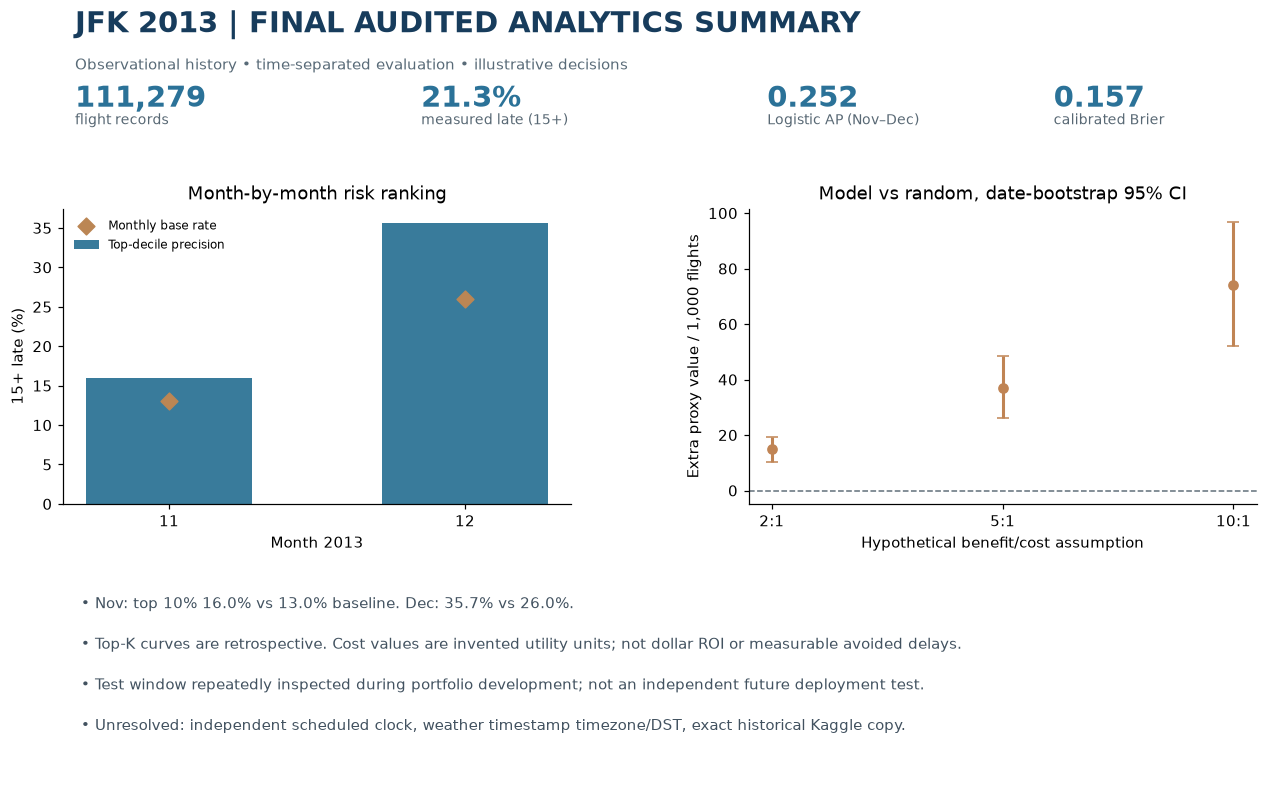

Final audit summary saved, including month-specific metrics and date-block uncertainty. (Not an operational model.)


In [43]:
# Publish one concise, data-grounded evidence summary for README and final dashboard.
monthly_summary=monthly_topk.set_index('Month')
inc=cost_uncertainty[cost_uncertainty.Method.eq('Model minus random')].set_index('Ratio')
fig=plt.figure(figsize=(14,9),facecolor='white')
import matplotlib.gridspec as gridspec
gs=gridspec.GridSpec(3,2,figure=fig,height_ratios=[.7,2,1.25],hspace=.46,wspace=.35)
ax=fig.add_subplot(gs[0,:]);ax.axis('off')
ax.text(.01,.84,'JFK 2013 | FINAL AUDITED ANALYTICS SUMMARY',fontsize=19,color='#173c5c',weight='bold',transform=ax.transAxes)
ax.text(.01,.48,'Observational history • time-separated evaluation • illustrative decisions',fontsize=10,color='#596b78',transform=ax.transAxes)
for xpos,number,title in [(0.01,f'{len(flights):,}','flight records'),(.30,f'{observed.late_15.mean():.1%}','measured late (15+)'),(.59,f'{metric_ap:.3f}','Logistic AP (Nov–Dec)'),(.83,f'{metric_brier:.3f}','calibrated Brier')]:
    ax.text(xpos,.12,number,fontsize=19,color='#2b7298',weight='bold',transform=ax.transAxes)
    ax.text(xpos,-.05,title,fontsize=9,color='#586874',transform=ax.transAxes)
ax_l=fig.add_subplot(gs[1,0]);ax_r=fig.add_subplot(gs[1,1]);xx=np.arange(len(monthly_topk))
ax_l.bar(xx,monthly_topk['Precision@10%']*100,color='#397b9b',width=.56,label='Top-decile precision')
ax_l.scatter(xx,monthly_topk.Prevalence*100,color='#bb8654',marker='D',s=60,label='Monthly base rate',zorder=3)
ax_l.set_xticks(xx,monthly_topk.Month.astype(str));ax_l.set(xlabel='Month 2013',ylabel='15+ late (%)',title='Month-by-month risk ranking');ax_l.legend(frameon=False,fontsize=8)
vals=inc.loc[list(ratios)]
ax_r.errorbar(np.arange(len(ratios)),vals.Point,yerr=[vals.Point-vals['Lower 95%'],vals['Upper 95%']-vals.Point],fmt='o',capsize=4,lw=2,color='#c08454')
ax_r.axhline(0,color='#62707b',lw=1,ls='--');ax_r.set_xticks(np.arange(len(ratios)),[f'{r}:1' for r in ratios]);ax_r.set(xlabel='Hypothetical benefit/cost assumption',ylabel='Extra proxy value / 1,000 flights',title='Model vs random, date-bootstrap 95% CI')
ax_foot=fig.add_subplot(gs[2,:]);ax_foot.axis('off')
ex=f'Nov: top 10% {monthly_summary.loc[11,"Precision@10%"]:.1%} vs {monthly_summary.loc[11,"Prevalence"]:.1%} baseline. Dec: {monthly_summary.loc[12,"Precision@10%"]:.1%} vs {monthly_summary.loc[12,"Prevalence"]:.1%}.'
lines=[ex,'Top-K curves are retrospective. Cost values are invented utility units; not dollar ROI or measurable avoided delays.',
 'Test window repeatedly inspected during portfolio development; not an independent future deployment test.',
 'Unresolved: independent scheduled clock, weather timestamp timezone/DST, exact historical Kaggle copy.']
for i,line in enumerate(lines):ax_foot.text(.015,.92-i*.22,'• '+line,fontsize=10,color='#425260',transform=ax_foot.transAxes)
fig.savefig(IMAGES_DIR/'33_executive_summary_final.png',dpi=165,bbox_inches='tight',facecolor='white');plt.show()
summary={'months':monthly_topk.to_dict(orient='records'),'cost_uncertainty':cost_uncertainty.to_dict(orient='records'),
 'holdout_repeatedly_inspected':True,'original_sched_dep_time_available':bool(schedule_audit.get('used_in_analysis',False)),
 'subgroup_error_requires_caution':True,
 'weather_audit':weather_audit.to_dict(orient='records')[0],
 'data_drift_profile':drift_profile.to_dict(orient='records'),
 'carrier_level_calibration':carrier_calibration.to_dict(orient='records')}
(RESULTS_DIR/'final_audit_metrics.json').write_text(json.dumps(summary,indent=2,default=float),encoding='utf-8')
print('Final audit summary saved, including month-specific metrics and date-block uncertainty. (Not an operational model.)')

## 41. Data sources and project scope

This portfolio project examines 2013 JFK departures using historical flight and weather records. It includes exploratory delay comparisons, weather-matching and missing-data checks, adjusted regression, chronological prediction experiments, probability calibration, and model diagnostics. Historical web-scraping examples are not executed in this version and are not presented as the source of the two CSV files.

**Tools:** pandas, NumPy, matplotlib, SciPy, statsmodels, and scikit-learn. Dependencies are listed in `requirements.txt`.

**Data provenance:** Flight records have fields consistent with the `nycflights13` family; the weather file identifies JFK station `WBAN:94789`. The exact archived Kaggle upload, weather timestamp convention, and redistribution rights for these saved copies have not been verified. The public GitHub package therefore excludes raw CSV data.

**Scope:** Findings describe recorded 2013 flights, not present-day airline operations. Weather comparisons remain observational because independent scheduled departure timestamps and verified weather timezone/DST conventions are unavailable. Predictive results are retrospective, on an evaluation period reviewed during notebook development, and are not validated for deployment.
